# Stage 2 experiment log (Dev only)

This section is the evidence for the Stage 2 comparisons quoted in the report that are not part of the final Stage 2 run above:
- the Stage 1 recipe retrained on the same machine (R),
- Role C's proposals C1 (class-weighted intent loss) and C2 (longer training),
- the per-class diagnostics, and
- the design sensitivity sweep (BiLSTM depth and width, character CNN and word dropout).

The saved Dev result files of every run were embedded by `scripts/d_build_experiment_log.py`, with their SHA-256 hashes. The cells below check the hashes and compute every table, rule outcome and figure from those files. Nothing is retrained here and **Test is never read**; Test was evaluated once, in the final Stage 2 cell above.

In [1]:
import csv, hashlib, io, json, statistics
import matplotlib.pyplot as plt

SEEDS = (42, 43, 44)
CORE_RUNS = {'R': ['results/stage2/d_stage1_ref_s42', 'results/stage2/d_stage1_ref_s43', 'results/stage2/d_stage1_ref_s44'], 'C1': ['results/stage2/d_intentcw_s42', 'results/stage2/d_intentcw_s43', 'results/stage2/d_intentcw_s44'], 'C2': ['results/stage2/d_intentcw_long_s42']}
SWEEP_RUNS = {'layers2': ['results/sweep/d_sweep_layers2_s42', 'results/sweep/d_sweep_layers2_s43', 'results/sweep/d_sweep_layers2_s44'], 'layers3': ['results/sweep/d_sweep_layers3_s42', 'results/sweep/d_sweep_layers3_s43', 'results/sweep/d_sweep_layers3_s44'], 'hidden64': ['results/sweep/d_sweep_hidden64_s42', 'results/sweep/d_sweep_hidden64_s43', 'results/sweep/d_sweep_hidden64_s44'], 'hidden256': ['results/sweep/d_sweep_hidden256_s42', 'results/sweep/d_sweep_hidden256_s43', 'results/sweep/d_sweep_hidden256_s44'], 'nochar': ['results/sweep/d_abl_nochar_s42', 'results/sweep/d_abl_nochar_s43', 'results/sweep/d_abl_nochar_s44'], 'nowd': ['results/sweep/d_abl_nowd_s42', 'results/sweep/d_abl_nowd_s43', 'results/sweep/d_abl_nowd_s44'], 'neither': ['results/sweep/d_abl_neither_s42', 'results/sweep/d_abl_neither_s43', 'results/sweep/d_abl_neither_s44']}
SWEEP_READY = True
EMBEDDED = json.loads(r"""{"built_at_utc": "2026-11-09 17:32", "files": {"results/role_d/c_analysis.json": {"sha256": "dcf008f6a1baaaab08e688655127a1312cb5021b2caf5eb664c9d5f6ea964d12", "text": "{\n  \"note\": \"Dev only; Test never read. Rules in docs/D_STAGE2_PLAN.md.\",\n  \"configs\": {\n    \"R\": \"d_stage1_ref\",\n    \"C1\": \"d_intentcw\",\n    \"C2\": \"d_intentcw_long\"\n  },\n  \"runs\": {\n    \"R\": {\n      \"42\": {\n        \"run\": \"d_stage1_ref_s42\",\n        \"intent_accuracy_pct\": 86.8666994589277,\n        \"slot_micro_f1_pct\": 80.16194331983806,\n        \"selection_score\": 83.51432138938287,\n        \"best_epoch\": 38,\n        \"epochs_run\": 46,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 86.23853211009174\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 85.91184096802074\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 54.83870967741936,\n          \"qa_factoid\": 72.82608695652173\n        }\n      },\n      \"43\": {\n        \"run\": \"d_stage1_ref_s43\",\n        \"intent_accuracy_pct\": 87.11264141662568,\n        \"slot_micro_f1_pct\": 80.8167380892362,\n        \"selection_score\": 83.96468975293094,\n        \"best_epoch\": 36,\n        \"epochs_run\": 44,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 87.1559633027523\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 86.4304235090752\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 56.994818652849744,\n          \"qa_factoid\": 76.92307692307693\n        }\n      },\n      \"44\": {\n        \"run\": \"d_stage1_ref_s44\",\n        \"intent_accuracy_pct\": 87.55533694048205,\n        \"slot_micro_f1_pct\": 81.223148850139,\n        \"selection_score\": 84.38924289531053,\n        \"best_epoch\": 37,\n        \"epochs_run\": 45,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 86.23853211009174\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 86.25756266205704\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 59.25925925925925,\n          \"qa_factoid\": 74.72527472527473\n        }\n      }\n    },\n    \"C1\": {\n      \"42\": {\n        \"run\": \"d_intentcw_s42\",\n        \"intent_accuracy_pct\": 86.7683226758485,\n        \"slot_micro_f1_pct\": 81.80904522613065,\n        \"selection_score\": 84.28868395098957,\n        \"best_epoch\": 49,\n        \"epochs_run\": 57,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 88.9908256880734\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.70181503889368\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 51.764705882352935,\n          \"qa_factoid\": 74.44444444444444\n        }\n      },\n      \"43\": {\n        \"run\": \"d_intentcw_s43\",\n        \"intent_accuracy_pct\": 86.37481554353172,\n        \"slot_micro_f1_pct\": 80.16173869092746,\n        \"selection_score\": 83.26827711722959,\n        \"best_epoch\": 33,\n        \"epochs_run\": 41,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 91.74311926605505\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.96110630942091\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 49.43820224719101,\n          \"qa_factoid\": 73.40425531914893\n        }\n      },\n      \"44\": {\n        \"run\": \"d_intentcw_s44\",\n        \"intent_accuracy_pct\": 87.06345302508608,\n        \"slot_micro_f1_pct\": 81.60080543669771,\n        \"selection_score\": 84.3321292308919,\n        \"best_epoch\": 43,\n        \"epochs_run\": 51,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 88.07339449541284\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.87467588591184\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 56.353591160220994,\n          \"qa_factoid\": 72.52747252747253\n        }\n      }\n    },\n    \"C2\": {\n      \"42\": {\n        \"run\": \"d_intentcw_long_s42\",\n        \"intent_accuracy_pct\": 86.7683226758485,\n        \"slot_micro_f1_pct\": 81.80904522613065,\n        \"selection_score\": 84.28868395098957,\n        \"best_epoch\": 49,\n        \"epochs_run\": 61,\n        \"parameters\": {\n          \"total\": 907002,\n          \"trainable\": 907002\n        },\n        \"accuracy_by_train_frequency\": {\n          \"rarest_quarter\": {\n            \"dev_support\": 109,\n            \"dev_accuracy_pct\": 88.9908256880734\n          },\n          \"most_frequent_quarter\": {\n            \"dev_support\": 1157,\n            \"dev_accuracy_pct\": 84.70181503889368\n          }\n        },\n        \"watched_intent_f1_pct\": {\n          \"general_quirky\": 51.764705882352935,\n          \"qa_factoid\": 74.44444444444444\n        }\n      }\n    }\n  },\n  \"three_seed_means\": {\n    \"R\": {\n      \"intent_accuracy_pct\": {\n        \"mean\": 87.17822593867848,\n        \"sample_sd\": 0.34897190775197146\n      },\n      \"slot_micro_f1_pct\": {\n        \"mean\": 80.73394341973776,\n        \"sample_sd\": 0.5354255432441952\n      },\n      \"selection_score\": {\n        \"mean\": 83.95608467920812,\n        \"sample_sd\": 0.43752422316257217\n      }\n    },\n    \"C1\": {\n      \"intent_accuracy_pct\": {\n        \"mean\": 86.7355304148221,\n        \"sample_sd\": 0.34548790794729356\n      },\n      \"slot_micro_f1_pct\": {\n        \"mean\": 81.19052978458528,\n        \"sample_sd\": 0.8970224569474249\n      },\n      \"selection_score\": {\n        \"mean\": 83.96303009970369,\n        \"sample_sd\": 0.6020657381706216\n      }\n    }\n  },\n  \"rules\": {\n    \"rule1_c1_gate\": 83.51432138938287,\n    \"rule1_c1_passes\": true,\n    \"rule2_c2_gate\": 84.28868395098957,\n    \"rule2_c2_passes\": false,\n    \"stage2_configuration\": \"C1\",\n    \"stage2_run\": \"d_intentcw_s42\",\n    \"rule5_mean_vs_reference_pp\": 0.00694542049556901\n  }\n}\n"}, "results/stage2/d_stage1_ref_s42/summary.json": {"sha256": "0ded1b93af48fb4b9b7e4489d3c233a67ec5beba073450e9ed2873c3446d9351", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 38,\n  \"epochs_run\": 46,\n  \"selection_score\": 83.51432138938287,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.8666994589277,\n    \"slot_micro_f1_pct\": 80.16194331983806,\n    \"slot_tp\": 1584,\n    \"slot_fp\": 356,\n    \"slot_fn\": 428\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_stage1_ref_s42.pt\",\n  \"checkpoint_sha256\": \"514a1bf58ee9f1b75277bbc6f6c8c6acc2e5cad472e94addcb94a5df6aa9c6f0\",\n  \"elapsed_seconds\": 4279.2837401,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_stage1_ref_s42/history.csv": {"sha256": "1e5ebf271dbb7183bdbd478c0d618ef80c158f31bcdb2833cc9c1a5cf2cea1a8", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.373161619277108,3.4452725003447737,0.9639445594661672,3.4284638780976087,2.308630264514899,0.559916806791355,44.71224790949336,21.060782036391792,272,299,1740,32.88651497294258,0.001,80.42153999999573,84.04972729999281\n2,2.894635940762821,1.8899360664689708,0.5023499371469251,1.8769944191724277,1.1603483189753108,0.3583230500985585,69.01131333005411,53.51089588377724,884,408,1128,61.26110460691567,0.001,99.19054680000409,183.3078356999904\n3,2.000686790666089,1.2259967310966584,0.3873450297847153,1.4266801463060954,0.8403027971214223,0.29318867459233655,77.76684702410232,62.774566473988436,1086,362,926,70.27070674904537,0.001,82.21394909999799,265.622661699992\n4,1.6344240461827657,0.9739791196896339,0.33022246324656596,1.228532131379194,0.7210104811443698,0.25376082511741205,80.81652729955731,68.39064649243467,1243,380,769,74.60358689599599,0.001,90.97066060001089,356.6688749999885\n5,1.4162478750310605,0.828381553631349,0.29393316069985576,1.1457093086726535,0.6733511569637181,0.2361790758544677,81.50516478111166,70.8743169398907,1297,351,715,76.18974086050119,0.001,92.58941329999652,449.3562879999954\n6,1.2702777684738478,0.7279618650711057,0.27115795170137097,1.02590393521355,0.5974924112855655,0.21420576196399224,83.03000491883915,73.28730748805098,1380,374,632,78.15865620344508,0.001,84.39690360000532,533.8254290999903\n7,1.1542205454004246,0.6499540083147863,0.25213326854281914,0.9719745553591221,0.5648905716092494,0.20354199187493635,85.14510575504181,74.5637228979376,1410,360,602,79.8544143264897,0.001,83.83684579998953,617.7441955999966\n8,1.0759223127768132,0.6051421848792096,0.23539006394880185,0.9849047389863779,0.5852927406374833,0.19980599917444727,84.45646827348746,74.65982028241335,1454,429,558,79.5581442779504,0.001,87.7332660999964,705.5466989999986\n9,0.9954987781458229,0.5434828438194795,0.22600796716317167,0.9194705597356386,0.5376783920753431,0.19089608383014778,85.39104771273979,76.0408483896308,1452,355,560,80.7159480511853,0.001,83.31562429999758,788.8917471000022\n10,0.9332118215730669,0.5100225517686423,0.21159463490221234,0.900552876067642,0.5330032929374969,0.18377479156507256,85.83374323659616,76.24251886546969,1465,366,547,81.03813105103293,0.001,84.34875109999848,873.3181235999946\n11,0.8749631764168573,0.46944700480956925,0.202758085803644,0.9034037417303249,0.5376046683128045,0.1828995367087602,85.63698967043777,77.00729927007299,1477,347,535,81.32214447025538,0.001,89.91151719998743,963.3035633999971\n12,0.8282274825057465,0.44137578725359267,0.1934258476260769,0.8841068828449625,0.5290803158746467,0.17751328348515796,85.68617806197737,77.00534759358288,1512,403,500,81.34576282778013,0.001,88.83158289999119,1052.2176065999956\n13,0.7953535885605345,0.4247207599359605,0.185316414312287,0.8980507866673615,0.5443963066322488,0.17682724001755637,85.68617806197737,78.37136929460581,1511,333,501,82.0287736782916,0.001,86.13404449999507,1138.4239253999986\n14,0.7357547281812145,0.38003828054669625,0.17785822381725913,0.880038572694111,0.5304627641339168,0.1747879042800971,85.93212001967535,78.31698502839443,1517,345,495,82.1245525240349,0.001,88.31960750000144,1226.8327015999967\n15,0.7115191999456683,0.3689289447518714,0.17129512759689847,0.8604044038653875,0.5166902148072731,0.17185709452905726,86.8175110673881,77.68295836565814,1502,353,510,82.25023471652312,0.001,91.85227810000652,1318.7657859000028\n16,0.6799501594921034,0.34794758756437794,0.16600128596386274,0.8746467666734308,0.5331674027900302,0.1707396819417003,86.17806197737335,78.24765763484426,1545,392,467,82.21285980610881,0.001,91.82144580000022,1410.6650542999996\n17,0.6506537268498006,0.3246567762827778,0.1629984752835114,0.8696902627634029,0.5307032087432065,0.16949352701009815,86.42400393507133,79.77383705988179,1552,327,460,83.09892049747656,0.001,86.23856300000625,1496.9325106999895\n18,0.6233209461938368,0.3075554507959421,0.15788274769894736,0.8732824531130995,0.5396351159879625,0.16682366856256847,85.78455484505656,78.76309736774853,1541,360,471,82.27382610640254,0.001,86.58695140000782,1583.5990615999908\n19,0.6013356774616503,0.297874931703534,0.15173037287905816,0.8779578280536741,0.5426373221401621,0.16766025295675596,86.27643876045254,78.89536356726627,1557,378,455,82.5859011638594,0.001,85.27512120000029,1668.9014358999993\n20,0.5751004937963675,0.28302356118809663,0.14603846630413544,0.8786445493337309,0.546292166139947,0.16617619159689198,86.03049680275456,79.20892494929006,1562,370,450,82.61971087602231,0.001,86.53854399999545,1755.4667812999978\n21,0.526193945165209,0.249539960149222,0.13832699250799352,0.8711868997474519,0.5395035065868132,0.16584169658031936,86.22725036891293,79.29895859791719,1561,364,451,82.76310448341506,0.0005,88.35736409999663,1843.8533859000017\n22,0.5203110546079573,0.24870663888549274,0.1358022078612323,0.8662989082406973,0.5384591154669871,0.16391989638685514,86.6207575012297,79.79643765903307,1568,350,444,83.2085975801314,0.0005,85.32081060000928,1929.2017706999904\n23,0.5176164647244015,0.24617530509832108,0.1357205798130402,0.8810001384518973,0.5505736126315693,0.16521326291016394,86.57156910969012,79.29984779299848,1563,367,449,82.9357084513443,0.0005,86.07310029999644,2015.3529435999953\n24,0.4830021779257847,0.22581921287226517,0.12859148252675975,0.8581032053174316,0.5317638090427321,0.16316969813734972,86.52238071815052,80.20356234096693,1576,342,436,83.36297152955872,0.0005,86.05103689999669,2101.433299700002\n25,0.4742690260107328,0.21724334019059127,0.12851284291007076,0.8814313344031066,0.5477898717806131,0.16682073131124675,86.22725036891293,79.61313311275134,1564,353,448,82.92019174083214,0.0005,88.64929720001237,2190.162761799991\n26,0.4820419139911889,0.22518189708785255,0.1284300084516682,0.8894675508203467,0.5593484553924876,0.16505954771392958,86.6699458927693,79.88855116514691,1577,359,435,83.2792485289581,0.0005,85.82319099998858,2276.0141704999987\n27,0.4561928778963582,0.20817464537270183,0.1240091162618282,0.8893162292216461,0.5579632849629971,0.16567647212932451,86.32562715199212,79.67603138445963,1574,365,438,83.00082926822589,0.0005,94.24547999999777,2370.283754899996\n28,0.4438198018195292,0.19970423396271053,0.12205778392840931,0.871579033827926,0.5444219437245952,0.1635785450516654,86.71913428430891,80.09153318077803,1575,346,437,83.40533373254347,0.00025,89.23153019999154,2459.540629199997\n29,0.44238398392647715,0.20257007284712747,0.11990695553967486,0.8732729982201483,0.5476661481355366,0.16280342504230583,86.52238071815052,80.14166455856312,1584,357,428,83.33202263835682,0.00025,94.04982179999934,2553.6854802000016\n30,0.43007720528137794,0.1935072313358081,0.11828498697278492,0.8786836526091523,0.5466640442389897,0.16600980418508127,86.37481554353172,79.64467005076142,1569,359,443,83.00974279714657,0.00025,98.20840190000308,2651.9233884999994\n31,0.43053573391617017,0.19280028498502,0.1188677244655751,0.8855539876571036,0.5561926063503823,0.16468069065336066,86.47319232661091,80.17176054559232,1587,360,425,83.32247643610162,0.00025,101.15579030000663,2753.104486899989\n32,0.42007366065154017,0.1885388839031562,0.11576738837419197,0.8756020186979003,0.546140106921705,0.16473095588809764,86.6207575012297,80.22397556630186,1576,341,436,83.42236653376578,0.000125,106.99898350000149,2860.140405699989\n33,0.4156845613828021,0.183353993821024,0.11616528378088906,0.8771827323440258,0.5500865120988612,0.1635481101225823,86.6207575012297,80.30379746835443,1586,352,426,83.46227748479207,0.000125,103.46141789999092,2963.6786876999977\n34,0.40665719469521344,0.17186631882213482,0.11739543793653931,0.8757250406350292,0.5495038048950135,0.16311061787000786,86.6699458927693,79.93943981831946,1584,367,428,83.30469285554437,0.000125,107.26267680000456,3071.015494799998\n35,0.4256184815736831,0.19353844008761312,0.116040020743035,0.8755330012682028,0.5487390120394172,0.1633969946143928,86.8175110673881,80.08119766556712,1578,351,434,83.4493543664776,0.000125,107.3925961000059,3178.4351270999905\n36,0.40597579751948987,0.1746273630295277,0.11567421724498107,0.8784970950795539,0.5512502992088667,0.16362339793534356,86.6207575012297,79.9493670886076,1579,359,433,83.28506229491865,0.000125,104.60567669999728,3283.0744749000005\n37,0.40361751795425543,0.17638805383854864,0.1136147320578534,0.8803196946132661,0.5533485539253862,0.16348557034393996,86.71913428430891,80.1615345784957,1588,362,424,83.4403344314023,6.25e-05,104.57291119999718,3387.6855816000025\n38,0.39853398513354665,0.16649826235172338,0.11601786139091162,0.8800254434693451,0.5537073231071776,0.16315906018108373,86.8666994589277,80.16194331983806,1584,356,428,83.51432138938287,6.25e-05,104.45055679998768,3492.161499099995\n39,0.40157520262574486,0.17598241123449934,0.11279639569562276,0.8786201465113366,0.5515626123018353,0.16352876710475064,86.8666994589277,80.1114770711933,1581,354,431,83.4890882650605,6.25e-05,104.82969620000222,3597.0741082999884\n40,0.3965208219670595,0.16942194683468548,0.113549437566187,0.8801167387775547,0.5531777069009236,0.16346951593831555,86.8175110673881,79.80793530452362,1579,366,433,83.31272318595586,6.25e-05,107.37004569999408,3704.472137399993\n41,0.3923664084109554,0.16907147995109087,0.11164746422993224,0.8833709494835011,0.5562024161080333,0.1635842666877339,86.8666994589277,80.07072493053802,1585,362,427,83.46871219473286,6.25e-05,104.76384759999928,3809.2659724999976\n42,0.3975375046962405,0.17547925222203697,0.11102912623710175,0.8812664915318589,0.5538410171756473,0.16371273717810578,86.6699458927693,80.10126582278481,1582,356,430,83.38560585777705,3.125e-05,105.33515319999424,3914.6456215999933\n43,0.3977375176736991,0.17275952580531315,0.11248899593419297,0.8806208228663255,0.5539668599666777,0.1633269814498239,86.6699458927693,80.01010866818297,1583,362,429,83.34002728047614,3.125e-05,107.49387280001247,4022.1653020999947\n44,0.39253853708451464,0.1729396247027213,0.10979945619089666,0.8827970231999451,0.5559094359120652,0.16344379364393993,86.6699458927693,80.01010866818297,1583,362,429,83.34002728047614,3.125e-05,98.1631214999943,4120.399391799991\n45,0.3832031427303908,0.16443727316491116,0.10938293478273983,0.8814688487080701,0.5547831226204395,0.1633428630438153,86.71913428430891,80.0808897876643,1584,360,428,83.4000120359866,1.5625e-05,86.64368839999952,4207.067850899999\n46,0.40276874417301267,0.17887764932050335,0.11194554742625466,0.8827836827187543,0.5559245619466606,0.1634295603860468,86.71913428430891,79.9696893154837,1583,364,429,83.3444117998963,1.5625e-05,70.1644793000014,4277.258228399995\n"}, "results/stage2/d_stage1_ref_s43/summary.json": {"sha256": "e71c2b080f8d28d36cfb19683bb23e47dfa19408a8faf9c60d8caf75aae9eca7", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 36,\n  \"epochs_run\": 44,\n  \"selection_score\": 83.96468975293094,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.11264141662568,\n    \"slot_micro_f1_pct\": 80.8167380892362,\n    \"slot_tp\": 1603,\n    \"slot_fp\": 352,\n    \"slot_fn\": 409\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_stage1_ref_s43.pt\",\n  \"checkpoint_sha256\": \"d6840d479d98937c7f86d44a2f1d949724af8ccf416c58a5bfa0f69ca01dfa80\",\n  \"elapsed_seconds\": 4131.8537867999985,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_stage1_ref_s43/history.csv": {"sha256": "0aa7f4fd4a7fabdd1c46b71509400eed61579dd9fa3479a50c1c78900fabcd80", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.432652839604923,3.4706705718564765,0.9809911338742233,3.5370875270042212,2.401887359844307,0.567600083579957,39.055582882439744,22.143139580862,280,237,1732,30.599361231650875,0.001,82.71541279999656,86.50116569999955\n2,2.9646359489420755,1.9438118662129307,0.5104120413645723,1.9473025407961508,1.2166177568562324,0.3653423919699592,68.76537137235613,52.99625468164794,849,343,1163,60.880813027002034,0.001,101.35582250000152,187.92689409999002\n3,2.02427179907785,1.2441531110600876,0.39005934400888115,1.4409289369459573,0.8592329245744171,0.2908480061857701,76.586325627152,63.98390342052314,1113,354,899,70.28511452383756,0.001,85.61495170000126,273.6178144999867\n4,1.6604612674482322,0.991069887793062,0.334695689827585,1.2468282545526392,0.7364807382218661,0.25517375816538657,81.11165764879489,67.64539808018068,1198,332,814,74.37852786448778,0.001,95.93624710000586,369.63263839999854\n5,1.4525337557205025,0.8484541939554352,0.30203978088253364,1.1137544173531313,0.660134740023559,0.22680983866478616,82.58730939498278,71.88592951304815,1336,369,676,77.23661945401547,0.001,98.81584900000598,468.5286463999946\n6,1.2842318438145566,0.7394846923984503,0.27237357570805315,1.0489167701731137,0.6150980929230682,0.2169093386250228,83.76783079193311,73.68137782561894,1369,335,643,78.72460430877602,0.001,87.20997089998855,555.8132578999939\n7,1.1889791074996041,0.6758820028671151,0.2565485523162445,1.0046318610696832,0.5934776450634237,0.20557710800312973,84.84997540580423,74.77619799894681,1420,366,592,79.81308670237553,0.001,89.71121039999707,645.6002569999982\n8,1.0861311894539976,0.5977888539658667,0.24417116774406541,0.9701628707189458,0.5702740251285011,0.19994442279522234,84.60403344810625,75.11961722488039,1413,337,599,79.86182533649333,0.001,89.37028189998819,735.0539737999934\n9,1.0227274357089775,0.5650625281891352,0.22883245375992117,0.9314222536319647,0.5511806284448987,0.19012081259353303,85.243482538121,76.26499739175796,1462,360,550,80.75423996493947,0.001,85.92794039999717,821.0560437999957\n10,0.9396752485955218,0.5045208469620798,0.217577200816721,0.9150196616680559,0.5445285868421893,0.18524553741293331,85.39104771273979,77.09034429200103,1489,362,523,81.24069600237041,0.001,88.72747939999681,909.8608338999911\n11,0.8749112408441138,0.46092454687638357,0.20699334698386507,0.9045880948064859,0.545770838409589,0.17940862819844852,85.243482538121,77.26809378185526,1516,396,496,81.25578815998813,0.001,93.32713160000276,1003.2925372999889\n12,0.8514444278700323,0.4482521633110424,0.20159613227949494,0.8817153937873683,0.5286085782705476,0.1765534077584103,86.03049680275456,77.89799072642967,1512,358,500,81.96424376459211,0.001,89.05508949999057,1092.417539499991\n13,0.7980699888207249,0.421732053463505,0.18816896767860994,0.8906962521634575,0.5381507015087542,0.17627277532735164,85.53861288735858,78.06652806652806,1502,334,510,81.80257047694332,0.001,88.62385679999716,1181.1213247999985\n14,0.7602836640556401,0.3952784734569905,0.18250259529932475,0.8808075073850868,0.5318648760036125,0.17447131569073715,86.17806197737335,77.93354101765317,1501,339,511,82.05580149751326,0.001,92.18397260000347,1273.3355330999912\n15,0.7247445367714007,0.37277579667855204,0.1759843700464243,0.8826086948269414,0.5413590157729795,0.17062483952698096,85.88293162813576,78.43638221768012,1535,367,477,82.15965692290794,0.001,97.93713710000156,1371.3583589999907\n16,0.6829822009459516,0.34401853899999646,0.16948183097297762,0.8824290456797192,0.5424025205339168,0.1700132625729012,86.07968519429414,78.21401077752117,1524,361,488,82.14684798590766,0.001,89.70914370000537,1461.1526153999876\n17,0.6474576414806613,0.3179919768150055,0.1647328323328279,0.8838521069793661,0.5442877101945103,0.1697821983924279,86.6207575012297,79.20040485829959,1565,375,447,82.91058117976465,0.001,86.48626850001165,1547.66690679999\n18,0.63172210842776,0.31362667381090487,0.15904771730842757,0.8935210795118426,0.5537780129845015,0.16987153326367055,86.47319232661091,78.07623433103096,1526,371,486,82.27471332882094,0.001,89.48233050000272,1637.2079820999934\n19,0.5963059486061704,0.28505794969266834,0.15562399945675098,0.8707469189759138,0.540705077588353,0.16502092069378044,86.6699458927693,78.99896800825593,1531,333,481,82.83445695051262,0.001,86.95273479999742,1724.1899804999994\n20,0.584975539636173,0.28736295711669074,0.14880629125974112,0.8719835080520448,0.5435467760843182,0.16421836598386327,86.07968519429414,79.73489676268161,1564,347,448,82.90729097848788,0.001,91.59110930000315,1815.8085422999866\n21,0.5435331930814096,0.25584670125309616,0.14384324591415668,0.8731265888784555,0.5444189196904188,0.16435383459401837,86.91588785046729,79.76554536187564,1565,347,447,83.34071660617147,0.0005,88.29664929999853,1904.1316375999886\n22,0.5380183178533062,0.25822477608230643,0.13989677088549987,0.8775044172720483,0.5493905496198558,0.16405693382609626,86.8666994589277,79.58459979736575,1571,365,441,83.22564962814673,0.0005,87.42614500000491,1991.636743199997\n23,0.5107581820652377,0.2329419924398253,0.1389080948127062,0.8757246984684393,0.5460192203756277,0.16485273904640582,87.21101819970487,79.48979591836735,1558,350,454,83.35040705903612,0.0005,87.34794700000202,2079.012733299998\n24,0.49892544593449606,0.22958597781572446,0.13466973405938581,0.8888537492398316,0.561580414966709,0.1636366671365613,87.16182980816528,79.92975413948821,1593,381,419,83.54579197382674,0.0005,89.6030921000056,2168.6857512999995\n25,0.4843195280254018,0.2246924634399732,0.12981353229271428,0.881269257148154,0.5557104768391847,0.16277939015448462,87.06345302508608,79.91876110687991,1574,353,438,83.49110706598299,0.0005,88.2814306000073,2257.0411258999957\n26,0.48890301645667933,0.2263569612355619,0.13127302761055873,0.8729644041182302,0.5468434532229325,0.16306047544764884,86.96507624200689,79.85757884028484,1570,350,442,83.41132754114587,0.0005,92.20190499999444,2349.2692782999948\n27,0.4782074695833997,0.22196387401860435,0.12812179778239768,0.8816428295699928,0.5563214143039086,0.16266070763304213,86.8175110673881,79.71566387407971,1570,357,442,83.2665874707339,0.0005,87.1723706000048,2436.466797599991\n28,0.44912353491834134,0.19889971980912746,0.12511190755460694,0.8764281969302443,0.5515877657551163,0.16242021558756406,86.96507624200689,80.16133098058987,1590,365,422,83.56320361129838,0.00025,90.352902300001,2526.8503839999903\n29,0.4369584237994084,0.19107236088989135,0.12294303145475852,0.8894738699254665,0.566542640907449,0.16146561450900876,86.91588785046729,80.0503144654088,1591,372,421,83.48310115793805,0.00025,90.47860930000024,2617.4085007999965\n30,0.43972947155406694,0.19491036198755013,0.1224095547832584,0.89488850893346,0.5702473002000801,0.1623206043666899,87.01426463354649,79.98985544002029,1577,354,435,83.50206003678339,0.00025,94.0873697999923,2711.5223950999934\n31,0.43149159212530214,0.18994164926549803,0.12077497142990205,0.8825959280045816,0.5600220696186117,0.16128692919298496,86.96507624200689,80.60606060606061,1596,352,416,83.78556842403376,0.00025,103.50885359999666,2815.055384099993\n32,0.43814885938933334,0.19467224949698742,0.12173830494617295,0.8888297672810894,0.5661751685679633,0.16132729935656304,87.01426463354649,80.68669527896996,1598,351,414,83.85047995625823,0.00025,101.27898490001098,2916.425032599989\n33,0.4317902094153949,0.1881854049401998,0.12180240223759757,0.8874829102881938,0.5649541539625176,0.16126437816283812,87.06345302508608,80.35264483627203,1595,363,417,83.70804893067906,0.00025,101.04164309999032,3017.5337\n34,0.4098982620733872,0.1767558583539042,0.11657120185974149,0.8880294634078094,0.5672546845026575,0.16038738945257594,86.96507624200689,80.05050505050505,1585,363,427,83.50779064625597,0.00025,99.2547462000075,3116.816488899989\n35,0.4259932720681782,0.1903926562741127,0.11780030789703276,0.8979534694611198,0.57382316185932,0.16206515380089986,87.26020659124447,80.46736093472187,1584,341,428,83.86378376298316,0.00025,99.99450219998835,3216.8369434999913\n36,0.4136415243710904,0.1825722336499915,0.11553464536054946,0.8902043447136483,0.5677298228258695,0.1612372609438894,87.11264141662568,80.8167380892362,1603,352,409,83.96468975293094,0.00025,100.69390410000051,3317.6033454999997\n37,0.4186731539882741,0.18543387053636953,0.1166196417259523,0.8972701493094684,0.573446724840531,0.16191171223446865,87.21101819970487,80.49395161290323,1597,359,415,83.85248490630406,0.00025,102.16126480000094,3419.8330534999986\n38,0.4032583739252228,0.1729504961468019,0.11515393888921044,0.9011262817069868,0.5778567156531338,0.16163478302692652,87.11264141662568,80.3513174404015,1601,372,411,83.7319794285136,0.00025,101.5040391000075,3521.3792351999873\n39,0.4044492852050977,0.17558373483659825,0.11443277518424974,0.8978767508803958,0.5765070220958524,0.1606848643922717,87.16182980816528,80.48289738430583,1600,364,412,83.82236359623556,0.00025,101.36100940000324,3622.7639464999957\n40,0.39736018459743827,0.170052203656651,0.11365399047039362,0.8913075523366665,0.5701221565982126,0.16059269786922695,87.21101819970487,80.47426841574168,1595,357,417,83.84264330772328,0.000125,105.09547010000097,3727.932342699991\n41,0.3958980221456601,0.1748523737213482,0.11052282421215595,0.8945805973843233,0.572332275951665,0.1611241607163291,87.40777176586326,80.33240997229917,1595,364,417,83.87009086908122,0.000125,100.82733000000007,3828.7884529000003\n42,0.38472841510839073,0.1667943292966998,0.10896704290584548,0.8982908742359688,0.5757406605796983,0.1612751068281352,86.96507624200689,80.32249937011842,1594,363,418,83.64378780606265,0.000125,101.2989094999939,3930.1395548999863\n43,0.3806662957648984,0.16179727555480872,0.10943451010504483,0.894188656545966,0.5714135981520818,0.16138752919694208,87.11264141662568,80.42381432896065,1594,358,418,83.76822787279316,6.25e-05,104.51727250000113,4034.6857852999965\n44,0.3784083962191,0.160240136212476,0.109084130003312,0.8977565794941164,0.5754443800513872,0.16115609972136458,87.16182980816528,80.43259557344065,1599,365,413,83.79721269080297,6.25e-05,94.52340869999898,4129.283190999995\n"}, "results/stage2/d_stage1_ref_s44/summary.json": {"sha256": "cd5dbb7622428a3d934233d4589e859701fda025b4454cf7fd21edf3d2fe3fec", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 37,\n  \"epochs_run\": 45,\n  \"selection_score\": 84.38924289531053,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.55533694048205,\n    \"slot_micro_f1_pct\": 81.223148850139,\n    \"slot_tp\": 1607,\n    \"slot_fp\": 338,\n    \"slot_fn\": 405\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_stage1_ref_s44.pt\",\n  \"checkpoint_sha256\": \"a4501962154437037815bdd205fb1e8afa1a1679d945d27de33e20abcce7d4b5\",\n  \"elapsed_seconds\": 4211.556756899998,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_stage1_ref_s44/history.csv": {"sha256": "48793b6a2086d39ceedc39f40ba787faf49a62b4f854f7406fb28b64d03b792c", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.3932142586801675,3.4410954936419964,0.9760593825190854,3.407061267690562,2.2951209485325625,0.5559701595789995,43.630103295622234,22.119102861562258,286,288,1726,32.874603078592244,0.001,81.13696420000633,85.19018249999499\n2,2.881006127305404,1.8766132518403207,0.5021964377325417,1.8937565247091703,1.1718360987192764,0.36096021299494696,68.71618298081653,53.489068583408205,893,434,1119,61.10262578211237,0.001,97.69699450000189,182.9598771000019\n3,2.0284291956359817,1.2528822005820064,0.38777349752698764,1.4788962984768774,0.8839805038234487,0.29745789732671435,76.6355140186916,63.691683569979716,1099,340,913,70.16359879433566,0.001,81.41094119999616,264.4817432999989\n4,1.659235238233573,0.9931362291912207,0.3330495045211762,1.278636454652829,0.764650131878569,0.25699316138713,79.78357107722577,68.73115922170457,1254,383,758,74.25736514946517,0.001,90.69285930000478,355.2478876999958\n5,1.4167533005506936,0.8201764242421717,0.29828843815426087,1.1289969806598252,0.6620357802391521,0.23348060021033654,81.75110673880964,71.44420131291028,1306,338,706,76.59765402585995,0.001,93.9812557999976,449.32153599998855\n6,1.289054142283441,0.745558469353895,0.27174783646477296,1.056126870917152,0.6203410415536831,0.2178929146817345,83.22675848499755,72.4723645187382,1344,353,668,77.84956150186787,0.001,85.94639090000419,535.3368008999969\n7,1.1739164586502882,0.6649315789152976,0.2544924398674953,1.0132694094136627,0.6056641148512315,0.20380264728121558,83.8662075750123,74.43850267379679,1392,336,620,79.15235512440455,0.001,84.02577300000121,619.4398686999921\n8,1.081779155771944,0.6013787420172441,0.24020020687735003,0.9493611568312638,0.5650752607496631,0.19214294804080034,85.04672897196262,76.32268203247774,1457,349,555,80.68470550222018,0.001,88.6544075999991,708.1624759999977\n9,1.005754982238103,0.5573763817533222,0.22418930024239037,0.9428255429459249,0.5615060682432791,0.19065973735132288,84.89916379734383,76.11749680715198,1490,413,522,80.50833030224791,0.001,82.74811859999318,791.0188615999941\n10,0.9438813922476315,0.5177015144211645,0.21308993891323347,0.9281156651897267,0.5524751332025486,0.18782026599358903,85.73536645351697,76.50444793301936,1462,348,550,81.11990719326818,0.001,84.16071969999757,875.2059683999978\n11,0.8949549899625746,0.4846154672312244,0.2051697613656751,0.9078844388535325,0.5416494060840973,0.18311751638471765,85.83374323659616,76.44628099173553,1480,380,532,81.14001211416584,0.001,90.08916400000453,965.368080100001\n12,0.831611173224013,0.4375995408542375,0.19700581618488772,0.9035816666185841,0.5471066354356607,0.1782375155914617,85.53861288735858,78.03617571059432,1510,348,502,81.78739429897645,0.001,88.49401089998719,1053.9447179999988\n13,0.789367166632742,0.4130065362859729,0.18818031517338454,0.890941776157425,0.542868908320632,0.17403643391839652,85.68617806197737,77.95477903391573,1517,363,495,81.82047854794655,0.001,87.5305015000049,1141.5555151000008\n14,0.7518338105714749,0.3894672395455375,0.1811832855129687,0.8998412479069977,0.5504061173055773,0.1747175653007102,85.3418593212002,77.8268780868209,1497,338,515,81.58436870401056,0.001,88.68237569999474,1230.320524499999\n15,0.712126070483845,0.36486676046992,0.17362965500696254,0.8784455239212805,0.5363015748571424,0.17107197453206904,86.03049680275456,78.43442198030067,1513,333,499,82.23245939152761,0.001,92.91912910000246,1323.2697780000017\n16,0.6981695095213356,0.35982894334234833,0.1691702830894936,0.8775553446498465,0.5374604617792927,0.1700474414352769,85.63698967043777,78.32238504295098,1550,396,462,81.97968735669437,0.001,90.44048600000679,1413.8026833999902\n17,0.6362157401816122,0.3171140876353895,0.15955082627311135,0.8766109713027523,0.5390633819024667,0.16877379470014278,86.42400393507133,79.32098765432099,1542,334,470,82.87249579469616,0.001,84.40754529999685,1498.2377517999994\n18,0.6361318331515651,0.319797203982686,0.15816731458443953,0.8731214017947448,0.53095112935229,0.17108513622122737,86.57156910969012,79.32098765432099,1542,334,470,82.94627838200554,0.001,85.83334839998861,1584.1487193999928\n19,0.6080196333150159,0.2996968812612852,0.1541613760268653,0.8643932914282745,0.5342699140969955,0.16506168866563947,86.57156910969012,79.37310414560162,1570,374,442,82.97233662764586,0.001,85.52287519999663,1669.7496309999988\n20,0.5847625360276543,0.2863508213181369,0.1492058573547587,0.8918693117344949,0.5478099972170911,0.17202965725870192,86.27643876045254,79.66101694915254,1551,331,461,82.96872785480254,0.001,85.5487892999954,1755.3647869999986\n21,0.5513968189713933,0.26589629909779766,0.1427502599367978,0.8783712171037578,0.5487376652617673,0.16481677592099525,86.12887358583374,80.28673835125448,1568,326,444,83.20780596854411,0.001,89.37140069999441,1844.7662476999976\n22,0.5320195833990424,0.25210438148209635,0.13995760095847304,0.874273153637873,0.5475080049630169,0.163382574337428,86.6699458927693,79.53275774504824,1566,360,446,83.10135181890877,0.001,86.32998530000623,1931.1746473999956\n23,0.5227128683232048,0.2521530166773078,0.13527992582294854,0.8701198547773644,0.5450765651490849,0.16252164481413978,86.52238071815052,79.8978288633461,1564,339,448,83.21010479074832,0.001,85.86297030000424,2017.07086729999\n24,0.5014197975857608,0.2369620897340468,0.132228853925857,0.9030662124485429,0.5701193922092571,0.1664734101196429,86.17806197737335,79.9092513234182,1585,370,427,83.04365665039577,0.001,86.51340830000117,2103.659875700003\n25,0.4666007822821263,0.2164121310247488,0.12509432562868875,0.8956445904663449,0.5673262966247948,0.16415914692077505,86.57156910969012,80.35398230088495,1589,354,423,83.46277570528753,0.0005,88.0804291000095,2191.766787899993\n26,0.4513269105451816,0.2049388700378879,0.12319402025364684,0.8864831972191158,0.5621371166024721,0.1621730403083219,86.6207575012297,80.62960142168063,1588,339,424,83.62517946145516,0.0005,86.0382646000071,2277.8808853999944\n27,0.4488983539619417,0.2041364941349331,0.12238092991350431,0.8884902530385631,0.5624121099754442,0.16303907153155944,86.8175110673881,80.41393235739525,1593,357,419,83.61572171239168,0.0005,93.59877830000187,2371.5525146\n28,0.43426805312908184,0.1954358561038557,0.11941609851261308,0.890959947780538,0.5627252193606668,0.1641173642099356,87.01426463354649,80.86294416243655,1593,335,419,83.93860439799153,0.0005,87.81560440000612,2459.395621699994\n29,0.4215781487508594,0.18925555333797978,0.1161612977064398,0.9013900019437338,0.5738912393351348,0.16374938130429953,86.57156910969012,80.90794451450189,1604,349,408,83.739756812096,0.0005,93.633908600008,2553.122141999993\n30,0.41087013843028813,0.18438933329261673,0.1132404025688357,0.8957587121732413,0.5711621194418228,0.16229829636570922,86.6207575012297,80.55837563451777,1587,341,425,83.58956656787373,0.0005,97.8359952000028,2650.9856538999884\n31,0.4053985626294873,0.18465484161850726,0.11037186050549003,0.9013428035951994,0.5732408409568985,0.16405098131915044,86.6207575012297,80.95358863809282,1596,335,416,83.78717306966126,0.0005,101.91868689999683,2752.9315953999903\n32,0.3881198711406949,0.1704032725916775,0.10885829927450869,0.8997884047876872,0.5758252791213802,0.16198156283315351,86.71913428430891,81.40065973103273,1604,325,408,84.05989700767083,0.00025,107.98070060000464,2860.945065699998\n33,0.38681682119209476,0.17241315086289208,0.10720183516460134,0.8893689040668851,0.5659595933736866,0.16170465534659925,87.40777176586326,81.00177080698204,1601,340,411,84.20477128642264,0.00025,108.16646759999276,2969.2462371\n34,0.3733855371759815,0.1602879026521302,0.10654881726192565,0.8917242918324809,0.5701841060246262,0.16077009290392735,87.16182980816528,81.04970981579612,1606,345,406,84.10576981198071,0.00025,107.54351740000129,3076.863430199999\n35,0.38273990337967306,0.16987720721501412,0.10643134808232947,0.8998395211696353,0.5770159787986294,0.16141177118550296,87.06345302508608,81.20111026999747,1609,342,403,84.13228164754177,0.00025,105.46370639999805,3182.3816245999915\n36,0.38191921759026204,0.16990842587504304,0.1060053958576095,0.9005209332826491,0.5757029963079134,0.16240896848736786,86.8175110673881,81.21673003802282,1602,331,410,84.01712055270545,0.00025,103.8731320000079,3286.2801151999884\n37,0.3615150459464017,0.15358056565715927,0.1039672401446212,0.8918731266829065,0.5677088933570362,0.16208211666293515,87.55533694048205,81.223148850139,1607,338,405,84.38924289531053,0.000125,104.07141240000783,3390.3746377999923\n38,0.3677069090830758,0.16160122486210252,0.10305284211048664,0.8985281508319174,0.5755144479060138,0.16150685146295177,87.01426463354649,81.30653266331659,1618,350,394,84.16039864843154,0.000125,106.10710980001022,3496.568796099993\n39,0.358552995987068,0.15291622237072486,0.10281838680817157,0.8957524927593097,0.5718545439908261,0.16194897438424175,87.45696015740285,81.1164194116168,1613,352,399,84.28668978450983,0.000125,104.29754410000169,3600.929398799999\n40,0.36649582721479135,0.15698577882681578,0.10475502419398779,0.8970324863404958,0.5719744810844605,0.16252900262801767,87.35858337432366,81.10831234256926,1610,348,402,84.23344785844645,0.000125,106.71844270000292,3707.672692699998\n41,0.3580398743418326,0.15217268955630936,0.1029335923927616,0.8936822766070971,0.570144033408552,0.16176912159927254,86.96507624200689,80.86824835941444,1602,348,410,83.91666230071067,6.25e-05,106.87424689999898,3814.577220299994\n42,0.3562451576398935,0.15445417390425462,0.10089549186781945,0.895391348264287,0.5709166927872417,0.1622373277385227,87.06345302508608,81.27991937515748,1613,344,399,84.17168620012177,6.25e-05,103.44136349999462,3918.044515799993\n43,0.35653282590413554,0.14882578552856365,0.10385352018778594,0.8944123366996719,0.5696704065160568,0.1623709650918075,86.96507624200689,81.2831523111897,1609,338,403,84.12411427659829,6.25e-05,106.1541916999995,4024.223328399996\n44,0.3491231256374727,0.1502634715512123,0.09942982704313019,0.8928940663548293,0.5688059769765063,0.16204404468916153,87.21101819970487,81.04970981579612,1606,345,406,84.1303640077505,3.125e-05,98.27483189999475,4122.523590600002\n45,0.3547803187783215,0.15288842904685748,0.10094594486573202,0.8947574960010782,0.5703787970179357,0.1621893494915713,87.21101819970487,81.1178247734139,1611,349,401,84.16442148655938,3.125e-05,86.91587510000682,4209.463884700002\n"}, "results/stage2/d_intentcw_s42/summary.json": {"sha256": "fbfd300464f2085ea9e26eeb7ca5f423e1ed10d5ed894f4f948c4e5ae696ca2d", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 49,\n  \"epochs_run\": 57,\n  \"selection_score\": 84.28868395098957,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.7683226758485,\n    \"slot_micro_f1_pct\": 81.80904522613065,\n    \"slot_tp\": 1628,\n    \"slot_fp\": 340,\n    \"slot_fn\": 384\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_s42.pt\",\n  \"checkpoint_sha256\": \"42a1ef8de7fea50525ee23449659bc3c8a0d83b7a0628caa20aede8b601b5818\",\n  \"elapsed_seconds\": 2612.4900217999966,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_s42/history.csv": {"sha256": "d1248fd03ff2fa6296f5c1ad1db6a926ba3475cdad5a37151433adae2800a536", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.648072154959161,3.717449521529751,0.9653113167147052,3.5074647939854557,2.394563171116519,0.5564508114344683,44.90900147565175,23.177283192632387,302,292,1710,34.04314233414207,0.001,59.4457790999877,64.08914579999691\n2,3.0778070051472337,2.071309795846785,0.5032486046502243,1.929702760725121,1.2056280925129648,0.3620373341060781,69.25725528775209,52.316244595429275,847,379,1165,60.786749941590685,0.001,73.34175320000213,137.47183640000003\n3,2.0884519962846197,1.310029458394994,0.3892112689448128,1.460583327796133,0.8730195350853376,0.2937818963553977,78.70142646335465,62.87856936832997,1090,365,922,70.7899979158423,0.001,68.4159515999927,206.03143309999723\n4,1.7042086997812116,1.0368020198650403,0.33370333995808565,1.2662398234430379,0.7507901836719879,0.2577248198855249,79.98032464338417,67.84824148435337,1225,374,787,73.91428306386877,0.001,36.9006323999929,242.9648223999975\n5,1.4548024955311774,0.8621148784810395,0.296343808525069,1.1671877839943954,0.6869606232912858,0.2401135803515548,82.09542547958682,70.52311098809854,1274,327,738,76.30926823384269,0.001,35.12616469999193,278.1764746999979\n6,1.304503507373888,0.755090575676236,0.27470646584882596,1.0459917031068318,0.6132633577000608,0.21636417270338548,83.52188883423511,73.64485981308411,1379,354,633,78.58337432365961,0.001,37.286562799999956,315.495917799999\n7,1.1785368178445412,0.6681881441265753,0.25517433685898294,1.0075868978451483,0.5861112132074794,0.21073784231883444,84.75159862272504,74.24202478249407,1408,373,604,79.49681170260956,0.001,35.487389200003236,351.0174161000032\n8,1.0903618168730702,0.6142646040128754,0.23804860643009734,1.0052564827580408,0.6017290913759636,0.20176369569103864,83.9153959665519,75.01287995878413,1456,414,556,79.46413796266802,0.001,40.07186149999325,391.16323459999694\n9,1.0137685034188288,0.5560565436281883,0.22885597989532022,0.9645949830799543,0.5779901772840118,0.19330240289797126,84.65322183964584,75.84388185654008,1438,342,574,80.24855184809296,0.001,37.82685259998834,429.00187249999726\n10,0.945646730259343,0.5172278903850525,0.21420941993714526,0.9327530809928152,0.5620867705263062,0.1853331552332545,85.243482538121,75.86028460543338,1466,387,546,80.55188357177718,0.001,42.78960650000954,471.83666610000364\n11,0.8796047223308201,0.47033562311514066,0.2046345496078397,0.9316056459305502,0.5631465883719411,0.18422952877930457,85.19429414658141,77.13697219361482,1498,374,514,81.16563317009812,0.001,42.731701099997736,514.6114132999937\n12,0.8318567805235032,0.4393577226980374,0.1962495289127329,0.9225676827274308,0.5602342445628724,0.18116671908227922,85.39104771273979,77.57916241062308,1519,385,493,81.48510506168144,0.001,43.54119329999958,558.209105300004\n13,0.7960743886585038,0.42018354632735605,0.18794542116557386,0.9316646477967958,0.5699663091866887,0.1808491693050536,85.68617806197737,77.93964620187305,1498,334,514,81.8129121319252,0.001,40.44826979999198,598.6947287999938\n14,0.7381267665196438,0.3784757716510369,0.17982549743430348,0.9051793444992957,0.5490435385903407,0.17806790295447752,85.98130841121495,78.41409691629956,1513,334,499,82.19770266375725,0.001,64.06057309999596,662.7947920000006\n15,0.7130192452494813,0.36502929220022334,0.173994976524629,0.8867705159091142,0.5405061938055501,0.173132161051782,85.98130841121495,77.7236605998462,1516,373,496,81.85248450553058,0.001,56.39096590000554,719.2988000000041\n16,0.6880242690073659,0.3515094844380124,0.16825739228467673,0.892086668294808,0.550590658211321,0.17074800504174348,86.07968519429414,78.72178544255642,1552,379,460,82.40073531842529,0.001,44.89812799998617,764.2101553999964\n17,0.6548307408561587,0.32601750826740383,0.16440661629437742,0.894785358836998,0.5495943551689783,0.17259550183400985,86.47319232661091,78.92004153686396,1520,320,492,82.69661693173744,0.001,151.1024352000095,915.4094638999959\n18,0.6263366405004964,0.30577920939704084,0.16027871555172782,0.8943731813125466,0.559310884940114,0.1675311481862163,86.32562715199212,79.5582948125321,1549,333,463,82.94196098226212,0.001,87.21278499999607,1002.7302781000035\n19,0.6047020520776412,0.2991271999657972,0.152787426055922,0.9113544536349519,0.5740929534150295,0.1686307501099612,85.73536645351697,78.92057026476579,1550,366,462,82.32796835914138,0.001,42.49323999999615,1045.277487200001\n20,0.5822176336582043,0.28458863127163264,0.14881450119328585,0.8905590371552901,0.5601315496006566,0.16521374377731676,85.88293162813576,79.37881873727088,1559,357,453,82.63087518270332,0.001,44.57955999999831,1089.8705629000033\n21,0.549345791732428,0.2611905966075071,0.14407759756246047,0.9143774694522857,0.5769174853042025,0.16872999207404157,86.52238071815052,79.53846153846153,1551,337,461,83.03042112830602,0.001,43.133654999997816,1133.020380499991\n22,0.5356106028382965,0.25554296981549124,0.14003381651140268,0.9181473080828378,0.5856686461693069,0.16623933095676546,86.37481554353172,80.0204394481349,1566,336,446,83.1976274958333,0.001,37.16228799999226,1170.2239726999978\n23,0.5335630083263465,0.2582397491997763,0.13766162956328507,0.9227476843251929,0.5873437375783099,0.1677019733734415,86.37481554353172,79.28246589186458,1569,377,443,82.82864071769815,0.001,37.69970920000924,1207.9647930999927\n24,0.49149456000646086,0.23150153729119233,0.12999651135763426,0.893740840233915,0.5654761529707639,0.16413234363157553,86.6699458927693,80.06103763987792,1574,346,438,83.36549176632361,0.001,36.56314250000287,1244.5414902000048\n25,0.4803575961263859,0.22247919662350352,0.1289391997514412,0.9131790521341832,0.5779307675490635,0.16762414229255987,86.27643876045254,80.69815195071868,1572,312,440,83.48729535558562,0.001,36.41198419999273,1280.9914061000018\n26,0.4894117429270789,0.23496892287827664,0.12722141002440113,0.9305903061830598,0.596330057970714,0.16713012410617287,85.88293162813576,80.04062976130015,1576,350,436,82.96178069471796,0.001,36.180790800004615,1317.2066793999984\n27,0.45506874106551193,0.20915652634224918,0.12295610736163137,0.926625348043035,0.5907745628713448,0.1679253925858451,85.83374323659616,80.10088272383355,1588,365,424,82.96731298021486,0.001,35.87810699999682,1353.0987534000014\n28,0.4424446485773043,0.2023027584083548,0.12007094508447476,0.9067712578175935,0.5747963269238864,0.16598746544685358,85.73536645351697,81.27853881278538,1602,328,410,83.50695263315117,0.001,35.97799099999247,1389.0920770999946\n29,0.43890082411059694,0.20486711646111988,0.11701685382473853,0.9209425413369768,0.5846318089193859,0.16815536620879545,86.27643876045254,80.62405636638148,1602,360,410,83.45024756341701,0.001,36.946952500002226,1426.0732575000002\n30,0.41304081641437157,0.18764936967465082,0.11269572336986038,0.9252061101835417,0.5876201470380221,0.1687929815727598,86.03049680275456,80.84135833755703,1595,339,417,83.4359275701558,0.001,37.01162620000832,1463.100469900004\n31,0.41558515626271086,0.19105639475510522,0.11226438075380282,0.9480995010089428,0.6131666472435466,0.16746642688269808,86.42400393507133,80.45977011494253,1610,380,402,83.44188702500693,0.001,36.82594569999492,1499.9396063000022\n32,0.38204979314544985,0.1698388082400904,0.10610549245267974,0.9227917482931869,0.5867856392060602,0.16800305454356335,86.8175110673881,81.1344644213725,1602,335,410,83.97598774438029,0.0005,36.778310699999565,1536.7312115999957\n33,0.3703859400097187,0.16055292935758203,0.10491650532606835,0.9399699939156617,0.6081479875195865,0.1659110031980376,86.17806197737335,81.09063367836404,1606,343,406,83.6343478278687,0.0005,37.7207655999955,1574.4874912999949\n34,0.3604257004403732,0.14981260137340977,0.10530654953348172,0.9282413457989838,0.5961016179069297,0.166069863946027,86.6699458927693,81.02097548647966,1603,342,409,83.84546068962447,0.0005,38.677450700008194,1613.1789793999924\n35,0.3713159854775333,0.1665010297590398,0.10240747785924675,0.9103641429367708,0.5815048317456563,0.16442965559555728,86.6207575012297,81.04014137843978,1605,344,407,83.83044943983475,0.0005,36.89232769999944,1650.0850290999952\n36,0.3426273163858442,0.14190053637499442,0.10036339000542488,0.9197528471312693,0.5891318635523055,0.16531049178948187,86.57156910969012,81.18361153262519,1605,337,407,83.87759032115765,0.00025,38.81966029999603,1688.9208748999954\n37,0.339203698907136,0.14318101903475758,0.09801133993618918,0.9239797197726948,0.5961143986907899,0.16393266054095246,86.57156910969012,81.16670857430223,1614,351,398,83.86913884199618,0.00025,41.184617099992465,1730.1195989999978\n38,0.32870872662093753,0.13271342332068678,0.09799765165012539,0.9171009607643814,0.5885177498314103,0.16429160546648555,86.47319232661091,81.27048147214519,1612,343,400,83.87183689937805,0.00025,40.80753370000457,1770.9422627000022\n39,0.32537555405501845,0.13563940341592312,0.09486807531954766,0.9187947472367783,0.5885523856125966,0.1651211808120909,86.8175110673881,80.84677419354838,1604,352,408,83.83214263046824,0.000125,41.947503200004576,1812.9041274999909\n40,0.3185251080359778,0.12775528313945064,0.09538491244826357,0.9178643849926085,0.5884337787609409,0.1647153031158338,86.71913428430891,81.40880503144655,1618,345,394,84.06396965787772,0.000125,41.67814699999872,1854.598766199997\n41,0.318732848165254,0.13316740835626154,0.09278271990449623,0.921723403464529,0.5931285069133048,0.16429744827561213,86.52238071815052,81.2720848056537,1610,340,402,83.8972327619021,0.000125,44.57675760000711,1899.214431699991\n42,0.31688893734230184,0.12955170786999903,0.09366861473615139,0.9174240292655471,0.5883254716388122,0.16454927881336745,86.6207575012297,81.41414141414141,1612,336,400,84.01744945768556,0.000125,41.293145499992534,1940.524851299997\n43,0.3154509306623545,0.12732830056097227,0.09406131505069111,0.9209744880625765,0.5917406575877973,0.1646169152373896,86.7683226758485,81.31757606235857,1617,348,395,84.04294936910352,0.000125,39.364702599996235,1979.9036933000025\n44,0.31544363243975515,0.13214483156745915,0.09164940043614798,0.9230729399095072,0.5934055514131575,0.16483369424817487,86.47319232661091,81.68304358780549,1621,336,391,84.0781179572082,6.25e-05,38.21999380001216,2018.140218600005\n45,0.30338567644616243,0.12239861345465075,0.09049353149575584,0.921252029926817,0.5921408828701576,0.1645555735283297,86.6207575012297,81.55974842767296,1621,342,391,84.09025296445134,6.25e-05,38.88892109999142,2057.072070299997\n46,0.31894207486453147,0.13315053147244252,0.09289577169604447,0.920527184556579,0.591033551121837,0.16474681671737104,86.6699458927693,81.57630522088354,1625,347,387,84.12312555682642,6.25e-05,39.94572329999937,2097.0553358000034\n47,0.31044222160882573,0.128273258549649,0.09108448152958835,0.9189951717719216,0.5891160730417292,0.16493954936509622,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,6.25e-05,45.35345189999498,2142.4470845000033\n48,0.3050151899716363,0.12468463675272182,0.09016527660945724,0.9212100349244448,0.5921828702231434,0.1645135823506507,86.6207575012297,81.53923541247485,1621,343,391,84.07999645685229,6.25e-05,48.07175189998816,2190.565287899997\n49,0.3060521646816743,0.12430755473351093,0.09087230497408169,0.926251487778461,0.5962979983532892,0.1649767447125859,86.7683226758485,81.80904522613065,1628,340,384,84.28868395098957,6.25e-05,42.35438759998942,2232.940392699995\n50,0.29948194646545423,0.12534487490772434,0.08706853577886493,0.9222375307885559,0.5920689183388563,0.16508430622484976,86.6699458927693,81.52994464016105,1620,342,392,84.09994526646517,6.25e-05,39.40466610000294,2272.384085999991\n51,0.3027386354180711,0.12230478022399618,0.09021692759703748,0.9262523479649627,0.5955601165403712,0.16534611571229574,86.6699458927693,81.7312531454454,1624,338,388,84.20059951910736,6.25e-05,39.91101319999143,2312.310807899994\n52,0.3090428014652745,0.12868063465803886,0.09018108340361781,0.9282734573906456,0.5967797753380486,0.1657468410262985,86.37481554353172,81.55974842767296,1621,342,391,83.96728198560234,6.25e-05,45.565160500002094,2357.8924117999995\n53,0.300547575897179,0.12227630713591875,0.08913563438063013,0.9230014203376791,0.5924475098031527,0.16527695526726316,86.7683226758485,81.7014850239114,1623,338,389,84.23490384987994,3.125e-05,51.373976699993364,2409.286340199993\n54,0.30973393302932795,0.12988750619235626,0.08992321341848586,0.9244001061207348,0.5936066089917215,0.16539674856450665,86.71913428430891,81.71069182389937,1624,339,388,84.21491305410413,3.125e-05,47.17022189999989,2456.474140499995\n55,0.29817068221369825,0.12301690340953216,0.08757688940208304,0.9242972053061345,0.5934235252187103,0.16543684004371204,86.6207575012297,81.7014850239114,1623,338,389,84.16112126257056,3.125e-05,49.027722099999664,2505.524283699997\n56,0.30158469381658676,0.12242932690914791,0.08957768345371943,0.9248339836295711,0.5945435847429237,0.1651451994433237,86.6207575012297,81.63059889280322,1622,340,390,84.12567819701647,1.5625e-05,54.749596399997245,2560.290385100001\n57,0.305800339586124,0.1279522204680722,0.08892405955902591,0.9246456294533566,0.5942308078302401,0.16520741081155826,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,1.5625e-05,51.272088800003985,2611.5827207999973\n"}, "results/stage2/d_intentcw_s43/summary.json": {"sha256": "18d23e314a7c436ef010675b1d7edfab89b8f5bf27489eb2cbddecc099fdfca4", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 33,\n  \"epochs_run\": 41,\n  \"selection_score\": 83.26827711722959,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.37481554353172,\n    \"slot_micro_f1_pct\": 80.16173869092746,\n    \"slot_tp\": 1586,\n    \"slot_fp\": 359,\n    \"slot_fn\": 426\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_s43.pt\",\n  \"checkpoint_sha256\": \"b7d8f747849cd7ee603f04260e371a0932d2728cccad314a4aba61d199f5b247\",\n  \"elapsed_seconds\": 3009.84304420001,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_s43/history.csv": {"sha256": "f9dcb39bc4e72e315b52f9ad571f1129f8eb0b72fdd77919b0fa11b4243d0d92", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.738578000828988,3.7674080413187547,0.9855849797551166,3.6658584349985976,2.523409733207016,0.5712243508957908,43.38416133792425,22.5,288,260,1724,32.94208066896212,0.001,78.33145919999515,83.20873779999965\n2,3.1697525726902303,2.1433685624767183,0.5131920051067561,1.9517535305960965,1.2216647946066417,0.36504436799472734,70.09345794392523,53.64647713226205,868,356,1144,61.86996753809364,0.001,67.64397999999346,150.93633700000646\n3,2.123239655504989,1.3414565101770637,0.3908915726639626,1.4759009749687046,0.8877207488188061,0.29409011307494926,76.34038366945401,63.785652549697495,1107,352,905,70.06301810957575,0.001,67.5494636999938,218.54529350000666\n4,1.724068018152606,1.0513277214518102,0.3363701483503979,1.2703586424056434,0.757947775394648,0.25620543350549774,80.47220855878012,67.80610815354441,1210,347,802,74.13915835616227,0.001,65.30952680000337,283.9068411000044\n5,1.4810248754146191,0.8752150771641495,0.3029048991252348,1.156176504232675,0.6995822242252708,0.22829714000370216,81.50516478111166,72.01723673579316,1337,364,675,76.76120075845242,0.001,69.50971539999591,353.48099779999757\n6,1.318734953480727,0.7692503719584942,0.2747422907611164,1.095746604254539,0.6596541111538461,0.2180462465503465,82.68568617806197,72.99270072992701,1350,337,662,77.83919345399448,0.001,87.4742191000114,441.0241251999978\n7,1.2076306627794793,0.6931195662463521,0.2572555482665636,1.0310628551711003,0.6164146944975771,0.20732408033676158,83.9153959665519,74.3037309511298,1414,380,598,79.10956345884085,0.001,74.98061939999752,516.0885235000023\n8,1.1075838915181737,0.6148057909129455,0.2463890503026141,0.998119193891374,0.5963192647510834,0.20089996457014533,84.16133792424988,75.09273979862215,1417,345,595,79.627038861436,0.001,72.86677990001044,589.0236246999993\n9,1.0356464489497268,0.5732959518213953,0.2311752485641658,0.9617932294919678,0.5777310743392892,0.19203107757633933,84.60403344810625,75.71391144878177,1445,360,567,80.15897244844402,0.001,73.50922200000787,662.5941669000022\n10,0.9530806298375565,0.5142916137194372,0.2193945080590596,0.9389673011440615,0.5635809675555363,0.18769316679426257,85.2926709296606,75.68128730859071,1458,383,554,80.48697911912566,0.001,73.86387279999326,736.5489425999986\n11,0.8844463038217468,0.46705990937593933,0.20869319722290375,0.935924966779958,0.5699738494527792,0.1829755586635894,85.19429414658141,76.85678073510773,1516,417,496,81.02553744084457,0.001,65.44457429999602,802.083532500008\n12,0.8614749809074036,0.4580968002364394,0.20168909033548213,0.9159831811789321,0.5617651092671903,0.17710903595587088,84.80078701426463,77.09353259469209,1496,373,516,80.94715980447836,0.001,66.29073290000088,868.4314285\n13,0.8028554774936019,0.4212236729930502,0.19081590225027584,0.9153320944720267,0.5620900973626328,0.17662099855469696,85.3418593212002,77.74017183025254,1493,336,519,81.54101557572636,0.001,76.43418179999571,944.8863343999983\n14,0.7709208924110125,0.4004583673508647,0.18523126253007388,0.8918891766908386,0.5436058133562035,0.1741416816673175,85.73536645351697,77.38589211618257,1492,352,520,81.56062928484977,0.001,67.00802290000138,1011.9637994000077\n15,0.7279237198190506,0.37380343401247745,0.17706014290328656,0.9048678564684223,0.5620330851827416,0.17141738564284034,85.48942449581898,77.94192562404483,1530,384,482,81.7156750599319,0.001,67.02888250000251,1079.0653499000036\n16,0.6888927370224915,0.347891967123077,0.17050038494970726,0.8850793358547021,0.5459562133698996,0.16956156124240124,85.243482538121,78.82352941176471,1541,357,471,82.03350597494286,0.001,66.61305689999426,1145.737590500008\n17,0.6456640260353226,0.3135171429407313,0.1660734415472956,0.9064238263535753,0.5670038484553662,0.16970998894910452,85.2926709296606,78.36942675159236,1538,375,474,81.83104884062648,0.001,65.88076569999976,1211.6721843999985\n18,0.6450724435450352,0.3249902238608939,0.16004110984207068,0.9144440460899659,0.5722690444829953,0.1710875008034853,85.44023610427939,77.87971457696229,1528,384,484,81.65997534062083,0.001,84.26516029999766,1295.9626148000098\n19,0.6056513573808142,0.2935872944316165,0.15603203147459885,0.9015788280740049,0.5693986330252824,0.16609009752436124,85.88293162813576,78.90143737166325,1537,347,475,82.39218449989951,0.001,77.946237199998,1373.938362700006\n20,0.5991795919101375,0.29697091388520175,0.1511043390124679,0.8965067104645941,0.55997724223477,0.16826473411491208,85.73536645351697,78.75700458481916,1546,368,466,82.24618551916807,0.001,71.83702269999776,1445.8341859000066\n21,0.567761909197096,0.27267436097433156,0.14754377411138225,0.8952547106680632,0.5629777643285359,0.16613847316976366,86.22725036891293,79.24528301886792,1554,356,458,82.73626669389043,0.001,74.9463015999936,1520.8076526000077\n22,0.5611600441569862,0.2756293605594393,0.14276534179877345,0.8969798212817195,0.5608105938597612,0.16808461371097913,85.78455484505656,78.84664455218167,1545,362,467,82.31559969861911,0.001,75.57538590001059,1596.4399210999982\n23,0.5317111137167305,0.24858941579622923,0.14156084896025067,0.9193005737283075,0.5797208982093311,0.16978983775948817,85.93212001967535,79.24335378323109,1550,350,462,82.58773690145321,0.001,78.61440839999705,1675.0780432000029\n24,0.5115752671987615,0.2409562590388513,0.13530950407995507,0.9423766921617723,0.6069779611841775,0.16769936548879744,85.73536645351697,79.40509200907486,1575,380,437,82.57022923129591,0.001,80.80788219999522,1755.9088522000093\n25,0.466080072066136,0.21422552865723965,0.12592727170444817,0.8962534837646787,0.5671279759930087,0.164562753885835,85.98130841121495,79.59287531806616,1564,354,448,82.78709186464056,0.0005,72.76085070001136,1828.694215399999\n26,0.4610624492558264,0.20881148630781307,0.12612548147400665,0.895216563793463,0.5660052736932517,0.16460564505010566,86.27643876045254,79.46247464503043,1567,365,445,82.86945670274147,0.0005,71.31428069999674,1900.062611500005\n27,0.45128210121371376,0.20347908915217724,0.12390150603076826,0.9037800307462711,0.5738392624430508,0.1649703841516101,86.17806197737335,79.502159004318,1565,360,447,82.84011049084567,0.0005,77.72181820000696,1977.8445238999993\n28,0.43661841854004346,0.19304405408786032,0.12178718222609156,0.9069075474755062,0.5758629431586165,0.1655223021584448,85.88293162813576,79.93928661775867,1580,361,432,82.91110912294721,0.0005,68.67136229999596,2046.541609100008\n29,0.42112099124647384,0.18373260823972568,0.11869419150337407,0.9227247695593487,0.5956588608844493,0.1635329543374497,86.07968519429414,79.86848760748609,1579,363,433,82.97408640089012,0.0005,65.52049530000659,2112.1115136000008\n30,0.43214767533307047,0.1925443690622849,0.11980165313539279,0.9317619971557065,0.6020125568763294,0.1648747201396886,85.63698967043777,79.90844354018311,1571,349,441,82.77271660531045,0.0005,65.69953610000084,2177.8827907000086\n31,0.41758432807976553,0.18369174714881098,0.11694629046547726,0.9129716293424788,0.5862738894994073,0.16334886992153577,86.22725036891293,80.02030972328002,1576,351,436,83.12378004609647,0.0005,69.04040800000075,2246.9455902000045\n32,0.42042897477369695,0.18963803475943003,0.11539547000713346,0.9342823600844383,0.6053163452917757,0.16448300739633134,85.78455484505656,79.7877716018191,1579,367,433,82.78616322343782,0.0005,77.70749210000213,2324.7071901000018\n33,0.41623951225032135,0.18464491591802257,0.11579729816614939,0.9226870683298083,0.5923344567088265,0.16517630581049092,86.37481554353172,80.16173869092746,1586,359,426,83.26827711722959,0.0005,80.64326860000438,2405.3759183000075\n34,0.3882948194315006,0.16944309860462733,0.10942586041343665,0.9263145509488854,0.5969348619914208,0.1646898444787323,86.27643876045254,79.95961635537607,1584,366,428,83.1180275579143,0.0005,73.67649460000393,2479.1096499999985\n35,0.3971215144297074,0.1765397368194702,0.1102908888051186,0.9348356672522553,0.6044589242968017,0.1651883714777268,86.03049680275456,79.89808917197452,1568,345,444,82.96429298736453,0.0005,75.26356500000111,2554.399267200002\n36,0.37996819586260927,0.1646393660934141,0.10766441488459759,0.9220094492778403,0.5919458724217526,0.1650317884280439,85.73536645351697,80.16194331983806,1584,356,428,82.94865488667752,0.0005,75.30889460000617,2629.7342049\n37,0.3893685348585855,0.17375841877082374,0.1078050580438809,0.9295854422331271,0.5986533624693143,0.16546603988190636,86.12887358583374,79.94943109987358,1581,362,431,83.03915234285367,0.00025,76.27181590000691,2706.029855200002\n38,0.35910048485690726,0.1519708710038167,0.1035648069265453,0.9327004618459809,0.6015451438779967,0.16557765898399204,86.03049680275456,79.82940291018565,1591,383,421,82.9299498564701,0.00025,83.2598896999989,2789.315856800007\n39,0.36239018764561126,0.15383615070526563,0.1042770184701728,0.9278684419855441,0.5964277990334619,0.16572032147604113,86.07968519429414,80.0903841325634,1595,376,417,83.08503466342877,0.00025,74.13043950000429,2863.4785895000095\n40,0.35215346926961616,0.1463522025026007,0.10290063338350773,0.9242988452575007,0.5940531328635678,0.16512285619696648,86.17806197737335,79.67766305716444,1582,377,430,82.92786251726889,0.000125,68.71194729999115,2932.218763500001\n41,0.3532976963726907,0.151889816379514,0.10070393999658836,0.931484537168574,0.5988391922192214,0.1663226724746763,86.07968519429414,80.2407221664995,1600,376,412,83.16020368039682,0.000125,75.65361470000062,3007.8925708000024\n"}, "results/stage2/d_intentcw_s44/summary.json": {"sha256": "27200c705980912c2f9ce47a79d3fff62f13ab5b5d3be997f3f81d112e1e0b0b", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 43,\n  \"epochs_run\": 51,\n  \"selection_score\": 84.3321292308919,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.06345302508608,\n    \"slot_micro_f1_pct\": 81.60080543669771,\n    \"slot_tp\": 1621,\n    \"slot_fp\": 340,\n    \"slot_fn\": 391\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_s44.pt\",\n  \"checkpoint_sha256\": \"9860bb080edfadcf8f9bc052dd780e5ecd405cf77df348263de5d12d547dd6ef\",\n  \"elapsed_seconds\": 3662.501460300002,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_s44/history.csv": {"sha256": "11072cee27a70dde0a3a024473829460495b601898adb9dad1622751ed079f62", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.695147986122873,3.7362401676360197,0.9794539092434265,3.5158824720023754,2.4057530460836145,0.5550647129593803,44.85981308411215,24.456114028507127,326,328,1686,34.65796355630964,0.001,83.50384999999369,88.3574443999969\n2,3.076625860839167,2.070141981640727,0.5032419395992199,1.9251849940663754,1.2011309659838736,0.3620270140412509,69.1096901131333,53.62794864138549,898,439,1114,61.36881937725939,0.001,69.01880520000122,157.44860819999303\n3,2.126123906604236,1.3472823646098806,0.3894207709971777,1.501214015122049,0.9026069847515986,0.29930351518522513,77.42252828332514,63.293360631763676,1082,325,930,70.3579444575444,0.001,67.61928309999348,225.1667335999955\n4,1.722430465318277,1.0529230199631292,0.33475372267757386,1.2891350062098723,0.77098873830815,0.2590731339508612,80.17707820954254,68.46301897167996,1245,380,767,74.32004859061125,0.001,68.2700377000001,293.49469249999675\n5,1.4603821262874477,0.8578049277232218,0.3012885992821129,1.1536581993870474,0.6871096042946413,0.2332742975462031,82.43974422036399,71.7948717948718,1316,338,696,77.1173080076179,0.001,76.28549449999991,369.82941310000024\n6,1.3150908982740848,0.7656504233636768,0.27472023745520396,1.0617403193155455,0.6288432540180527,0.21644853264874636,82.93162813575996,73.08310991957104,1363,355,649,78.0073690276655,0.001,87.66206699999748,457.56075359998795\n7,1.2027919056496312,0.6898877248388002,0.2564520904054155,1.0509332970168133,0.6366468965274269,0.20714320024469318,83.7186424003935,74.32251140327341,1385,330,627,79.02057690183346,0.001,78.63209679999272,536.2886440000002\n8,1.1050858223472675,0.6206105124397536,0.24223765495375696,0.9709298273160634,0.5821275804878981,0.19440112341408264,84.94835218888342,76.34351949420443,1449,335,563,80.64593584154392,0.001,76.95570189999125,613.3178366999928\n9,1.0199924514706713,0.5682767925524186,0.2258578294591263,0.9643922326185093,0.581907204788891,0.1912425139148091,84.50565666502705,76.31444614599285,1495,411,517,80.41005140550995,0.001,79.991932799996,693.3704381999996\n10,0.9537151108762747,0.5232991663681171,0.21520797225407876,0.9334100931909496,0.560196595536742,0.18660674882710382,85.19429414658141,77.02349869451697,1475,343,537,81.1088964205492,0.001,72.76825320000353,766.1680702000012\n11,0.9108804195463045,0.49592466712184347,0.20747787621223052,0.9137030364805142,0.5459510148363165,0.18387601082209887,86.27643876045254,76.66151468315302,1488,382,524,81.46897672180278,0.001,66.99739399999089,833.226651399993\n12,0.8448494204586735,0.44673077646427445,0.19905932199719953,0.915483466809746,0.5608037323771119,0.17733986721631706,85.53861288735858,77.93475468790136,1517,364,495,81.73668378762997,0.001,73.96495910000522,907.2802773000003\n13,0.801489850582012,0.41953897219431446,0.19097543919384882,0.9222494079599648,0.5739971884236333,0.17412610976816573,85.2926709296606,78.23847540561421,1519,352,493,81.7655731676374,0.001,77.37735249999969,984.7425619999995\n14,0.7664435158564755,0.3977882122856804,0.1843276517853976,0.9171584884164552,0.5642883035272316,0.1764350924446118,85.48942449581898,78.73114924596985,1514,320,498,82.11028687089441,0.001,70.61699599999702,1055.438716299992\n15,0.7207079370201299,0.36728590769301445,0.17671101466355774,0.8903587443613279,0.5439101386644896,0.1732243028484192,86.03049680275456,79.10718920321827,1524,317,488,82.56884300298641,0.001,68.32740779999585,1123.874190699993\n16,0.7048507887079254,0.3630022360712409,0.17092427631834223,0.8982409933028302,0.557348694170395,0.17044614956621762,85.14510575504181,78.48101265822785,1550,388,462,81.81305920663483,0.001,68.75924989998748,1192.6912062999909\n17,0.6464737656180233,0.3232970370255723,0.16158836429622547,0.8843901147677187,0.5425821563262865,0.17090397922071612,85.88293162813576,78.72559095580678,1532,348,480,82.30426129197127,0.001,80.7221300000092,1273.4380889999884\n18,0.6403512540917511,0.31941375174165415,0.16046875117504847,0.8992022363149874,0.554665865243742,0.1722681855356227,85.83374323659616,79.34866890669424,1535,322,477,82.5912060716452,0.001,85.1705476000061,1358.631635400001\n19,0.6116317115062322,0.3009589587687535,0.15533637636873934,0.8790931282895111,0.5454024278759898,0.16684535020676064,86.42400393507133,79.86832109394784,1577,360,435,83.14616251450958,0.001,75.3842896999995,1434.0949734999886\n20,0.5916410483761916,0.28845769041670016,0.1515916789797457,0.9057107504817685,0.5618110024395448,0.17194987402111186,85.88293162813576,79.66976264189887,1544,320,468,82.77634713501732,0.001,79.18897049999214,1513.3586787999957\n21,0.5553004699723597,0.267303523160899,0.14399847340573035,0.899001882568579,0.5678494219350745,0.16557623031675225,85.83374323659616,79.79591836734694,1564,344,448,82.81483080197155,0.001,80.75420589999703,1594.1383663000015\n22,0.5425360896804947,0.25886216084120983,0.14183696441964247,0.8951629254724434,0.5605667295329276,0.1672980979697579,86.47319232661091,80.64433648683202,1577,322,435,83.55876440672147,0.001,80.44393449999916,1674.6005282999977\n23,0.5279876218482538,0.2537146368353073,0.13713649250647322,0.8854014426126251,0.5506738516361445,0.16736379548824032,86.6699458927693,80.24533605928954,1570,331,442,83.45764097602942,0.001,84.20508999998856,1758.8627204999939\n24,0.5055914360171505,0.23994927007083122,0.13282108297315967,0.9082262669709475,0.5744320202858884,0.16689712334252962,86.27643876045254,80.33240997229917,1595,364,417,83.30442436637586,0.001,76.74935209999967,1835.646674699994\n25,0.49074814650909493,0.229512746909312,0.13061769979989146,0.9211294964459522,0.5870107368360408,0.16705937980495575,86.27643876045254,80.59701492537313,1593,348,419,83.43672684291283,0.001,74.3688705000095,1910.0437143000017\n26,0.4529244637296283,0.20501467894613276,0.12395489239174777,0.8902277513162828,0.5623112766248982,0.16395823734569234,86.6207575012297,80.48842533706436,1582,337,430,83.55459141914703,0.0005,82.5591887999908,1992.6384838999948\n27,0.4432911574077866,0.1999888717455232,0.1216511428311317,0.9012489157180523,0.572094340073435,0.16457728782230865,86.47319232661091,80.62642081333671,1596,351,416,83.54980656997381,0.0005,68.78141949999554,2061.4438120999985\n28,0.42706335533774076,0.18889393153363723,0.11908471190205175,0.9000292016226782,0.5700978118682576,0.1649656948772103,86.52238071815052,80.70975918884665,1592,341,420,83.61606995349858,0.0005,67.2398239000031,2128.712395999988\n29,0.4245027782051134,0.1901915997955272,0.11715558920479309,0.9094248675848443,0.5794671976208629,0.16497883498199073,86.57156910969012,80.58645096056622,1594,350,418,83.57901003512816,0.0005,70.01888529999997,2198.792833499989\n30,0.41960434570078753,0.19114523493458832,0.1142295553830996,0.8985310158129275,0.5708041336521161,0.16386344108040568,86.71913428430891,81.16899618805591,1597,326,415,83.94406523618241,0.0005,71.08351419999963,2269.9004320999957\n31,0.39908202939259396,0.1793882052931952,0.10984691204969937,0.9069658759246371,0.5764523680668656,0.16525675392888572,87.06345302508608,80.96676737160121,1608,352,404,84.01511019834365,0.0005,85.51186119999329,2355.4774772999954\n32,0.3925012355575632,0.17385478239828087,0.10932322657964116,0.9213299531015102,0.5937969568499308,0.16376649812578967,86.22725036891293,81.26582278481013,1605,333,407,83.74653657686153,0.0005,82.13324690000445,2437.692763999992\n33,0.39684290192745797,0.17886795390080884,0.10898747401332458,0.9122572682534265,0.5828012746950704,0.16472799677917804,85.88293162813576,80.82744702320888,1602,350,410,83.35518932567231,0.0005,78.99891310000385,2516.718310799988\n34,0.3747958732712832,0.16214489357037037,0.10632548985045642,0.9104254221511799,0.5812981988312983,0.16456361165994082,86.7683226758485,81.31313131313131,1610,338,402,84.0407269944899,0.0005,79.18841869999596,2595.9296807999926\n35,0.38208639697830216,0.16761824509864345,0.10723407593982934,0.9111565609892177,0.584676878826406,0.16323984108140588,86.42400393507133,80.75662042875157,1601,352,411,83.59031218191146,0.0005,75.22552009999345,2671.235580599998\n36,0.38630514405044614,0.17627344839436657,0.10501584782803979,0.9176607245460882,0.5894750798211799,0.16409282236245415,86.52238071815052,81.2246963562753,1605,335,407,83.87353853721291,0.0005,85.2671568000078,2756.5266158000013\n37,0.3605520684486925,0.15185099309033687,0.10435053767917782,0.910272917786676,0.5797857977871348,0.16524355999977058,86.96507624200689,81.65021513540876,1613,326,399,84.30764568870782,0.0005,80.71420319999743,2837.2657936999894\n38,0.3654023502647506,0.16145344062751835,0.10197445481861613,0.9218355747701519,0.5891746409820091,0.16633046689407135,86.6207575012297,81.29260287806109,1610,339,402,83.9566801896454,0.0005,75.17884930000582,2912.531365399991\n39,0.3625404122905558,0.1585587145906574,0.1019908488499492,0.9280242063744486,0.5932094686088806,0.16740736888278404,86.91588785046729,80.95597484276729,1609,354,403,83.93593134661728,0.0005,76.78099660000589,2989.341427799998\n40,0.3604799152666612,0.1570966078917434,0.10169165368745889,0.9277771220252125,0.5935204595517948,0.16712833123670884,86.96507624200689,81.029263370333,1606,346,406,83.99716980616995,0.0005,60.16781810000248,3049.538713899994\n41,0.3414190320153244,0.1459541645898201,0.09773243371275217,0.9121131021799895,0.579010868682336,0.16655111674882675,86.8666994589277,80.92835519677094,1604,348,408,83.89752732784932,0.00025,45.89158650000172,3095.445896499994\n42,0.33466623600052536,0.14272885361292595,0.09596869119379971,0.9169576662821122,0.5846706700923111,0.1661434980949005,86.96507624200689,81.367865225044,1618,347,394,84.16647073352544,0.00025,47.40870780000114,3142.8725497999985\n43,0.3381677509788949,0.14146546866509863,0.09835114115689814,0.9171145851260969,0.5848990605490816,0.16610776228850763,87.06345302508608,81.60080543669771,1621,340,391,84.3321292308919,0.00025,56.75523090000206,3199.6448698999884\n44,0.32686098871932207,0.1407914512973704,0.09303476871097584,0.9182599646428569,0.5875870591598488,0.16533645274150408,86.96507624200689,81.30204390613171,1611,340,401,84.1335600740693,0.00025,72.39069380000001,3272.0833410999912\n45,0.3289958445140103,0.14146070817247,0.09376756817077016,0.9243120013319751,0.5922432281205177,0.16603438660572872,87.06345302508608,81.54851684263448,1622,344,390,84.30598493386029,0.00025,63.63309980000486,3335.736058399998\n46,0.32894937978576,0.14206920603776488,0.09344008687399756,0.9297757020224127,0.5959849416242112,0.1668953801991007,87.01426463354649,81.06345623275647,1616,359,396,84.03886043315148,0.00025,52.43271689998801,3388.185008699991\n47,0.3274549673675354,0.13992653628987572,0.09376421553882983,0.9204575266270958,0.5877342005990962,0.16636166301399977,86.8175110673881,81.24842688144979,1614,347,398,84.03296897441894,0.000125,56.05138969999098,3444.2536622999905\n48,0.3137352686044166,0.13139252348328828,0.09117137256056415,0.9258617941214828,0.5924263797953278,0.16671770716307754,86.6699458927693,81.35849056603773,1617,346,395,84.01421822940353,0.000125,57.668969000005745,3501.9397914\n49,0.3073134014952945,0.12515813334857462,0.09107763407335993,0.9205705073037156,0.5884246368802245,0.16607293521174557,86.91588785046729,81.58554942298043,1626,348,386,84.25071863672386,0.000125,58.713565400001244,3560.6760932999896\n50,0.29770908460970635,0.12216472108061371,0.0877721817645463,0.916929832622269,0.5851383776835954,0.16589572746933676,87.01426463354649,81.27350213085987,1621,356,391,84.14388338220317,6.25e-05,48.19565639999928,3608.890368499997\n51,0.3066056012068943,0.1287779418548735,0.0889138296760104,0.9205772885382453,0.5878793593996332,0.166348964569306,86.8175110673881,81.55046564309086,1620,341,392,84.18398835523948,6.25e-05,52.59684909999487,3661.5037286000006\n"}, "results/stage2/d_intentcw_long_s42/summary.json": {"sha256": "e0f93b1bd0ac07950f237a560de81224d8913129f7df3f55e600f12103e66ddb", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 49,\n  \"epochs_run\": 61,\n  \"selection_score\": 84.28868395098957,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.7683226758485,\n    \"slot_micro_f1_pct\": 81.80904522613065,\n    \"slot_tp\": 1628,\n    \"slot_fp\": 340,\n    \"slot_fn\": 384\n  },\n  \"checkpoint\": \"checkpoints\\\\stage2\\\\d_intentcw_long_s42.pt\",\n  \"checkpoint_sha256\": \"06ea41b82fd5e0a9072cf7aabb9f3525743e1d040947ee93c1580dfdfaae22d6\",\n  \"elapsed_seconds\": 3566.276553699994,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/stage2/d_intentcw_long_s42/history.csv": {"sha256": "b1d464d49ff8fe80f4ea3a2588d62d326c87d5004d577221396ea3db7154d1d4", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.648072154959161,3.717449521529751,0.9653113167147052,3.5074647939854557,2.394563171116519,0.5564508114344683,44.90900147565175,23.177283192632387,302,292,1710,34.04314233414207,0.001,85.84865099999297,89.24338569999964\n2,3.0778070051472337,2.071309795846785,0.5032486046502243,1.929702760725121,1.2056280925129648,0.3620373341060781,69.25725528775209,52.316244595429275,847,379,1165,60.786749941590685,0.001,88.98958579999453,178.45790059999854\n3,2.0884519962846197,1.310029458394994,0.3892112689448128,1.460583327796133,0.8730195350853376,0.2937818963553977,78.70142646335465,62.87856936832997,1090,365,922,70.7899979158423,0.001,67.47990229999414,246.03551980000339\n4,1.7042086997812116,1.0368020198650403,0.33370333995808565,1.2662398234430379,0.7507901836719879,0.2577248198855249,79.98032464338417,67.84824148435337,1225,374,787,73.91428306386877,0.001,56.49761779999244,302.59767279999505\n5,1.4548024955311774,0.8621148784810395,0.296343808525069,1.1671877839943954,0.6869606232912858,0.2401135803515548,82.09542547958682,70.52311098809854,1274,327,738,76.30926823384269,0.001,64.00758489999862,366.64831000000413\n6,1.304503507373888,0.755090575676236,0.27470646584882596,1.0459917031068318,0.6132633577000608,0.21636417270338548,83.52188883423511,73.64485981308411,1379,354,633,78.58337432365961,0.001,48.94433560001198,415.6570308999944\n7,1.1785368178445412,0.6681881441265753,0.25517433685898294,1.0075868978451483,0.5861112132074794,0.21073784231883444,84.75159862272504,74.24202478249407,1408,373,604,79.49681170260956,0.001,55.48745479999343,471.2271760000003\n8,1.0903618168730702,0.6142646040128754,0.23804860643009734,1.0052564827580408,0.6017290913759636,0.20176369569103864,83.9153959665519,75.01287995878413,1456,414,556,79.46413796266802,0.001,47.46449319999374,518.7301800999994\n9,1.0137685034188288,0.5560565436281883,0.22885597989532022,0.9645949830799543,0.5779901772840118,0.19330240289797126,84.65322183964584,75.84388185654008,1438,342,574,80.24855184809296,0.001,48.41960680000193,567.1636940000026\n10,0.945646730259343,0.5172278903850525,0.21420941993714526,0.9327530809928152,0.5620867705263062,0.1853331552332545,85.243482538121,75.86028460543338,1466,387,546,80.55188357177718,0.001,45.83083059999626,613.035492199997\n11,0.8796047223308201,0.47033562311514066,0.2046345496078397,0.9316056459305502,0.5631465883719411,0.18422952877930457,85.19429414658141,77.13697219361482,1498,374,514,81.16563317009812,0.001,77.11083700000017,690.1897076000023\n12,0.8318567805235032,0.4393577226980374,0.1962495289127329,0.9225676827274308,0.5602342445628724,0.18116671908227922,85.39104771273979,77.57916241062308,1519,385,493,81.48510506168144,0.001,49.36033149999275,739.6053572999954\n13,0.7960743886585038,0.42018354632735605,0.18794542116557386,0.9316646477967958,0.5699663091866887,0.1808491693050536,85.68617806197737,77.93964620187305,1498,334,514,81.8129121319252,0.001,66.28670569999667,805.9640088000015\n14,0.7381267665196438,0.3784757716510369,0.17982549743430348,0.9051793444992957,0.5490435385903407,0.17806790295447752,85.98130841121495,78.41409691629956,1513,334,499,82.19770266375725,0.001,52.775605200004065,858.8085123999917\n15,0.7130192452494813,0.36502929220022334,0.173994976524629,0.8867705159091142,0.5405061938055501,0.173132161051782,85.98130841121495,77.7236605998462,1516,373,496,81.85248450553058,0.001,83.08038680000755,941.9717259000026\n16,0.6880242690073659,0.3515094844380124,0.16825739228467673,0.892086668294808,0.550590658211321,0.17074800504174348,86.07968519429414,78.72178544255642,1552,379,460,82.40073531842529,0.001,125.13404140000057,1067.1407372999965\n17,0.6548307408561587,0.32601750826740383,0.16440661629437742,0.894785358836998,0.5495943551689783,0.17259550183400985,86.47319232661091,78.92004153686396,1520,320,492,82.69661693173744,0.001,43.91102959999989,1111.0976962999994\n18,0.6263366405004964,0.30577920939704084,0.16027871555172782,0.8943731813125466,0.559310884940114,0.1675311481862163,86.32562715199212,79.5582948125321,1549,333,463,82.94196098226212,0.001,44.30903769998986,1155.4527301999915\n19,0.6047020520776412,0.2991271999657972,0.152787426055922,0.9113544536349519,0.5740929534150295,0.1686307501099612,85.73536645351697,78.92057026476579,1550,366,462,82.32796835914138,0.001,45.43300059999456,1200.936907700001\n20,0.5822176336582043,0.28458863127163264,0.14881450119328585,0.8905590371552901,0.5601315496006566,0.16521374377731676,85.88293162813576,79.37881873727088,1559,357,453,82.63087518270332,0.001,45.75886490000994,1246.7109744999907\n21,0.549345791732428,0.2611905966075071,0.14407759756246047,0.9143774694522857,0.5769174853042025,0.16872999207404157,86.52238071815052,79.53846153846153,1551,337,461,83.03042112830602,0.001,53.755617300004815,1300.48349839999\n22,0.5356106028382965,0.25554296981549124,0.14003381651140268,0.9181473080828378,0.5856686461693069,0.16623933095676546,86.37481554353172,80.0204394481349,1566,336,446,83.1976274958333,0.001,61.35299739999755,1361.8972189999913\n23,0.5335630083263465,0.2582397491997763,0.13766162956328507,0.9227476843251929,0.5873437375783099,0.1677019733734415,86.37481554353172,79.28246589186458,1569,377,443,82.82864071769815,0.001,60.47549889999209,1422.4349861999945\n24,0.49149456000646086,0.23150153729119233,0.12999651135763426,0.893740840233915,0.5654761529707639,0.16413234363157553,86.6699458927693,80.06103763987792,1574,346,438,83.36549176632361,0.001,84.7428832000005,1507.1996264999907\n25,0.4803575961263859,0.22247919662350352,0.1289391997514412,0.9131790521341832,0.5779307675490635,0.16762414229255987,86.27643876045254,80.69815195071868,1572,312,440,83.48729535558562,0.001,51.71483759999683,1559.1328436999902\n26,0.4894117429270789,0.23496892287827664,0.12722141002440113,0.9305903061830598,0.596330057970714,0.16713012410617287,85.88293162813576,80.04062976130015,1576,350,436,82.96178069471796,0.001,45.859027700003935,1605.038315800004\n27,0.45506874106551193,0.20915652634224918,0.12295610736163137,0.926625348043035,0.5907745628713448,0.1679253925858451,85.83374323659616,80.10088272383355,1588,365,424,82.96731298021486,0.001,44.911418900010176,1649.9690716999903\n28,0.4424446485773043,0.2023027584083548,0.12007094508447476,0.9067712578175935,0.5747963269238864,0.16598746544685358,85.73536645351697,81.27853881278538,1602,328,410,83.50695263315117,0.001,45.60477209999226,1695.5887632999948\n29,0.43890082411059694,0.20486711646111988,0.11701685382473853,0.9209425413369768,0.5846318089193859,0.16815536620879545,86.27643876045254,80.62405636638148,1602,360,410,83.45024756341701,0.001,48.86570790001133,1744.505714999992\n30,0.41304081641437157,0.18764936967465082,0.11269572336986038,0.9252061101835417,0.5876201470380221,0.1687929815727598,86.03049680275456,80.84135833755703,1595,339,417,83.4359275701558,0.001,53.09268339999835,1797.6185360999953\n31,0.41558515626271086,0.19105639475510522,0.11226438075380282,0.9480995010089428,0.6131666472435466,0.16746642688269808,86.42400393507133,80.45977011494253,1610,380,402,83.44188702500693,0.001,54.4190638,1852.059363399996\n32,0.38204979314544985,0.1698388082400904,0.10610549245267974,0.9227917482931869,0.5867856392060602,0.16800305454356335,86.8175110673881,81.1344644213725,1602,335,410,83.97598774438029,0.0005,52.86511129999417,1904.945954499999\n33,0.3703859400097187,0.16055292935758203,0.10491650532606835,0.9399699939156617,0.6081479875195865,0.1659110031980376,86.17806197737335,81.09063367836404,1606,343,406,83.6343478278687,0.0005,52.7789322000026,1957.7786110000015\n34,0.3604257004403732,0.14981260137340977,0.10530654953348172,0.9282413457989838,0.5961016179069297,0.166069863946027,86.6699458927693,81.02097548647966,1603,342,409,83.84546068962447,0.0005,51.826147100000526,2009.6241169999994\n35,0.3713159854775333,0.1665010297590398,0.10240747785924675,0.9103641429367708,0.5815048317456563,0.16442965559555728,86.6207575012297,81.04014137843978,1605,344,407,83.83044943983475,0.0005,53.796075400008704,2063.4401435000036\n36,0.3426273163858442,0.14190053637499442,0.10036339000542488,0.9197528471312693,0.5891318635523055,0.16531049178948187,86.57156910969012,81.18361153262519,1605,337,407,83.87759032115765,0.00025,52.94149670000479,2116.401975899993\n37,0.339203698907136,0.14318101903475758,0.09801133993618918,0.9239797197726948,0.5961143986907899,0.16393266054095246,86.57156910969012,81.16670857430223,1614,351,398,83.86913884199618,0.00025,53.85818890000519,2170.2824891999917\n38,0.32870872662093753,0.13271342332068678,0.09799765165012539,0.9171009607643814,0.5885177498314103,0.16429160546648555,86.47319232661091,81.27048147214519,1612,343,400,83.87183689937805,0.00025,52.76283870000043,2223.0660171999916\n39,0.32537555405501845,0.13563940341592312,0.09486807531954766,0.9187947472367783,0.5885523856125966,0.1651211808120909,86.8175110673881,80.84677419354838,1604,352,408,83.83214263046824,0.000125,54.0355292000022,2277.1221931000036\n40,0.3185251080359778,0.12775528313945064,0.09538491244826357,0.9178643849926085,0.5884337787609409,0.1647153031158338,86.71913428430891,81.40880503144655,1618,345,394,84.06396965787772,0.000125,56.841185099998256,2333.9840605999925\n41,0.318732848165254,0.13316740835626154,0.09278271990449623,0.921723403464529,0.5931285069133048,0.16429744827561213,86.52238071815052,81.2720848056537,1610,340,402,83.8972327619021,0.000125,54.965573400011635,2389.0049468999932\n42,0.31688893734230184,0.12955170786999903,0.09366861473615139,0.9174240292655471,0.5883254716388122,0.16454927881336745,86.6207575012297,81.41414141414141,1612,336,400,84.01744945768556,0.000125,55.56603509999695,2444.5950677999936\n43,0.3154509306623545,0.12732830056097227,0.09406131505069111,0.9209744880625765,0.5917406575877973,0.1646169152373896,86.7683226758485,81.31757606235857,1617,348,395,84.04294936910352,0.000125,56.655040600002394,2501.2696339999966\n44,0.31544363243975515,0.13214483156745915,0.09164940043614798,0.9230729399095072,0.5934055514131575,0.16483369424817487,86.47319232661091,81.68304358780549,1621,336,391,84.0781179572082,6.25e-05,56.171656700011226,2557.462176899993\n45,0.30338567644616243,0.12239861345465075,0.09049353149575584,0.921252029926817,0.5921408828701576,0.1645555735283297,86.6207575012297,81.55974842767296,1621,342,391,84.09025296445134,6.25e-05,56.18597099999897,2613.7075864999933\n46,0.31894207486453147,0.13315053147244252,0.09289577169604447,0.920527184556579,0.591033551121837,0.16474681671737104,86.6699458927693,81.57630522088354,1625,347,387,84.12312555682642,6.25e-05,58.69913999999699,2672.462996100003\n47,0.31044222160882573,0.128273258549649,0.09108448152958835,0.9189951717719216,0.5891160730417292,0.16493954936509622,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,6.25e-05,58.70549550000578,2731.24891319999\n48,0.3050151899716363,0.12468463675272182,0.09016527660945724,0.9212100349244448,0.5921828702231434,0.1645135823506507,86.6207575012297,81.53923541247485,1621,343,391,84.07999645685229,6.25e-05,58.270027599995956,2789.5775818999973\n49,0.3060521646816743,0.12430755473351093,0.09087230497408169,0.926251487778461,0.5962979983532892,0.1649767447125859,86.7683226758485,81.80904522613065,1628,340,384,84.28868395098957,6.25e-05,58.330008800010546,2847.929185999994\n50,0.29948194646545423,0.12534487490772434,0.08706853577886493,0.9222375307885559,0.5920689183388563,0.16508430622484976,86.6699458927693,81.52994464016105,1620,342,392,84.09994526646517,6.25e-05,57.698109500008286,2905.7268482999934\n51,0.3027386354180711,0.12230478022399618,0.09021692759703748,0.9262523479649627,0.5955601165403712,0.16534611571229574,86.6699458927693,81.7312531454454,1624,338,388,84.20059951910736,6.25e-05,59.38630200001353,2965.136264899993\n52,0.3090428014652745,0.12868063465803886,0.09018108340361781,0.9282734573906456,0.5967797753380486,0.1657468410262985,86.37481554353172,81.55974842767296,1621,342,391,83.96728198560234,6.25e-05,59.42466079999576,3024.5850188999902\n53,0.300547575897179,0.12227630713591875,0.08913563438063013,0.9230014203376791,0.5924475098031527,0.16527695526726316,86.7683226758485,81.7014850239114,1623,338,389,84.23490384987994,3.125e-05,60.432656300006784,3085.040685300002\n54,0.30973393302932795,0.12988750619235626,0.08992321341848586,0.9244001061207348,0.5936066089917215,0.16539674856450665,86.71913428430891,81.71069182389937,1624,339,388,84.21491305410413,3.125e-05,59.121005299995886,3144.184024000002\n55,0.29817068221369825,0.12301690340953216,0.08757688940208304,0.9242972053061345,0.5934235252187103,0.16543684004371204,86.6207575012297,81.7014850239114,1623,338,389,84.16112126257056,3.125e-05,60.60935860000609,3204.8380117999914\n56,0.30158469381658676,0.12242932690914791,0.08957768345371943,0.9248339836295711,0.5945435847429237,0.1651451994433237,86.6207575012297,81.63059889280322,1622,340,390,84.12567819701647,1.5625e-05,60.10284779999347,3264.962812400001\n57,0.305800339586124,0.1279522204680722,0.08892405955902591,0.9246456294533566,0.5942308078302401,0.16520741081155826,86.6699458927693,81.66037735849056,1623,340,389,84.16516162562993,1.5625e-05,59.68051079999714,3324.666961900002\n58,0.3067112850419272,0.1238939746585347,0.09140865519169623,0.9250999269926643,0.5945649844815564,0.16526747125555394,86.71913428430891,81.68092601912431,1623,339,389,84.20003015171662,1.5625e-05,60.99022999999579,3385.679779600003\n59,0.2949967262949813,0.12024295494667002,0.08737688567415564,0.9258362952100707,0.5952759626400747,0.16528016628499803,86.6699458927693,81.61006289308176,1622,341,390,84.14000439292553,7.8125e-06,61.114264500007266,3446.8163016000035\n60,0.29990816250463337,0.12228473021335148,0.08881171614564094,0.9259946337309067,0.5953690753567119,0.16531277918709741,86.71913428430891,81.65114523030455,1622,339,390,84.18513975730673,7.8125e-06,58.96424180000031,3505.837909499998\n61,0.29937670393184834,0.12227103502899071,0.08855283445142882,0.925649556424353,0.5950845419568964,0.16528250723372828,86.7683226758485,81.60080543669771,1621,340,391,84.1845640562731,7.8125e-06,59.028976200002944,3564.8912947999925\n"}, "results/sweep/d_sweep_layers2_s42/summary.json": {"sha256": "b3fa7b80e15541e7d8df3169736eb88078b9efe2c343796f90fbce4b7194abc1", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1302266,\n    \"trainable\": 1302266\n  },\n  \"best_epoch\": 30,\n  \"epochs_run\": 38,\n  \"selection_score\": 83.6626960052484,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.52238071815052,\n    \"slot_micro_f1_pct\": 80.8030112923463,\n    \"slot_tp\": 1610,\n    \"slot_fp\": 363,\n    \"slot_fn\": 402\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_layers2_s42.pt\",\n  \"checkpoint_sha256\": \"a232e9e4a823e44aa280d73745d42a14d5ddc2d408181cae7fcd2baef7866ba7\",\n  \"elapsed_seconds\": 7293.37218179999,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_layers2_s42/history.csv": {"sha256": "25e5b14a7bebd9ef44f0c11d2415760fdb21c60da8f66c7de8c068125d2e34dc", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.7821758272494,3.7607504993920444,1.0107126639286776,4.659686936640101,3.338896804411776,0.6603950661141625,16.47811116576488,6.106870229007634,76,401,1936,11.292490697386256,0.001,237.87829449999845,249.4552388000011\n2,3.945233624780985,2.7206295352026015,0.6123020447891917,2.7678790939941047,1.8381448493353323,0.46486712232938626,48.4997540580423,29.25531914893617,440,556,1572,38.87753660348923,0.001,193.70868439998594,443.3633037999971\n3,2.664955696598474,1.7203586870584096,0.4722985047700323,1.8635337079930683,1.1595301855624867,0.3520017612152908,67.19134284308903,50.495049504950494,867,555,1145,58.843196174019766,0.001,213.15881719999015,656.6329691999999\n4,2.031772508405298,1.2509303859109697,0.3904210612471641,1.4844174410024467,0.8916698883627062,0.29637377631987016,75.11067388096409,58.957926999164116,1058,519,954,67.0343004400641,0.001,205.82742869999493,862.624322299991\n5,1.6755573633617726,1.0036141483531513,0.3359716075043106,1.2635401535953936,0.7484442987174631,0.2575479274389652,79.63600590260698,66.03364080303852,1217,457,795,72.83482335282275,0.001,259.3572705000115,1122.2898560999893\n6,1.4738344179376714,0.8673717958636845,0.30323131103699347,1.1435910965050862,0.6771565909697631,0.2332172527676615,81.40678799803247,69.35526664897851,1307,450,705,75.38102732350549,0.001,213.34021339999163,1335.7814978999959\n7,1.3058359784674316,0.7495161357678866,0.27815992134977247,1.1024013067987115,0.6577135302782411,0.22234388826023524,81.89867191342843,71.2614445574771,1401,519,611,76.58005823545277,0.001,222.34956729999976,1558.2251793000032\n8,1.198817946766317,0.6782279323533486,0.26029500720648424,1.0725280436565747,0.6542291805419321,0.20914943155732132,81.65272995573045,73.6869340232859,1424,429,588,77.66983198950817,0.001,281.12443349999376,1839.4904128999915\n9,1.1114917175228287,0.62486551104889,0.24331310323696934,1.0134192086377283,0.617545810873967,0.1979366988818807,83.27594687653713,74.62996624253441,1437,402,575,78.95295655953578,0.001,246.55230270000175,2086.1650846999837\n10,1.0245441304621927,0.569051481564674,0.22774632444875942,0.9656757855854954,0.5858065614076419,0.18993461208892679,84.65322183964584,75.10224948875256,1469,431,543,79.87773566419921,0.001,257.98093150000204,2344.2920124999946\n11,0.9570773872971612,0.5215981842764595,0.21773960151035082,0.9662507097711366,0.5930555055602337,0.18659760210545148,84.16133792424988,76.59357470678225,1502,408,510,80.37745631551607,0.001,218.80866920002154,2563.24703150001\n12,0.9025412211082169,0.48918902221727395,0.20667609944547144,0.9341898300589175,0.5730186622833537,0.1805855838877819,84.94835218888342,76.18085375094721,1508,439,504,80.56460296991531,0.001,251.22006839999813,2814.6922661999997\n13,0.8588295850078378,0.4563215060099061,0.2012540394989658,0.928676749443228,0.5776509586602552,0.17551289539148637,85.73536645351697,77.51858497821071,1512,377,500,81.62697571586384,0.001,241.28396440000506,3056.112873999984\n14,0.8053276655704069,0.4252042941424257,0.19006168571399062,0.9118252983620583,0.5628351365411686,0.17449508091044483,85.73536645351697,78.16504356740133,1525,365,487,81.95020501045914,0.001,292.2887331999955,3348.5178102999926\n15,0.7685084332512807,0.3997169766799638,0.18439572828565845,0.9159173196728272,0.5788350421926158,0.16854113874010568,85.04672897196262,78.73417721518987,1555,383,457,81.89045309357624,0.001,189.50488669998595,3538.1326367\n16,0.725674833601962,0.3767501156177292,0.1744623589921164,0.9146094421812623,0.5791744855138625,0.16771747833369985,85.243482538121,78.0880503144654,1552,411,460,81.6657664262932,0.001,241.0193741999974,3779.200314499991\n17,0.688511314595677,0.34840266522753255,0.17005432468407225,0.9220544171918308,0.5781776158022751,0.17193840069477784,84.94835218888342,78.39475012619889,1553,397,459,81.67155115754116,0.001,260.598109500017,4039.875268500007\n18,0.6427910989724196,0.3252482793180815,0.15877140982716906,0.8876293333334205,0.5612951296043115,0.16316710186455452,85.93212001967535,78.92331132554597,1554,372,458,82.42771567261066,0.0005,210.19934639998246,4250.142913399992\n19,0.5985081198069027,0.287740149389482,0.1553839852087103,0.9067108167664495,0.5774904237963915,0.16461019648502898,85.68617806197737,78.92624184646262,1573,401,439,82.30620995422,0.0005,119.1173425000161,4369.341095799988\n20,0.5973912534638696,0.29116285010843573,0.15311420167771692,0.8907586058691178,0.5644531088161515,0.16315274852648315,85.93212001967535,79.3683138053999,1558,356,454,82.65021691253762,0.0005,145.93689219999942,4515.317978799983\n21,0.5788498909504707,0.2768824088484416,0.15098374105101456,0.9149761679232828,0.5859887425206415,0.1644937127013207,85.98130841121495,79.21686746987952,1578,394,434,82.59908794054724,0.0005,137.23721500000102,4652.63646400001\n22,0.5593406506243153,0.2669271434660026,0.1462067535791563,0.9045073313727215,0.5855198058950684,0.1594937627388266,86.42400393507133,80.0100326059694,1595,380,417,83.21701827052036,0.0005,137.6290627999988,4790.3036479\n23,0.5388987306545454,0.25162545084145743,0.143636639906544,0.9054166133886401,0.5843386056677672,0.16053900386043649,85.78455484505656,80.03021908839084,1589,370,423,82.90738696672369,0.0005,145.58715549999033,4935.975644399994\n24,0.5354494468994122,0.25193929111085794,0.14175507789427713,0.9194293303238705,0.595571477132892,0.16192892659548924,86.27643876045254,80.08109477952357,1580,354,432,83.17876676998804,0.0005,138.8389024999924,5074.848340199998\n25,0.526506371012588,0.24942745799216542,0.1385394565102113,0.896861860802416,0.5754759303466827,0.1606929652278667,86.47319232661091,79.7864225781846,1569,352,443,83.12980745239776,0.0005,148.94984549999936,5223.832231000008\n26,0.49650611603306094,0.2236985784656206,0.13640376878372015,0.9045837012633089,0.5838907711387443,0.16034646506228226,86.12887358583374,79.63936889556724,1590,391,422,82.8841212407005,0.00025,144.0410106999916,5367.911062200001\n27,0.4795860363025368,0.21850968324539663,0.1305381765285701,0.9040000538063871,0.5871003144372583,0.15844986968456443,86.6207575012297,80.38374147942439,1592,357,420,83.50224949032705,0.00025,147.9242845000117,5515.875421200006\n28,0.47584655265486653,0.21247750745375413,0.13168452260055621,0.8976698198173461,0.5821118596382348,0.15777898008955565,86.42400393507133,80.28098344204716,1600,374,412,83.35249368855924,0.00025,154.83698220000952,5670.817347200005\n29,0.4835057979976611,0.22578397135944112,0.12886091331910998,0.8969919145214771,0.5820740322379484,0.1574589411417643,86.47319232661091,80.3616273229533,1600,370,412,83.41740982478211,0.00025,161.85583260000567,5832.750734000001\n30,0.4690934174027993,0.21610224673539705,0.12649558533370114,0.9061954689657954,0.5892483797556535,0.158473544605071,86.52238071815052,80.8030112923463,1610,363,402,83.6626960052484,0.00025,159.6329051000066,5992.427695399994\n31,0.4587925750814231,0.20382639140910483,0.12748309183615913,0.8966204369659387,0.5807156753962226,0.15795238078485807,86.57156910969012,80.51102204408818,1607,373,405,83.54129557688915,0.00025,161.10207649998483,6153.616299599991\n32,0.45648700627298894,0.19767170617496344,0.12940765004901275,0.9057757569173418,0.589050399922879,0.1583626784972314,85.88293162813576,80.58645096056622,1594,350,418,83.234691294351,0.00025,155.66180629999144,6309.313519999996\n33,0.4456792098521689,0.19785537120470553,0.12391191932373169,0.920026904464339,0.6053733054018935,0.15732679953122272,86.22725036891293,80.64192577733199,1608,368,404,83.43458807312246,0.00025,170.1578729999892,6479.504571700003\n34,0.425417538333092,0.18133156275156992,0.12204298779076103,0.906190219182166,0.5925472419483581,0.156821488616904,86.71913428430891,80.6,1612,376,400,83.65956714215446,0.000125,163.39166709998972,6642.938870999991\n35,0.4268630175467495,0.18196884515655315,0.12244708619509818,0.9120216478494904,0.5980823496205433,0.15696964911447353,86.37481554353172,80.641121963436,1610,371,402,83.50796875348387,0.000125,163.2684331999917,6806.248202499992\n36,0.4334652119764295,0.19025757173210542,0.12160382012216205,0.9122428554658875,0.5981294882455837,0.15705668361015193,86.27643876045254,80.66215199398043,1608,367,404,83.46929537721648,0.000125,169.27981239999644,6975.564898899989\n37,0.42272646648707507,0.18175387450839903,0.12048629598933802,0.912712657932208,0.5993639626528791,0.15667434763966445,86.37481554353172,80.73348404923387,1607,362,405,83.5541497963828,6.25e-05,163.37480369998957,7138.98078089999\n38,0.4185918164770688,0.18069540824827188,0.11894820411439846,0.9169667116568606,0.6016953067713867,0.15763570244273695,86.32562715199212,80.57157182251191,1607,370,405,83.44859948725201,6.25e-05,150.09233719998156,7289.112965899985\n"}, "results/sweep/d_sweep_layers2_s43/summary.json": {"sha256": "d7611935b8b40bf3ac04946274f3c0df8001ccf3fcc980d2c07a45222a091544", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1302266,\n    \"trainable\": 1302266\n  },\n  \"best_epoch\": 38,\n  \"epochs_run\": 46,\n  \"selection_score\": 83.97181074031468,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.7683226758485,\n    \"slot_micro_f1_pct\": 81.17529880478088,\n    \"slot_tp\": 1630,\n    \"slot_fp\": 374,\n    \"slot_fn\": 382\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_layers2_s43.pt\",\n  \"checkpoint_sha256\": \"e1a88171f97c595dfc7aa02881c03a80c39eadb8799fd7c3ca2d3d9450709259\",\n  \"elapsed_seconds\": 8712.058657099988,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_layers2_s43/history.csv": {"sha256": "02180c27f0329b99ec53469514c3cc13396c3cc404a2c924fe03fd903529b729", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.807579849791809,3.790605581819297,1.0084871339862562,4.934132919622288,3.5717947266105354,0.6811690965058759,14.018691588785046,5.136567468406033,63,378,1949,9.57762952859554,0.001,236.93514340001275,248.40383930000826\n2,4.208864799201734,2.9498703562180077,0.6294972214918635,2.9526473212369244,2.0081239766929166,0.47226167227200394,43.67929168716183,29.47008547008547,431,482,1581,36.57468857862365,0.001,196.23082349999459,444.80606840000837\n3,2.7955755169612195,1.8431042056127578,0.4762356556742308,1.9713975922986613,1.25162834846733,0.3598846219156656,64.8303000491884,47.93919906460099,820,589,1192,56.38474955689469,0.001,214.72910080000293,659.66633800001\n4,2.115991352989203,1.3278689709972007,0.3940611909960012,1.5468582588064494,0.9400853533728394,0.303386452716805,73.88096409247417,58.654399079931,1020,446,992,66.26768158620258,0.001,204.90288360000704,864.6925550999877\n5,1.739110175183025,1.0532293066250402,0.34294043427899235,1.2898361533748246,0.7779186697236083,0.2559587418256081,78.25873093949828,64.49353448275862,1197,503,815,71.37613271112845,0.001,259.42301480000606,1124.2489905999973\n6,1.5253188587572795,0.9053945135527732,0.30996217260225317,1.2144241891617,0.7335970860306289,0.2404135515655356,79.29168716182981,69.15180983252296,1280,410,732,74.22174849717638,0.001,216.0206984000106,1340.4119610000052\n7,1.3537242448256934,0.7841631695692876,0.28478053762820293,1.1265472430614416,0.6723561556657077,0.227095543697867,80.9640924741761,71.33655394524959,1329,385,683,76.15032320971284,0.001,223.34615609998582,1563.847370100004\n8,1.241939730899296,0.7115505704536855,0.26519458022280523,1.0876174802462346,0.65615664546383,0.21573041739120233,81.94786030496803,73.04394426580922,1363,357,649,77.49590228538862,0.001,282.4555376000062,1846.447398599994\n9,1.1420872213672792,0.6439383249844407,0.24907444819141927,0.9976413555379318,0.5952927804732053,0.20117428753236324,83.96458435809149,73.56976443178877,1421,430,591,78.76717439494013,0.001,246.9303954000061,2093.513726300007\n10,1.0798805191962326,0.6037609344848187,0.23805979235570693,0.9887816783277836,0.5928915092291881,0.19794508454929774,84.16133792424988,74.07407407407408,1450,453,562,79.11770599916198,0.001,260.172158100002,2353.846823400003\n11,0.9907831771073075,0.5433077889224277,0.2237376940924399,0.9612754818651239,0.5816700335388634,0.1898027241631303,84.60403344810625,75.10121457489879,1484,456,528,79.85262401150251,0.001,225.99631180000142,2579.9737629999872\n12,0.924405000380801,0.49814129231890103,0.21313185403094997,0.9458244890643501,0.5748994764411502,0.18546250631159997,84.60403344810625,77.12752363915155,1509,392,503,80.86577854362889,0.001,245.93764250000822,2826.034551799996\n13,0.8706772336752904,0.4651684948237215,0.2027543694257844,0.931809993005053,0.5681969435767358,0.18180652471415856,84.80078701426463,76.32999228989976,1485,394,527,80.56538965208219,0.001,242.3526969999948,3068.523426400003\n14,0.8332165778093372,0.4431164979893279,0.19505003991000466,0.9137885318488594,0.5544871875821108,0.1796506721333743,85.58780127889818,77.53438614365767,1522,392,490,81.56109371127792,0.001,288.3165692999901,3356.8911437999923\n15,0.7925809763940659,0.4125760909023023,0.19000244274588182,0.9280985785849141,0.5795596278012825,0.1742694753918158,84.35809149040827,77.52016129032258,1538,418,474,80.93912639036543,0.001,198.46225090001826,3555.48058090001\n16,0.759415250000895,0.39345220428633776,0.18298152285727867,0.9091480886078689,0.5629591451627072,0.17309447172258086,85.83374323659616,77.71601819100556,1538,408,474,81.77488071380085,0.001,248.72815510001965,3804.2582648999814\n17,0.7196674480754124,0.3688284663746542,0.17541949085037906,0.9089433174825957,0.566436486119891,0.17125341568135238,85.48942449581898,78.38109602815486,1559,407,453,81.93526026198691,0.001,263.71223020000616,4068.099919600005\n18,0.6845919748581379,0.34202727017478024,0.17128235234167885,0.89078685809944,0.5565181296855666,0.16713436420693675,85.53861288735858,78.83838383838383,1561,387,451,82.1884983628712,0.001,190.73992940000608,4258.920500799984\n19,0.6582494126271348,0.3320262989112439,0.16311155685794543,0.9184421565723706,0.584432375120284,0.1670048907260433,85.63698967043777,79.24911212582445,1562,368,450,82.4430508981311,0.001,122.40462310001021,4381.3936939999985\n20,0.6318337250789045,0.3108042559525154,0.16051473456319454,0.8925295378258935,0.5610711683619509,0.1657291847319713,86.17806197737335,79.69100423623225,1599,402,413,82.9345331068028,0.001,146.58976440000697,4528.067493999988\n21,0.5841759129837869,0.27470104475288065,0.15473743411545315,0.8952072080086211,0.5635780891759959,0.1658145594163126,86.12887358583374,79.59079283887468,1556,342,456,82.8598332123542,0.001,135.26386830001138,4663.419529300008\n22,0.5913799120684449,0.28771127133769503,0.1518343203653749,0.8896460052697938,0.566811201317933,0.16141740197593035,86.42400393507133,79.86914947156518,1587,375,425,83.14657670331826,0.001,140.0198662999901,4803.477613700001\n23,0.5538017464462195,0.26167226989007936,0.1460647382780701,0.92902241602304,0.59930734381087,0.16485753610608503,85.93212001967535,79.73856209150327,1586,380,426,82.83534105558931,0.001,146.2882324999955,4949.852047399996\n24,0.5419798551776184,0.25483674576076676,0.1435715547084258,0.9507608459709597,0.6168735094159563,0.16694366827750168,85.93212001967535,79.7314100969908,1603,406,409,82.83176505833308,0.001,138.5393303000019,5088.429927099991\n25,0.508821279054248,0.2329677792085797,0.13792674992283416,0.9268494370800733,0.6006624021966411,0.1630935174417161,86.03049680275456,79.98995731860407,1593,378,419,83.01022706067931,0.001,151.2301178999769,5239.705745399988\n26,0.4596802684297395,0.20456947786683358,0.127555395281453,0.9234173298398315,0.6032180582075592,0.16009963581613612,85.88293162813576,80.2404207362885,1602,379,410,83.06167618221212,0.0005,145.45194020000054,5385.193320399994\n27,0.4459168341216325,0.19556327093511028,0.12517678159326112,0.9268711093253237,0.6043557970616481,0.16125765613183782,86.47319232661091,80.26052104208416,1602,378,410,83.36685668434754,0.0005,150.0020033000037,5535.235239600006\n28,0.4375418504410117,0.1947738029113221,0.12138402376484478,0.9239553865127877,0.6017864617114576,0.1610844624006651,86.37481554353172,80.62248995983936,1606,366,406,83.49865275168554,0.0005,157.34550999998464,5692.663506699988\n29,0.43648165645124876,0.19162615937492553,0.12242774853816162,0.9427031797179606,0.6187971854409267,0.16195299713851694,85.93212001967535,80.45977011494253,1610,380,402,83.19594506730894,0.0005,157.30246419998002,5850.067937999993\n30,0.4281875431760077,0.18364109174232424,0.12227322571684172,0.9501878799514887,0.6278363360129608,0.16117577196926394,86.27643876045254,80.61122244488978,1609,371,403,83.44383060267116,0.0005,161.93261930000153,6012.037428599986\n31,0.41143192607663315,0.179643311060736,0.11589430750794856,0.925328833970299,0.6038359739600997,0.16074643000509964,86.12887358583374,80.6516290726817,1609,369,403,83.39025132925772,0.0005,161.46250339999096,6173.540338099992\n32,0.3953585195037742,0.16667923905357876,0.11433964022509771,0.9224344058145895,0.6033954491359638,0.15951947833931288,86.27643876045254,80.53959530352236,1612,379,400,83.40801703198744,0.00025,159.14592030001222,6332.741465400002\n33,0.3803680213107494,0.15297629070381374,0.11369586530346786,0.9256859224741826,0.6104677938441602,0.1576090643150112,86.42400393507133,80.8893330002498,1619,372,393,83.65666846766057,0.00025,169.67192430002615,6502.445868599985\n34,0.3794833079725892,0.15663555162491766,0.11142387817383578,0.9238041898987519,0.6073755282107914,0.15821433084398026,86.32562715199212,80.68776476451532,1619,382,393,83.50669595825372,0.00025,162.6554474000004,6665.196234600007\n35,0.38011683856074796,0.15970820754854467,0.11020431550610163,0.923863941647486,0.608614659110021,0.1576246412687325,86.27643876045254,80.89887640449439,1620,373,392,83.58765758247347,0.00025,166.7596932000015,6831.998202999996\n36,0.3708502163752262,0.15326531478073607,0.10879245079724505,0.9213838836499886,0.6049224257293266,0.15823072896033094,86.71913428430891,80.71838363681717,1618,379,394,83.71875896056304,0.00025,168.3124322000076,7000.35105279999\n37,0.37250443930073196,0.15559912699056164,0.10845265615508518,0.9291164201561426,0.6122911560435748,0.15841263205628395,86.27643876045254,80.87649402390439,1624,380,388,83.57646639217846,0.00025,158.38811349999742,7158.836191499984\n38,0.3708915869019578,0.1512626846134404,0.10981445114425868,0.9279421814850088,0.6106144069628474,0.15866388726108072,86.7683226758485,81.17529880478088,1630,374,382,83.97181074031468,0.00025,156.88318159998744,7315.752938699996\n39,0.3619610839610956,0.14843630190212032,0.10676239102948766,0.9400552250091654,0.6225814324438542,0.1587368962826556,86.37481554353172,81.01644245142003,1626,376,386,83.69562899747588,0.00025,167.60265960000106,7483.44202670001\n40,0.3631267446947477,0.15282740859246532,0.10514966805114119,0.9399602863137894,0.6223364115582273,0.15881193737778104,86.17806197737335,81.16737340982789,1627,370,385,83.67271769360062,0.00025,168.60901919999742,7652.087215599982\n41,0.3581811172228634,0.14340366933294857,0.10738872394495742,0.9343995424436399,0.6152689354911087,0.15956530347626557,86.42400393507133,80.91679123069258,1624,378,388,83.67039758288195,0.00025,174.44502379998448,7826.571614299988\n42,0.33910460822228816,0.13230201203375408,0.10340129809426704,0.9360033535796145,0.6195742402590383,0.1582145566602881,86.47319232661091,80.97731239092495,1624,375,388,83.72525235876793,0.000125,297.5356143999961,8124.152959900006\n43,0.33831399939303675,0.13598827143106398,0.1011628639809864,0.9422841446068653,0.6244140858141237,0.15893502939637077,86.42400393507133,81.09862671660424,1624,369,388,83.76131532583778,0.000125,129.50495390000287,8253.718223500007\n44,0.340918802494644,0.13830050990174417,0.10130914629644992,0.9411521233567337,0.6235750173033017,0.158788553026716,86.12887358583374,80.60817547357927,1617,383,395,83.3685245297065,0.000125,131.2889954999846,8385.048776799988\n45,0.3394707751101139,0.13585846394492,0.10180615558259697,0.9338452448353779,0.6162162952920338,0.15881447477167204,86.17806197737335,80.675608544461,1624,390,388,83.42683526091717,6.25e-05,156.55666930001462,8541.640587200003\n46,0.32792418501573045,0.12614755323410698,0.10088831589081174,0.9353137182929996,0.6181646263546622,0.15857454596916867,86.27643876045254,81.00697906281157,1625,375,387,83.64170891163205,6.25e-05,164.96419830000377,8706.643260099983\n"}, "results/sweep/d_sweep_layers2_s44/summary.json": {"sha256": "2a7370b3107b096b1f36eca9b5f2441ba08c38b3e1c4e35183587c725c708446", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1302266,\n    \"trainable\": 1302266\n  },\n  \"best_epoch\": 46,\n  \"epochs_run\": 54,\n  \"selection_score\": 84.29876597027294,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.26020659124447,\n    \"slot_micro_f1_pct\": 81.3373253493014,\n    \"slot_tp\": 1630,\n    \"slot_fp\": 366,\n    \"slot_fn\": 382\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_layers2_s44.pt\",\n  \"checkpoint_sha256\": \"68282d4865b88de9c7a1745b02593e444f2d97487a20a2819f3badfa2b62ac25\",\n  \"elapsed_seconds\": 10041.396332000004,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_layers2_s44/history.csv": {"sha256": "9e1ebe436e57841e75c86e7f14afde150949de6eb9fffed96b0990bc7f95ab25", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.794963045959152,3.770841879792484,1.012060583083334,4.820380933880014,3.475834506401216,0.6722732137393992,15.494343334972946,8.744038155802862,110,394,1902,12.119190745387904,0.001,237.38872469999478,248.65176150001935\n2,4.03669150357303,2.8062140819449506,0.6152387108140396,2.8843518497104785,1.9483945502240378,0.46797864974322045,44.81062469257255,32.31939163498099,510,634,1502,38.56500816377677,0.001,191.3103945000039,440.0729388000036\n3,2.672596845681916,1.741671299300758,0.46546277319057905,1.8731795149880304,1.172785215288679,0.3501971498496757,67.68322675848499,50.97701149425287,887,581,1125,59.33011912636893,0.001,211.2296517000068,651.4162878000061\n4,2.059075468955876,1.2832832743936433,0.38789609728111635,1.5502062184409924,0.9529761752059643,0.298615021617514,73.58583374323659,58.298465829846585,1045,528,967,65.94214978654159,0.001,204.0240455000021,855.5665784000012\n5,1.7129819136716669,1.0337955626593254,0.3395931755061708,1.2948862891838464,0.7812531485794451,0.2568165703022007,77.9636005902607,66.97472139168252,1232,435,780,72.4691609909716,0.001,257.3631598999782,1113.063506800012\n6,1.4973218757995235,0.8857013698416865,0.30581025297891856,1.216727358019836,0.7343011584941003,0.24121309976286778,79.93113625184456,68.46699399890889,1255,399,757,74.19906512537673,0.001,218.44666519999737,1331.6758455000236\n7,1.333330891467927,0.7728109260348369,0.280259982716545,1.1127440123501444,0.6688977648223261,0.22192312376390913,81.65272995573045,72.43101182654402,1378,415,634,77.04187089113724,0.001,230.64498189999722,1562.4082813000132\n8,1.2291037202392578,0.7046746142481648,0.2622145529955466,1.0615115352562068,0.642097421543855,0.20970705685617588,82.09542547958682,71.95600942655145,1374,433,638,77.02571745306913,0.001,282.44452709998586,1844.973796300008\n9,1.1245058900525025,0.6327986867141657,0.24585360166916836,1.0124596504683199,0.6122798868077058,0.200089881830307,82.63649778652238,73.7592262662255,1449,468,563,78.19786202637394,0.001,244.0340753000055,2089.055138000025\n10,1.0492511736155432,0.5840002465459317,0.2326254635348057,0.9918251730610106,0.6030139547818057,0.19440560913960242,83.52188883423511,74.32609264590421,1420,389,592,78.92399074006966,0.001,257.887902699993,2347.090629400016\n11,0.9717369845150248,0.5255922307896909,0.22307237686266693,0.9700882341448056,0.5897897742853573,0.19014922992972416,84.89916379734383,75.35569105691057,1483,441,529,80.1274274271272,0.001,224.16297449998092,2571.3972543000127\n12,0.9234331674385383,0.5036718380291759,0.20988066470468122,0.9459636099246227,0.5716863961508283,0.18713860688689718,85.243482538121,75.3099173553719,1458,402,554,80.27669994674645,0.001,250.51279670000076,2822.0468466000166\n13,0.8599386035079446,0.45437309976789464,0.20278275187002495,0.9454445123004873,0.5890713380700077,0.17818658711523983,84.55484505656665,76.58499621116444,1516,431,496,80.56992063386554,0.001,244.14860610000324,3066.342205200024\n14,0.821842070125443,0.43253902683287876,0.19465152164628213,0.9248119449344994,0.5635369934592409,0.18063747573762923,84.70241023118544,76.46758550280755,1498,408,514,80.5849978669965,0.001,290.25334570000996,3356.7310681000235\n15,0.7702137690658666,0.395856709660021,0.18717852970292276,0.9324693925345695,0.5844342186717171,0.1740175869314262,85.44023610427939,77.27732793522267,1527,413,485,81.35878201975103,0.001,193.2856718999974,3550.1357256000047\n16,0.7332567901339853,0.3722721861533993,0.18049230199029298,0.924424616218624,0.5883653437158948,0.1680296362513646,84.94835218888342,77.95846885163873,1558,427,454,81.45341052026107,0.001,239.8569846000173,3790.093187600025\n17,0.7051435431878813,0.35571723873051625,0.17471315222868253,0.9335301198028301,0.6007430791503036,0.16639352032626328,84.94835218888342,78.45497868071232,1564,411,448,81.70166543479786,0.001,266.4218095999968,4056.623610200011\n18,0.6710604578473096,0.33422273617973547,0.16841886083378707,0.925130707943336,0.5895023650860353,0.16781417142865038,85.39104771273979,78.84761182714178,1560,385,452,82.11932976994078,0.001,194.5124204000167,4251.2959424\n19,0.6429114842878045,0.31112956416799475,0.16589096005990492,0.9272213768880915,0.5934691508884683,0.16687611299981156,85.48942449581898,78.41052898000507,1549,390,463,81.94997673791202,0.001,119.73043779999716,4371.112003200018\n20,0.6145494197561288,0.29700625342421594,0.1587715831659564,0.9469267000573418,0.6122599182841933,0.16733339088657426,85.14510575504181,78.44311377245509,1572,424,440,81.79410976374845,0.001,144.18791349997628,4515.334042500006\n21,0.5886327327990144,0.28069585958288346,0.15396843660806547,0.9429261527674228,0.6092949178614055,0.1668156174530086,85.48942449581898,79.21588338778588,1576,391,436,82.35265394180243,0.001,137.5587753999862,4652.945271200006\n22,0.5836755631405943,0.2775199562388823,0.15307780345085603,0.9119014652605872,0.5870886006146537,0.16240643232296675,86.03049680275456,80.2503128911139,1603,380,409,83.14040484693422,0.001,138.53941820000182,4791.570816400024\n23,0.5406847538846016,0.24896921240995593,0.1458577707373228,0.9415332107458778,0.609964898930825,0.1657841559075264,85.83374323659616,79.19563058589871,1595,421,417,82.51468691124744,0.001,147.09991100002662,4938.766829200002\n24,0.5284326236654138,0.2513778574126699,0.13852738312637192,0.9690534967572604,0.6400342245613244,0.16450963609796798,85.58780127889818,79.90947950716621,1589,376,423,82.74864039303219,0.001,137.33350529999007,5076.150010800018\n25,0.5257673973511334,0.24661752876151202,0.13957493429481072,0.9305025872758508,0.6078667481193036,0.16131791957827357,86.07968519429414,80.38632986627043,1623,403,389,83.2330075302823,0.001,147.0093061000225,5223.192155600002\n26,0.4838470346679699,0.2174364324243031,0.1332053011218334,0.9573192758986312,0.6277229299230993,0.16479817298776595,85.93212001967535,80.30150753768844,1598,370,414,83.11681377868189,0.001,145.35875159999705,5368.631998100027\n27,0.4786796899277908,0.2162857081547615,0.13119699088651465,0.967762333257463,0.6419647742654676,0.1628987794959977,85.53861288735858,80.6516290726817,1609,369,403,83.09512098002014,0.001,150.32005750000826,5518.986163200025\n28,0.44985515340466053,0.19877924696736934,0.1255379532186456,0.9533409968587402,0.6322846213292442,0.16052818776474798,85.53861288735858,80.06012024048096,1598,382,414,82.79936656391976,0.001,152.86212460001116,5671.881322000001\n29,0.4193187433697273,0.18371087284744128,0.11780393526114302,0.9532800422297767,0.6337897518381249,0.1597451451958259,86.8666994589277,80.3668815071889,1621,401,391,83.6167904830583,0.0005,159.70954519999214,5831.627301900007\n30,0.39977261751598225,0.17082773046773486,0.11447244352412368,0.9431348690076453,0.6248134049182447,0.1591607320447003,86.6699458927693,80.81815914193065,1620,377,392,83.74405251734999,0.0005,159.98954700000468,5991.701611000026\n31,0.39908601641770886,0.16994405886106903,0.11457097877831991,0.9403690217716927,0.6245739716822094,0.15789752504474164,86.8175110673881,80.70523963248075,1625,390,387,83.76137534993443,0.0005,161.11185629997635,6152.908093300008\n32,0.3897591801846579,0.16627991642619827,0.1117396318792298,0.954062033642372,0.6356456522512366,0.1592081906955677,86.37481554353172,80.73485600794439,1626,390,386,83.55483577573806,0.0005,158.50002030000906,6311.499646800017\n33,0.3769465944197077,0.15505628890620143,0.11094515275675312,0.962800171536184,0.6397763501817935,0.16151191067719525,86.6699458927693,80.52854649713288,1615,384,397,83.59924619495109,0.0005,170.8258194999944,6482.366277500027\n34,0.3604085144095551,0.14618218712287373,0.10711316364334068,0.9575345833895121,0.6374316548574047,0.16005146426605368,86.32562715199212,81.10806089343649,1625,370,387,83.7168440227143,0.0005,164.33757899998454,6646.751263100014\n35,0.35683967303935726,0.14898585370375048,0.10392690966780341,0.9526528374729903,0.6329843860744433,0.15983422569927352,86.57156910969012,81.19059529764883,1623,363,389,83.88108220366948,0.00025,163.64081039998564,6810.4359799000085\n36,0.34416653906129935,0.13568372268922754,0.10424140818603589,0.9435502678270953,0.6289858778180949,0.15728219500450022,86.91588785046729,81.2329107631121,1634,377,378,84.0743993067897,0.00025,168.92446189999464,6979.474412200012\n37,0.3482815532240716,0.1450403151421864,0.10162061904094262,0.9530773440722837,0.6360890437274863,0.15849415017239873,86.8175110673881,81.12270243417784,1633,381,379,83.97010675078297,0.00025,160.13861749999342,7139.713148200011\n38,0.3383443190086558,0.13475073072900784,0.10179679413982398,0.9543836251138429,0.637298732219045,0.15854244644739893,86.91588785046729,81.22681177343557,1642,389,370,84.07134981195142,0.00025,152.1514742000145,7291.9029286\n39,0.34427475832133136,0.14302353228838552,0.10062561301647292,0.9606098024343621,0.6410698264441465,0.1597699879951078,86.6207575012297,80.71304778410497,1630,397,382,83.66690264266734,0.00025,166.33923529999447,7458.276442000002\n40,0.3204805333502946,0.12830375842342406,0.09608838746343525,0.9619952692547074,0.6409118411227863,0.1605417140659605,86.32562715199212,81.17880138682516,1639,387,373,83.75221426940864,0.000125,166.27831640001386,7624.599754000024\n41,0.3179424589590943,0.12185680926291297,0.09804282484809065,0.9572359202929919,0.6385859814525179,0.15932496942023702,86.52238071815052,81.19402985074628,1632,376,380,83.85820528444839,0.000125,166.80908729997464,7791.453340100008\n42,0.3202089003294747,0.12554915654942955,0.09732987189002255,0.9557428138663062,0.6375647726401401,0.15908902061308305,86.8666994589277,81.08108108108108,1635,386,377,83.97389027000439,0.000125,307.82205650000833,8099.32168730002\n43,0.3193984373523663,0.12999048779899924,0.09470397477668353,0.9571811911019363,0.6383743607464296,0.15940341517775333,86.8175110673881,81.28262490678598,1635,376,377,84.05006798708703,6.25e-05,125.24837329998263,8224.602553900011\n44,0.32241389007326526,0.12766095724643384,0.09737646641341573,0.9562475002923291,0.6372976769852158,0.15947491165355665,86.8175110673881,81.3803376365442,1639,377,373,84.09892435196615,6.25e-05,134.339582399989,8358.980635500018\n45,0.31320643098338163,0.11690836122969031,0.09814903487684568,0.9553100708855174,0.6368730702660557,0.1592185003097309,86.8666994589277,81.28262490678598,1635,376,377,84.07466218285684,6.25e-05,148.4591008000134,8507.543561700004\n46,0.31112009145984004,0.1239960776428102,0.09356200690851492,0.9542900239745058,0.6349650932777356,0.1596624653483851,87.26020659124447,81.3373253493014,1630,366,382,84.29876597027294,6.25e-05,161.7975991999847,8669.405632800015\n47,0.3168780232645979,0.12650475919049958,0.09518663203704915,0.9555190109856624,0.6376494404370129,0.15893478527432475,87.26020659124447,81.07703814510097,1626,373,386,84.16862236817272,6.25e-05,167.7694935000036,8837.268157100014\n48,0.3058408598015595,0.11596730188381678,0.09493677895887136,0.9565512435688619,0.6371783070299231,0.15968646826946944,86.8175110673881,81.32305396667496,1635,374,377,84.07028251703153,6.25e-05,163.15775439998833,9000.468958000012\n49,0.30620943435788434,0.12049028940533772,0.0928595724762733,0.9539722872396595,0.6333809785519219,0.16029565434386883,86.8175110673881,80.97246340858348,1632,387,380,83.89498723798579,6.25e-05,174.48391690000426,9174.990931100008\n50,0.29905026648305844,0.11713194509067737,0.09095916069619052,0.9533847335246615,0.6338704564685137,0.15975713852807386,87.01426463354649,81.07169436864302,1634,385,378,84.04297950109475,3.125e-05,174.12307750000036,9349.151094200002\n51,0.3119437081071877,0.1199569025397073,0.0959934027837402,0.9530279855353981,0.6334259640214717,0.15980101075696324,87.16182980816528,81.06229833705635,1633,384,379,84.11206407261082,3.125e-05,181.65397210000083,9530.858280200016\n52,0.2994995588338796,0.11294774831490569,0.09327590525948695,0.9573257342801185,0.6378498499579929,0.1597379421610628,87.26020659124447,81.13348247576435,1632,379,380,84.19684453350442,3.125e-05,167.0148666999885,9697.930943600019\n53,0.3042863574835542,0.11889684372153654,0.09269475688100884,0.9554796460862585,0.6361534115837761,0.15966311725124113,87.40777176586326,81.04218362282879,1633,385,379,84.22497769434602,1.5625e-05,168.2329533000011,9866.214432500012\n54,0.30400288630841726,0.1159692567753589,0.09401681476652918,0.9562194639172761,0.637122502774953,0.15954848057116158,87.30939498278406,81.14143920595534,1635,383,377,84.2254170943697,1.5625e-05,170.87588179999148,10037.131381500018\n"}, "results/sweep/d_sweep_layers3_s42/summary.json": {"sha256": "30760e5eb00da1949e37c9178d692cf5e9806f17539cfa166837e85067e42d83", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1697530,\n    \"trainable\": 1697530\n  },\n  \"best_epoch\": 60,\n  \"epochs_run\": 60,\n  \"selection_score\": 83.4797775102987,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.71913428430891,\n    \"slot_micro_f1_pct\": 80.2404207362885,\n    \"slot_tp\": 1602,\n    \"slot_fp\": 379,\n    \"slot_fn\": 410\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_layers3_s42.pt\",\n  \"checkpoint_sha256\": \"535cbb430d372238b716384fade4076cbe5202b0b42d587d5b37ef7c4c149b43\",\n  \"elapsed_seconds\": 12179.928083300008,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_layers3_s42/history.csv": {"sha256": "7d0371bb70541bc1755dfd5f19867deba095ecf37aeda0fb560fd488d8989630", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.979088866407421,3.8221395074109847,1.0784746794982185,5.274314804632313,3.710337716255995,0.7819885441881591,9.788489916379735,0.0,0,40,2012,4.8942449581898675,0.001,259.9292546999932,271.775604800001\n2,5.040521690656612,3.6210663546823434,0.7097276679871344,4.5602835059247,3.3174835145033703,0.621399995710665,15.641908509591737,12.265512265512266,170,590,1842,13.953710387552,0.001,210.36927679998917,482.33779170000344\n3,4.248347288264478,3.0135696209696654,0.6173888336474063,3.457307068487313,2.400144829400584,0.5285811195433644,32.46433841613379,21.121905358821685,337,842,1675,26.79312188747774,0.001,243.2386620999896,725.7230840999982\n4,3.328251629244729,2.2646533382297163,0.5317991455075063,2.561854019195632,1.7000062363639115,0.43092389141586035,51.942941465814066,35.97166615337235,584,651,1428,43.957303809593206,0.001,239.34757790001458,965.2147117000131\n5,2.614601501032661,1.712781728877362,0.4509098860776497,2.0281545276769233,1.299009337193029,0.3645725952419472,62.81357599606493,47.44568408690546,808,586,1204,55.12963004148519,0.001,293.1445414000191,1258.500774199987\n6,2.1485211496287215,1.3622451452242328,0.3931380022022445,1.6845330656967095,1.0604556956668822,0.31203868501491355,70.486965076242,55.808720112517584,992,551,1020,63.147842594379796,0.001,251.7935482999892,1510.4565538000024\n7,1.8662541373071115,1.1628004050573708,0.35172686612487036,1.4643717160244663,0.916527490573626,0.27392211272542005,74.17609444171175,61.56746566119041,1143,558,869,67.87178005145108,0.001,319.9403932999994,1830.5246468000114\n8,1.6297593105518162,0.9913664018194647,0.3191964543661758,1.3694232513800748,0.8474631687132408,0.260980041333417,76.53713723561239,64.52980132450331,1218,545,794,70.53346928005786,0.001,275.36538400000427,2106.0220069999923\n9,1.4767799308900336,0.8832605276460632,0.2967597016219852,1.2159484739882584,0.7391970888241957,0.2383756925820314,79.78357107722577,67.69311064718163,1297,523,715,73.7383408622037,0.001,283.9521180000156,2390.1559032000077\n10,1.3664949561240876,0.8069868588045858,0.2797540486597509,1.1553947702356955,0.6946555328556779,0.23036961869000877,80.9640924741761,68.34381551362684,1304,500,708,74.65395399390147,0.001,263.79313420000835,2654.102398499992\n11,1.244185694624604,0.7187176557470987,0.26273401943875263,1.1222398514697969,0.6820468424108893,0.22009650452945384,80.9640924741761,70.67357512953367,1364,484,648,75.81883380185488,0.001,271.7830485999875,2926.020238600002\n12,1.1602108804341693,0.661236951515578,0.24948696445929558,1.0666966957346562,0.6450713242560376,0.21081268573930928,82.09542547958682,72.65243118085928,1412,463,600,77.37392833022305,0.001,309.02724759999546,3235.2378070999985\n13,1.0926100403417682,0.6152853321362354,0.23866235410276648,1.0595979280356922,0.6496447897637588,0.2049765691359667,82.98081652729955,73.43627322690395,1403,406,609,78.20854487710176,0.001,262.419602799986,3497.8212784999923\n14,1.0287893846759602,0.5708673609530985,0.22896101186143075,1.0284281126383283,0.6262900464592224,0.20106903308955293,83.37432365961634,74.28421329130549,1414,381,598,78.8292684754609,0.001,258.86245679997955,3756.798242399993\n15,0.964455275771271,0.5272675087328936,0.2185938835191887,1.0096868886627948,0.6208085629134359,0.19443916287467944,83.52188883423511,74.66121196624904,1460,439,552,79.09155040024208,0.001,293.9869595999771,4050.969712899998\n16,0.919590051286588,0.5000339666753878,0.2097780423056001,0.9844939832956432,0.6047066103573567,0.18989368646914323,83.7186424003935,74.41273048749684,1473,474,539,79.06568644394517,0.001,216.34854750000522,4267.542519699986\n17,0.875866153121733,0.4685715460334156,0.2036473035441587,0.9942212187103705,0.6165181890357262,0.18885151483732213,83.8662075750123,76.44964394710071,1503,417,509,80.1579257610565,0.001,147.21580509998603,4414.79499699999\n18,0.8260194260090015,0.43721952756411586,0.1943999492224428,0.9880649755883377,0.6174846654799087,0.18529015505421453,84.30890309886867,76.48552564753682,1506,420,506,80.39721437320274,0.001,168.29253920001793,4583.1961055999855\n19,0.8083241027203578,0.42092982443418064,0.1936971391430886,0.9968265518493948,0.6322986116798652,0.1822639700847648,83.96458435809149,76.70196671709532,1521,433,491,80.33327553759341,0.001,153.4664318000141,4736.772686599987\n20,0.7697005252893696,0.39945702629824864,0.18512174949556048,0.9580122427002462,0.604836970553044,0.17658763607360115,84.55484505656665,78.04386186034787,1548,407,464,81.29935345845726,0.001,164.94594139998662,4901.77691439999\n21,0.7186721514088186,0.3632009423232563,0.17773560454278117,0.9688301276347261,0.6173702897664308,0.17572991893414763,84.50565666502705,77.54065040650407,1526,398,486,81.02315353576556,0.001,156.5263717000198,5058.413070400013\n22,0.6839613529297732,0.3447165295380736,0.1696224116958498,0.992893106301586,0.6461320183749746,0.17338054396330568,84.30890309886867,78.01810865191148,1551,413,461,81.16350587539007,0.001,167.99111780000385,5226.454342399986\n23,0.6945715355224742,0.35408246689048184,0.17024453431599618,0.9429225265699319,0.5976735554595212,0.17262448555520538,85.2926709296606,77.07808564231738,1530,428,482,81.18537828598899,0.001,162.69433899997966,5389.191581699997\n24,0.6078571232997334,0.2935320214097111,0.1571625509450112,0.9389270884701271,0.5969521158502656,0.17098748630993074,85.14510575504181,77.93896948474237,1558,428,454,81.54203761989208,0.0005,169.09872769998037,5558.3381994999945\n25,0.5949385073832152,0.2849403892061208,0.15499905908854722,0.9516173022128698,0.6111975405759197,0.17020988081847507,85.39104771273979,78.55530474040631,1566,409,446,81.97317622657306,0.0005,179.30331050002133,5737.748453600012\n26,0.5659534148773947,0.26294696946017376,0.15150322270861047,0.9469485220633562,0.608627770138209,0.16916037596257363,85.3418593212002,78.72872872872873,1573,411,439,82.03529402496446,0.0005,179.06490090000443,5916.908637199987\n27,0.5764272701506268,0.27471567322567186,0.1508557984624775,0.9441271538453362,0.6053569812934151,0.16938508627596052,85.44023610427939,78.47912524850895,1579,433,433,81.95968067639417,0.0005,178.62826759999734,6095.671905499999\n28,0.5409141164863813,0.24767553067070672,0.14661929290783732,0.9345139094627288,0.602104432584028,0.16620473843935038,85.78455484505656,78.93946973486743,1578,408,434,82.362012289962,0.0005,179.72880499999155,6275.454561099992\n29,0.5362859866364287,0.25209064228534284,0.14209767217554295,0.9550973979369757,0.6181169637482095,0.16849021709438314,85.58780127889818,79.32067932067932,1588,404,424,82.45424029978875,0.0005,187.5818040999875,6463.1496338\n30,0.5155447290153586,0.23746186108644668,0.13904143396445598,0.9545259135946271,0.6167988845179718,0.16886351453832765,85.58780127889818,78.84711779448621,1573,405,439,82.21745953669219,0.0005,184.6070824000053,6647.8718998999975\n31,0.5162134328485914,0.2366869969150145,0.13976321796678848,0.9480158549135231,0.6117455735326224,0.16813514069045038,85.58780127889818,79.00621118012423,1590,423,422,82.2970062295112,0.0005,184.51125270000193,6832.4290874\n32,0.49715185818469393,0.2214945952615246,0.13782863146158467,0.9520319977659232,0.6194942364596523,0.16626888065313544,86.03049680275456,79.4486215538847,1585,393,427,82.73955917831964,0.0005,188.87418430001708,7021.365251799987\n33,0.49904792867444225,0.22668520336207446,0.1361813626561839,0.9569727044160821,0.6226810402783395,0.1671458320688713,85.88293162813576,79.26890335503255,1583,399,429,82.57591749158416,0.0005,165.53775429999223,7187.012079200009\n34,0.4904597024226763,0.22208247346059717,0.13418861448103955,0.9507130021597592,0.6187638774389594,0.1659745623603999,85.88293162813576,79.23579688285571,1576,390,436,82.55936425549574,0.0005,178.12427820000448,7365.182191300002\n35,0.4701542332971093,0.2094380950811776,0.13035806910796585,0.967156854795806,0.6304387860971311,0.16835903434933744,86.03049680275456,79.5505617977528,1593,400,419,82.79052930025368,0.0005,192.95353980001528,7558.183110399987\n36,0.4780664090826986,0.21767048769906636,0.1301979606918161,0.9511342941574056,0.6201313392200085,0.16550147746869853,86.07968519429414,79.56827309236948,1585,387,427,82.82397914333181,0.0005,185.6397556999873,7743.994445899996\n37,0.45744778448780765,0.20189076783198626,0.1277785083279107,0.9517444887576852,0.6206293751087555,0.16555755682446488,86.6207575012297,79.45619335347432,1578,382,434,83.03847542735201,0.0005,289.25624550000066,8033.359922300006\n38,0.44609233453286257,0.19740643492170729,0.12434294980557763,0.951701143108805,0.6210585267920243,0.16532130815839036,86.03049680275456,79.72132371236626,1602,405,410,82.8759102575604,0.0005,191.81422589998692,8225.44809379999\n39,0.44031017476633605,0.1928310691223224,0.12373955282200683,0.9434935312456896,0.6123048711514977,0.16559433004709595,86.37481554353172,79.73006748312922,1595,394,417,83.05244151333048,0.0005,150.70811140001751,8376.198093299987\n40,0.4407913902144231,0.19303228152342838,0.12387955434549736,0.9513724427128918,0.6249206125941467,0.1632259150593726,85.78455484505656,79.53187250996017,1597,407,415,82.65821367750837,0.0005,173.47906209999928,8549.77976070001\n41,0.4210670637744792,0.1819613069963679,0.11955287838905566,0.9570321120311229,0.6259744661052533,0.16552882296293484,86.07968519429414,79.24715205547301,1600,426,412,82.66341862488358,0.0005,185.77829079999356,8735.600556199992\n42,0.41807285169035524,0.1804890338178101,0.11879190893627257,0.9682298681987549,0.6384742411263049,0.164877813536225,85.78455484505656,79.75031210986268,1597,396,415,82.76743347745962,0.0005,184.9341376000084,8920.584401\n43,0.3919667730734423,0.16109407140663232,0.115436350833405,0.9593839585949311,0.6302856247353542,0.16454916692978844,86.32562715199212,79.77137176938369,1605,407,407,83.0484994606879,0.00025,192.46392650000053,9113.10298940001\n44,0.3997481146222163,0.16947936624500803,0.11513437418860414,0.9536893312679675,0.6277592338134195,0.16296504872727405,86.07968519429414,79.77137176938369,1605,407,407,82.92552848183891,0.00025,195.95750839999528,9309.108009999996\n45,0.3785218673155802,0.15493068741451685,0.11179558995053167,0.9577034488615253,0.6280204622369063,0.16484149331230946,86.12887358583374,79.96016928055764,1606,399,406,83.04452143319568,0.00025,204.11199340000167,9513.279031499987\n46,0.3731134312646145,0.15029616790325542,0.11140863168067953,0.9559011512168858,0.6294483648282345,0.16322639319432566,86.07968519429414,80.24875621890547,1613,395,399,83.1642207065998,0.000125,187.66216959999292,9700.996111799992\n47,0.3885800784757526,0.16662118816740173,0.11097944515417542,0.9613023952428217,0.6328768005408621,0.1642127973509798,86.17806197737335,80.15912481352561,1612,398,400,83.16859339544948,0.000125,189.3028456000029,9890.396757699986\n48,0.37337200423072736,0.15198747665906545,0.11069226378583097,0.9619665631778207,0.6332463176744182,0.16436012275170125,86.07968519429414,79.8501872659176,1599,394,413,82.96493623010588,0.000125,191.11487739998847,10081.620882999996\n49,0.3690188271297122,0.15255598956063862,0.10823141878453678,0.966292056810151,0.6386229270676117,0.1638345648712696,85.98130841121495,80.36870951669158,1613,389,399,83.17500896395327,0.000125,316.98600949998945,10398.6550079\n50,0.3597137948836726,0.14233222954261213,0.10869078267053026,0.9601420215300147,0.6321863802090338,0.16397782066049044,86.07968519429414,80.2299425143714,1605,384,407,83.15481385433277,0.000125,275.60276989999693,10674.438992100011\n51,0.3585305548097614,0.1422756155145568,0.10812746964760231,0.9628874503316762,0.6343486985724018,0.16426937587963716,86.27643876045254,80.1498127340824,1605,388,407,83.21312574726747,0.000125,123.58245909999823,10798.057820799993\n52,0.3564902638455833,0.14406587549727762,0.10621219417415284,0.9641674120975523,0.6367853491164404,0.16369103149055597,85.98130841121495,80.36916936891993,1611,386,401,83.17523889006745,0.000125,137.8978621000133,10936.04648270001\n53,0.35735730906226393,0.14183486383864505,0.10776122261180944,0.9690694667589456,0.641825213200109,0.1636221267794183,86.07968519429414,80.40826487428428,1615,390,397,83.2439750342892,0.000125,150.88945419999072,11086.988587400003\n54,0.34481948522012124,0.13630326709048252,0.10425810906481936,0.9699095718808602,0.6407955472714433,0.16455701230470848,86.12887358583374,80.4472049689441,1619,394,393,83.28803927738892,0.000125,147.4764026000048,11234.572204099997\n55,0.35999818582681076,0.14491466139678597,0.1075417622150124,0.9661893841302469,0.638943533327447,0.16362292540139992,85.93212001967535,80.58955783162628,1613,378,399,83.26083892565082,0.000125,156.1421866999881,11390.8152061\n56,0.35703153900424867,0.14402817370101811,0.10650168265161528,0.9818566898001075,0.6515797030087239,0.16513849339569184,86.22725036891293,80.2287988062671,1613,396,399,83.22802458759001,0.000125,163.13214249999146,11554.002087\n57,0.33772688220035274,0.12884826443355615,0.1044393088833983,0.974902011491424,0.6451965741083884,0.16485271869151782,86.17806197737335,80.62905641537694,1615,379,397,83.40355919637514,0.000125,159.36808990000281,11713.421485800005\n58,0.34857330757675853,0.13998377202015608,0.10429476777830121,0.9711560280752136,0.6423218195155754,0.1644171042798191,86.37481554353172,80.46777805424234,1617,390,395,83.42129679888703,0.000125,156.66203090001363,11870.184168200009\n59,0.34263445400106685,0.13440073403049846,0.1041168599852842,0.962304240710568,0.6344038310803866,0.16395020481509068,86.47319232661091,80.44022011005502,1608,378,404,83.45670621833297,0.000125,162.28943650002475,12032.588634199987\n60,0.3425845027046646,0.13368551913743965,0.10444949178361249,0.9599344436066168,0.6322350143154912,0.16384971464556278,86.71913428430891,80.2404207362885,1602,379,410,83.4797775102987,0.000125,143.4439304000116,12176.163333200006\n"}, "results/sweep/d_sweep_layers3_s43/summary.json": {"sha256": "8c92753311e235fdf9968096e09c665df4902fba2c5222f30344e9d30176e3e8", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1697530,\n    \"trainable\": 1697530\n  },\n  \"best_epoch\": 40,\n  \"epochs_run\": 48,\n  \"selection_score\": 83.20236663489226,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.37481554353172,\n    \"slot_micro_f1_pct\": 80.0299177262528,\n    \"slot_tp\": 1605,\n    \"slot_fp\": 394,\n    \"slot_fn\": 407\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_layers3_s43.pt\",\n  \"checkpoint_sha256\": \"f23bbf855ea1d9ecbb8815a9ecabddf4816d558c52f6a2878e7ab199a6cc4636\",\n  \"elapsed_seconds\": 10070.78609139999,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_layers3_s43/history.csv": {"sha256": "49c53565d59bc49fa13900324743ee62fdec261bdc4a1e8eb738332db7608ab4", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.945372319508547,3.8098446208403223,1.067763849334112,5.230323679603864,3.67502281387862,0.7776504328626221,10.772257747171668,0.6701771182383915,7,70,2005,5.72121743270503,0.001,258.56833359997836,269.87547900000936\n2,4.9436590950545645,3.535308201776438,0.7041754466390632,4.262326486973954,3.054236990445011,0.6040447482644717,21.544515494343337,12.597258243793998,170,517,1842,17.070886869068666,0.001,205.33919240001705,475.3934363000153\n3,4.013352927820369,2.803700275961177,0.6048263259295961,3.2466743209525832,2.218024734669698,0.5143247931414425,38.268568617806196,22.429906542056074,324,553,1688,30.349237579931135,0.001,245.4712899000151,720.99567199999\n4,3.227612645752553,2.1876273778902484,0.5199926339311522,2.5603086937221886,1.719758930196917,0.42027488176263583,49.926217412690605,36.58838071693449,592,632,1420,43.25729906481254,0.001,238.83174090000102,959.9508207000035\n5,2.6209348057445236,1.7230693564680855,0.4489327246382192,1.9865927715408862,1.276230911052233,0.3551809302443267,65.27299557304477,50.174621653084984,862,562,1150,57.723808613064875,0.001,300.51686569998856,1260.6190001000068\n6,2.1612833931868494,1.3756180959214181,0.3928326486327157,1.6506014990663567,1.0342922482769652,0.30815462539469574,71.61829808165272,55.651688529165504,997,574,1015,63.63499330540911,0.001,269.74919319999753,1530.5294585000083\n7,1.8491840542953841,1.140963582709284,0.35411023579305,1.491026200336842,0.9152663006198506,0.2878799498584957,74.32365961633054,59.71302428256071,1082,530,930,67.01834194944563,0.001,296.79393630000413,1827.5143726000097\n8,1.6296992293320398,0.9818305859906156,0.3239343216707121,1.3344930907233654,0.8055355073897873,0.26447879166678906,77.27496310870634,63.03879310344828,1170,530,842,70.15687810607731,0.001,276.7893217999954,2104.4429208000074\n9,1.4626665242728425,0.8664581165641717,0.29810420385433534,1.2109989095274178,0.728406817937683,0.24129604579486746,80.07870142646335,67.16577540106952,1256,472,756,73.62223841376644,0.001,286.43900640000356,2391.0529141000006\n10,1.3366212521194947,0.7800374745867081,0.27829188876639327,1.1500099571102225,0.6882660767742407,0.23087194016799084,80.7673389080177,67.52092050209205,1291,521,721,74.14412970505488,0.001,263.2753289999964,2654.458248400013\n11,1.2329493775982758,0.7055917312147635,0.2636788231917561,1.119732775464321,0.6782460763896562,0.22074334953733235,81.84948352188883,70.82359054299818,1363,474,649,76.3365370324435,0.001,295.07917010001256,2949.6777439000143\n12,1.1647661892390655,0.6646989309189323,0.2500336291600666,1.061338384233025,0.6413602871198227,0.20998904855660117,82.3905558288244,71.65970772442589,1373,447,639,77.02513177662514,0.001,326.51187670000945,3276.3867006000073\n13,1.0789112555160503,0.6003956102301972,0.23925782264292655,1.0421902814274127,0.641811880289013,0.20018920056919984,83.07919331037876,73.33333333333333,1419,439,593,78.20626332185604,0.001,267.81378940001014,3544.373438700015\n14,0.9971782998805047,0.5446995900326229,0.22623935492394087,1.0345794876696708,0.6293456255363468,0.20261693106666195,83.9153959665519,74.0136770120989,1407,383,605,78.9645364893254,0.001,310.8477630999987,3855.3331338000135\n15,0.9444604728567669,0.5105500307392904,0.2169552210587383,0.9857399768081998,0.6024564573228858,0.19164175974265704,84.84997540580423,74.89099769171582,1460,427,552,79.87048654876003,0.001,276.56492879998405,4132.033487600012\n16,0.9011959540001097,0.4828233083586157,0.20918632282074698,0.9953905670296188,0.6137001011328221,0.1908452329483983,84.06296114117069,75.24296675191816,1471,427,541,79.65296394654442,0.001,168.47592960001202,4300.70708729999\n17,0.8650806527358796,0.46050515116058294,0.20228775078764838,1.0239366361867366,0.6516331894551365,0.18615172336580008,83.8662075750123,76.14445574771109,1497,423,515,80.0053316613617,0.001,127.4147576999967,4428.173441199993\n18,0.8332252102577027,0.4391851205678373,0.19702004484493268,0.9900995139660864,0.6207274077153241,0.1846860531253812,83.76783079193311,76.74897119341564,1492,384,520,80.25840099267438,0.001,133.47982810001122,4561.752679900004\n19,0.7769585358329234,0.4017193677298245,0.1876195840515495,0.9538761649480688,0.5899635489445512,0.18195630800175883,85.19429414658141,76.43182970096301,1508,426,504,80.81306192377221,0.001,128.28205330000492,4690.1242853\n20,0.7382929942408264,0.3703316365013898,0.1839806788697183,0.9393103780169253,0.5858040315672147,0.1767531732248553,85.14510575504181,77.1581359816654,1515,400,497,81.1516208683536,0.001,135.7163150999986,4825.946733799996\n21,0.7194400157105341,0.3641444298673136,0.17764779292161026,0.9447328355157258,0.5937669285400361,0.17548295348784487,84.89916379734383,77.52492968550243,1516,383,496,81.21204674142314,0.001,142.680085400003,4968.769829099998\n22,0.6791282224894375,0.33541617684217717,0.1718560228236302,0.9581521192400616,0.6036093079041098,0.1772714056679759,85.63698967043777,77.75805224448389,1533,398,479,81.69752095746082,0.001,153.40358270000434,5122.298940000008\n23,0.6651406083700955,0.3265340755191635,0.16930326642546598,0.9601444018248402,0.6119418596904734,0.1741012710671834,85.04672897196262,77.8575089697591,1519,371,493,81.45211897086085,0.001,162.70524690000457,5285.103923099989\n24,0.636588996161517,0.305380651266268,0.16560417244762446,0.9573227754572198,0.6154507570412143,0.1709360092080027,85.3418593212002,78.65731462925852,1570,410,442,81.99958697522936,0.001,165.32165999998688,5450.468123300001\n25,0.6148695794465862,0.29612694516330207,0.15937131714164204,0.9574621129243182,0.614223444104136,0.17161933441009106,84.99754058042302,77.86802030456853,1534,394,478,81.43278044249578,0.001,169.0668383000011,5619.632891899993\n26,0.591620246793081,0.2805919064940399,0.15551417014952054,0.9606920998034068,0.6187780582429855,0.17095702078021063,85.93212001967535,79.11200807265388,1568,384,444,82.52206404616462,0.001,184.99139700000524,5804.6700681000075\n27,0.5609143139991368,0.261041127871324,0.14993659306390641,0.9623953155607663,0.6225164059752968,0.16993945479273473,85.68617806197737,78.76467585502807,1543,363,469,82.22542695850272,0.001,183.07074339999235,5987.841139700002\n28,0.5578585812431732,0.2629733423982123,0.14744261942248046,0.9599612347449863,0.6180482363384227,0.17095649920328182,85.88293162813576,78.6144578313253,1566,406,446,82.24869472973053,0.001,186.74759429998812,6174.640310799994\n29,0.5453721446455295,0.25251799096078825,0.14642707684237066,0.9536602577179447,0.6180991373564068,0.16778056018076898,86.22725036891293,78.82441597588546,1569,400,443,82.52583317239919,0.001,186.37949490000028,6361.0615435999935\n30,0.49324110868231863,0.22194154067484273,0.13564978400373795,0.9392810571662047,0.6121219741963895,0.16357954148490764,86.47319232661091,79.69023232575569,1595,396,417,83.0817123261833,0.0005,197.37896000000183,6558.539968500001\n31,0.46339362519391136,0.20247209544229036,0.13046076487581051,0.9318981888548176,0.6058541939168274,0.1630219974689951,86.07968519429414,79.462285287528,1596,409,416,82.77098524091107,0.0005,194.9904266000085,6753.673645600007\n32,0.4657061094105287,0.20081612993201925,0.13244498973925473,0.941367435664511,0.6152864560316305,0.16304048981644023,86.52238071815052,78.69748943574447,1583,428,429,82.6099350769475,0.0005,196.21463440000662,6949.928390199988\n33,0.4445895260631203,0.1917650022915881,0.1264122618857661,0.9400808391202582,0.6145838764695423,0.162748481325358,86.42400393507133,79.39197607774732,1593,408,419,82.90799000640932,0.0005,191.07750109999324,7141.057176400005\n34,0.42742469741946104,0.18241525090815439,0.12250472325565333,0.9507933414376246,0.6265892447712266,0.16210204833319905,86.52238071815052,79.73986993496749,1594,392,418,83.131125326559,0.00025,173.33900719997473,7314.489362099994\n35,0.40384170537321307,0.16341617663577135,0.12021276436872085,0.9479127967006156,0.6239898679764236,0.16196146436209596,86.17806197737335,79.85,1597,391,415,83.01403098868667,0.00025,194.2748120999895,7508.881852899998\n36,0.4123306475072701,0.17458193339840994,0.11887435705443007,0.9508808145796712,0.6288878360641337,0.16099648925776877,85.88293162813576,80.08982035928143,1605,391,407,82.9863759937086,0.00025,198.09653939999407,7707.027690699993\n37,0.41056727928445447,0.16753383193845153,0.12151672367300145,0.948098598332149,0.6263153002992734,0.16089164901643782,86.07968519429414,80.31968031968032,1608,384,404,83.19968275698723,0.00025,206.89629929998773,7913.978638900007\n38,0.39731948917536175,0.16228157491014714,0.11751895713260731,0.9603361659749231,0.6351677131840471,0.16258422639543801,86.17806197737335,79.86996749187297,1597,390,415,83.02401473462317,0.00025,276.89431070000865,8191.008611600002\n39,0.3897641909571365,0.15598401030215286,0.11689009032749181,0.9665511506682263,0.6393707740265808,0.16359018832082275,86.47319232661091,79.83088783884605,1605,404,407,83.15204008272849,0.00025,130.4321529000008,8321.483238299988\n40,0.39477385619354294,0.16142777604983874,0.1166730400718521,0.9685935477325405,0.6439429776632194,0.16232528503466057,86.37481554353172,80.0299177262528,1605,394,407,83.20236663489226,0.00025,160.84972389999893,8482.378931499989\n41,0.3825413998909927,0.15376873897019414,0.11438633046039927,0.9660470665544585,0.6386234137558081,0.16371182639932516,86.42400393507133,79.89062888391747,1607,404,405,83.1573164094944,0.000125,186.25815010000952,8668.744458500005\n42,0.387974019947279,0.15882921308946832,0.11457240342890535,0.9639881428493644,0.6402342534100429,0.16187694471966074,86.22725036891293,80.10953447846651,1609,396,403,83.16839242368972,0.000125,194.61676049997914,8863.425307099998\n43,0.37871840313976585,0.1516657760206643,0.11352631355955077,0.9571230586854818,0.632562397385957,0.16228033064976238,86.27643876045254,79.73074046372476,1599,400,413,83.00358961208865,0.000125,195.30070269998396,9058.7841127\n44,0.3596867150309131,0.14103640736816284,0.10932515383137514,0.9680735272708871,0.6412032184141115,0.1634351544283878,85.98130841121495,79.77080219232685,1601,401,411,82.8760553017709,6.25e-05,202.9853719000239,9261.83109739999\n45,0.36435727038704135,0.14560512951187776,0.10937607043758181,0.9694321566353578,0.6429807885315872,0.16322568405188526,85.98130841121495,79.83067729083665,1603,401,409,82.9059928510258,6.25e-05,212.6164959000016,9474.4957268\n46,0.3538192758918357,0.13585029391545025,0.10898449098819271,0.9685893761341253,0.642336508351714,0.16312643389120568,86.22725036891293,79.86041874376869,1602,398,410,83.04383455634081,6.25e-05,200.98500039998908,9675.535201799998\n47,0.3622318928059095,0.1428415951617832,0.10969514882206313,0.9700450732387071,0.643795514423391,0.16312477940765804,85.93212001967535,79.93027888446215,1605,399,407,82.93119945206875,3.125e-05,194.1173958000145,9869.73352899999\n48,0.3652899627779821,0.1448776036661409,0.1102061795559206,0.9687154248744876,0.6423972597042445,0.16315908258512152,86.03049680275456,80.0895968143355,1609,397,403,83.06004680854502,3.125e-05,196.60041549999733,10066.376657099987\n"}, "results/sweep/d_sweep_layers3_s44/summary.json": {"sha256": "031007c61e7e0d3e5893f93b2c4ed00f3cdad686d3f39f04ed1c1bc6d964f457", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1697530,\n    \"trainable\": 1697530\n  },\n  \"best_epoch\": 33,\n  \"epochs_run\": 41,\n  \"selection_score\": 83.26966074196446,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 85.88293162813576,\n    \"slot_micro_f1_pct\": 80.65638985579314,\n    \"slot_tp\": 1622,\n    \"slot_fp\": 388,\n    \"slot_fn\": 390\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_layers3_s44.pt\",\n  \"checkpoint_sha256\": \"12e24b71133c96b6242cdcf35b587601bcad49e68922986b4fa95d0a8a26f920\",\n  \"elapsed_seconds\": 8675.115549800015,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_layers3_s44/history.csv": {"sha256": "60b5ed5e6f4af4d2dd16e982190d658c533117ceb86a29bac5568a71fcc4b3f0", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.907550588900534,3.8034865760505046,1.052032006425015,5.0922476157020435,3.6638711759508156,0.7141882198756139,8.853910477127398,1.837270341207349,21,253,1991,5.345590409167373,0.001,260.1366878999979,271.8833869000082\n2,4.909948824416581,3.523207795191333,0.6933705146126241,4.186971708949859,2.99989211142972,0.5935397987600692,21.888834235120513,14.527845036319613,210,669,1802,18.208339635720062,0.001,202.56400100002065,474.6371030000155\n3,3.9189498700341905,2.7419545205285076,0.5884976747528414,3.163922308435271,2.193767969794773,0.48507716932024897,37.77668470241023,27.83091638383215,451,778,1561,32.80380054312119,0.001,241.32779220002703,716.0768087999895\n4,3.056464669015243,2.0468880595567844,0.5047883047292292,2.3138317245854747,1.5234052580210944,0.39521323328219005,55.18937530742745,40.15795868772783,661,619,1351,47.67366699757764,0.001,234.58048350000172,950.8137875999964\n5,2.425561500229136,1.5666222617881713,0.4294696192204824,1.8296338991552423,1.1490445022095146,0.34029469847286387,67.83079193310378,52.245128494775486,925,604,1087,60.037960213939634,0.001,302.19185910001397,1253.1353212000104\n6,2.026057157780958,1.271332670049119,0.3773622438659193,1.5730571621048222,0.9755188688174059,0.29876914664370813,73.33989178553861,58.655692729766805,1069,564,943,65.9977922576527,0.001,259.3730601000134,1512.6345831000071\n7,1.7396490236990187,1.062717591471736,0.33846571611364135,1.3878252596955425,0.8480326525401554,0.26989630357769356,76.88145597638957,63.07817149039762,1166,519,846,69.9798137333936,0.001,300.1305113999988,1812.8900714000047\n8,1.5192758516025635,0.9086126243362043,0.3053316136331797,1.2405654526863774,0.7575803297936946,0.24149256144634137,79.48844072798819,66.19310707708497,1258,531,754,72.84077390253658,0.001,277.9567722000065,2090.994231199991\n9,1.3716379001809407,0.8038656800617789,0.2838861100595809,1.1837948869496044,0.7181192886870422,0.23283779913128114,80.47220855878012,67.32621713095548,1293,536,719,73.8992128448678,0.001,295.03592379999463,2386.198068800004\n10,1.257325837570915,0.7228096466170472,0.2672580954769339,1.095272469410466,0.6545318963782164,0.22037028651612484,82.93162813575996,70.3499079189687,1337,452,675,76.64076802736433,0.001,266.883143700019,2653.2311748999928\n11,1.1827571441317217,0.6765400941367362,0.2531085249974928,1.091840032008111,0.6650518041142559,0.2133941139469275,82.5381210034432,71.9361483007209,1397,475,615,77.23713465208205,0.001,298.39441940002143,2951.7865922999918\n12,1.1013609934969169,0.6265771280089579,0.23739193274397943,1.030604214808097,0.6180674969944764,0.20626835890681025,83.76783079193311,72.81153450051494,1414,458,598,78.28968264622402,0.001,336.6910540999961,3288.6553451000073\n13,1.0321127442082678,0.5791426269838705,0.22648505861219864,1.0177676731731158,0.618190118026921,0.1997887775730974,84.30890309886867,74.25057647963105,1449,442,563,79.27973978924986,0.001,262.7963815999974,3551.6330414999975\n14,0.981086210575303,0.5388673651812701,0.22110942269701644,0.970131507741443,0.5847657687313382,0.19268286950505237,84.45646827348746,75.14747371120801,1465,422,547,79.80197099234773,0.001,316.8489778000221,3868.599623599992\n15,0.9142187637186892,0.4935357787241761,0.21034149249725656,0.9657249603878288,0.5956047182885286,0.1850601210496501,84.99754058042302,76.87246963562752,1519,421,493,80.93500510802528,0.001,273.85608030000003,4142.585582700005\n16,0.8771071224096978,0.4712194505200859,0.20294383594480597,0.9516588475461849,0.5807478461896499,0.1854555006782675,85.78455484505656,76.0343087790111,1507,445,505,80.90943181203383,0.001,160.7745236000046,4303.5646837000095\n17,0.830163263869743,0.43656317471671024,0.1968000445765164,0.9313826602759776,0.5734054389049195,0.1789886106855291,84.94835218888342,78.23424342944628,1533,374,479,81.59129780916484,0.001,127.4042727999913,4431.008706199995\n18,0.785275060052632,0.4073956945776132,0.1889396827375094,0.9574022358245988,0.59538916091994,0.18100653745232945,85.14510575504181,77.65549014589199,1517,378,495,81.40029795046689,0.001,130.16766909998842,4561.278976000001\n19,0.7643127901433848,0.3989622102173869,0.18267528996299898,0.9396857514819135,0.5893549921473903,0.17516537966726162,85.3418593212002,77.724399494311,1537,406,475,81.53312940775561,0.001,126.04382709998754,4687.371104899998\n20,0.7163576883924536,0.36251739749938267,0.17692014544653545,0.9267038896148514,0.5800479151495442,0.1733279872326536,85.44023610427939,78.10680840293597,1543,396,469,81.77352225360768,0.001,135.69597499998054,4823.116743599996\n21,0.6973285518769545,0.35256946287739915,0.1723795444997777,0.9402158441311861,0.5960260077878518,0.1720949181716672,85.04672897196262,78.80761523046093,1573,407,439,81.92717210121177,0.001,144.42941179999616,4967.650097200007\n22,0.6534754338988402,0.32339217303754636,0.1650416304306469,0.91634747877685,0.5788850512225465,0.1687312137771517,86.22725036891293,79.42942942942943,1587,397,425,82.82833989917118,0.001,152.73455130000366,5120.477668300009\n23,0.6469031821846422,0.3198642890569711,0.16351944656383552,0.9366832850454903,0.5966141288408316,0.1700345781023293,85.83374323659616,78.83504895807181,1570,401,442,82.33439609733398,0.001,161.44186039999477,5282.031457100005\n24,0.6120680617823064,0.2931425226879799,0.1594627695471633,0.9228853305119735,0.5865995624765526,0.16814288401771046,85.58780127889818,79.19597989949749,1576,392,436,82.39189058919783,0.001,164.63218499999493,5446.709028300014\n25,0.5983253146180696,0.2918494946637335,0.15323790997716802,0.9345794858441703,0.6054449355842677,0.16456727512995128,85.2926709296606,79.47751821150464,1582,387,430,82.38509457058262,0.001,168.5043518000166,5615.270053399989\n26,0.5473290569622501,0.2601692381264622,0.14357990941789395,0.9255772726267271,0.5981828775889054,0.16369719751891085,85.53861288735858,79.98995731860407,1593,378,419,82.76428510298132,0.0005,183.6239940999949,5798.953213300003\n27,0.5161120296045759,0.2348227813588842,0.14064462412284584,0.9523522665729522,0.6188281669560407,0.16676204980845574,85.88293162813576,79.51268025857782,1599,411,413,82.6978059433568,0.0005,185.08239570001024,5984.090655600012\n28,0.5097860634033857,0.23439208109469511,0.13769699115434533,0.9414592916006186,0.6099828606571286,0.16573821547174503,86.07968519429414,80.0,1588,370,424,83.03984259714707,0.0005,184.98962370000663,6169.151897600008\n29,0.5088596887498185,0.23350275529845216,0.13767846672568315,0.9468296747503219,0.6179598033340237,0.1644349357081491,85.83374323659616,79.85074626865672,1605,403,407,82.84224475262644,0.0005,189.2494841000007,6358.514052499988\n30,0.4934986593030129,0.2256070520390399,0.1339458036319865,0.9384735701358891,0.6166846844813417,0.16089444282727364,85.98130841121495,79.95996997748311,1598,387,414,82.97063919434903,0.0005,194.94926950000809,6553.525456400006\n31,0.4764634560434304,0.21595778982113772,0.13025283311114633,0.9443060845276454,0.6170296084980512,0.16363823801479713,86.27643876045254,79.89035634188886,1603,398,409,83.08339755117069,0.0005,193.47998689999804,6747.058016499999\n32,0.461196972211075,0.20574525961015339,0.1277258563004608,0.9350881025167279,0.6113662940202179,0.16186090424825497,86.22725036891293,80.26973026973027,1607,385,405,83.2484903193216,0.0005,196.16748510001344,6943.331169599987\n33,0.4587557462074095,0.20099082835043225,0.12888245892848862,0.9513295208706414,0.6240718429216422,0.16362883897449956,85.88293162813576,80.65638985579314,1622,388,390,83.26966074196446,0.0005,194.5515175999899,7138.000171199994\n34,0.446642848071273,0.19638409048437927,0.12512937879344688,0.9575207756346348,0.6364697929209696,0.16052549135683258,86.03049680275456,80.23080782739589,1599,375,413,83.13065231507522,0.0005,176.58492570000817,7314.693589700008\n35,0.4379312489480702,0.19098286691257807,0.12347419101774605,0.9584653784029145,0.6318389150935678,0.16331323165467332,85.93212001967535,80.06993006993007,1603,389,409,83.0010250448027,0.0005,197.01286380001693,7511.767129899992\n36,0.4339145566814734,0.18884391019136018,0.12253532324505662,0.9548554976139871,0.630093241230467,0.1623811281917601,86.12887358583374,79.99003239471718,1605,396,407,83.05945299027546,0.0005,197.16867129999446,7708.983276200015\n37,0.40701376886489804,0.17131393883860688,0.1178499150131456,0.9495950824479769,0.6272410828083299,0.16117699981982345,85.73536645351697,80.13013013013013,1601,383,411,82.93274829182354,0.00025,211.31879769999068,7920.357943400013\n38,0.39234779101515393,0.16095876046636773,0.11569451527439309,0.9569639057435142,0.6316430013987798,0.1626604521723672,85.78455484505656,80.2386278896346,1614,397,398,83.01159136734557,0.00025,272.9651564999949,8193.378581099998\n39,0.39673782688936254,0.16710056104406582,0.11481863292264835,0.9591160265016863,0.6342612387098471,0.16242739389591956,86.32562715199212,80.20859200397318,1615,400,397,83.26710957798265,0.00025,130.89535930001875,8324.32172549999\n40,0.38584899212792045,0.156665134237358,0.11459192894528121,0.9619417695643496,0.6397272380654353,0.16110726574945716,85.93212001967535,80.58589870903674,1623,393,389,83.25900936435605,0.000125,159.74135639998713,8484.1032367\n41,0.3848197277770718,0.16091807801337918,0.11195082488184631,0.9519912828067354,0.6304967695424784,0.16074725663212852,86.17806197737335,80.31848718586713,1614,393,398,83.24827458162024,0.000125,185.9990131999948,8670.146315899998\n"}, "results/sweep/d_sweep_hidden64_s42/summary.json": {"sha256": "bf42b8c69283816413528eb5e0f6403942970513a192d07cdb75f33e0df2f2a4", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 694138,\n    \"trainable\": 694138\n  },\n  \"best_epoch\": 40,\n  \"epochs_run\": 48,\n  \"selection_score\": 83.61234311727642,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.11264141662568,\n    \"slot_micro_f1_pct\": 80.11204481792717,\n    \"slot_tp\": 1573,\n    \"slot_fp\": 342,\n    \"slot_fn\": 439\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_hidden64_s42.pt\",\n  \"checkpoint_sha256\": \"0148be581f8aa83742befbf2b0755bae583191e2789f57ac99f53bc0b153ea46\",\n  \"elapsed_seconds\": 7283.80615650001,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_hidden64_s42/history.csv": {"sha256": "8ce8295e3a07e1e38a0d13b6ca38d725012e737ec8e7a52badc44659d4bc9023", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.849903860442222,3.6875789616491845,1.0811624493965184,4.460598526633369,3.116848474175134,0.6718750262291174,27.988194786030498,4.2143838754008245,46,125,1966,16.101289330715662,0.001,195.85340600000927,207.37932060001185\n2,3.867788552961004,2.641462579501551,0.6131629867297267,2.6880766946264063,1.7711677157228003,0.45845448945180306,57.20609936055091,39.79381443298969,579,319,1433,48.4999568967703,0.001,168.30814340000506,375.84426450001774\n3,2.688725259816564,1.729320884599896,0.4797021876083341,1.9258186794316918,1.195846362472812,0.36498615847944,69.2080668962125,53.38276181649675,864,361,1148,61.29541435635463,0.001,162.9466962000006,538.9425061999937\n4,2.1346635445251843,1.3137621542470248,0.41045069513907967,1.5744506590522263,0.9516859547117339,0.3113823521702461,75.25823905558288,60.23255813953488,1036,392,976,67.74539859755888,0.001,176.86685729998862,715.9507027000072\n5,1.8219747816086196,1.091611535842787,0.36518162288291633,1.3883793769132402,0.8229966067470357,0.28269138508310226,77.9144121987211,65.60758082497213,1177,399,835,71.76099651184661,0.001,174.27433990000281,890.3286810000136\n6,1.6004831472686951,0.9368267539724907,0.3318281966481022,1.2526317922801846,0.7343007090991199,0.2591655415905323,80.42302016724054,67.0549084858569,1209,385,803,73.73896432654871,0.001,200.70330680001643,1091.131838100002\n7,1.4631596889036635,0.8399361790479296,0.311611754927867,1.1657361981939363,0.6847545006447571,0.24049084877458962,81.30841121495327,70.6877729257642,1295,357,717,75.99809207035872,0.001,187.73556370000006,1278.9805202000134\n8,1.34567108068976,0.7616883034877568,0.2919913886010016,1.1150416036718256,0.656301549075568,0.22937002729812883,82.78406296114117,72.22520107238606,1347,371,665,77.50463201676362,0.001,142.76251880000927,1421.8548913999985\n9,1.2460999946471158,0.6962777129970575,0.2749111408250292,1.0623356256179852,0.6172907407566414,0.2225224424306719,83.9153959665519,72.81632653061224,1338,325,674,78.36586124858206,0.001,212.7394551000034,1634.6779358000204\n10,1.176895280327128,0.6512961837386886,0.2627995482942197,1.0182131382198962,0.5951509367815685,0.21153110071916392,84.40727988194786,73.94778902503995,1388,354,624,79.1775344534939,0.001,216.12633379999897,1850.8959389000083\n11,1.107806469239189,0.6018550169432725,0.2529757261479582,1.0069214219752274,0.5863442709454163,0.21028857551490554,83.62026561731432,74.88076311605724,1413,349,599,79.25051436668578,0.001,195.6792429999914,2046.6813594000123\n12,1.0556340488414135,0.5708998177683932,0.2423671155365102,0.9800652276701016,0.5786987784104692,0.20068322462981622,84.45646827348746,75.14511873350924,1424,354,588,79.80079350349834,0.001,191.4525791000051,2238.2632257000078\n13,1.0049652439195442,0.5358999850167279,0.23453262945140818,0.9630277915612131,0.5722342339631553,0.19539677879902886,84.80078701426463,75.31645569620254,1428,352,584,80.05862135523358,0.001,192.1612068999966,2430.538961000013\n14,0.9583861836587397,0.5097363837087902,0.22432489997497476,0.9487729446418174,0.5568923584299609,0.19594029310592828,85.44023610427939,75.89689077863407,1428,323,584,80.66856344145674,0.001,192.5444532999827,2623.1789239000063\n15,0.9056342193500704,0.4711542671207589,0.21723997611465573,0.9331602559827952,0.5576335097320901,0.18776337312535252,85.243482538121,76.18800311607374,1467,372,545,80.71574282709737,0.001,195.57549519999884,2818.8637869000086\n16,0.8699293188859324,0.4464243510665218,0.2117524839097053,0.9279399460229085,0.5542203285866516,0.18685980871812846,85.83374323659616,76.56576200417537,1467,353,545,81.19975262038577,0.001,190.24600730001112,3009.242346300016\n17,0.8441433428933172,0.43636757469806736,0.20388788409762487,0.9253858714082881,0.551827483263968,0.18677919407216,85.83374323659616,77.08333333333333,1480,348,532,81.45853828496475,0.001,218.51130059998832,3227.863680600014\n18,0.8003900049989136,0.40368032612816335,0.1983548394353751,0.9264921105260813,0.5612568158676515,0.18261764732921487,85.98130841121495,77.20207253886011,1490,358,522,81.59169047503752,0.001,200.96476289999555,3428.951738600008\n19,0.7809685813815479,0.3923705510014727,0.19429901519003762,0.9101521285770957,0.5452331434138232,0.1824594925816362,86.12887358583374,77.30699246165844,1487,348,525,81.7179330237461,0.001,130.40793499999563,3559.5277814000146\n20,0.7587021747038499,0.38260729544399225,0.18804743962992884,0.9088039290839951,0.5537623585120716,0.17752078528596174,86.22725036891293,77.66536964980544,1497,346,515,81.9463100093592,0.001,181.3233282000001,3740.9398921999964\n21,0.7250523409431376,0.35653980336960395,0.18425626878676685,0.9276100590575983,0.5679350307406431,0.1798375141584776,85.73536645351697,77.61116856256463,1501,355,511,81.6732675080408,0.001,201.96172600000864,3943.0269247000106\n22,0.7061110137922779,0.34809277499531716,0.17900911939848038,0.9177184677337789,0.5614300233885038,0.17814422217263753,85.78455484505656,77.63975155279503,1500,352,512,81.71215319892579,0.001,171.69609909999417,4114.778089200001\n23,0.7001750243002453,0.3401140887972918,0.1800304677514767,0.9000182287808389,0.544698174106506,0.1776600273371665,86.71913428430891,78.30139823925427,1512,338,500,82.5102662617816,0.001,149.72726300000795,4264.537784400018\n24,0.6704619229788857,0.3299268084266481,0.17026755727611878,0.9140176263072879,0.5579666866203041,0.1780254698434919,86.22725036891293,78.2114241406048,1513,344,499,82.21933725475887,0.001,93.58434460000717,4358.187810800009\n25,0.6543338541106325,0.3185870263939706,0.16787341385833093,0.9021688679300592,0.5528884790123124,0.17464019445887338,86.6699458927693,78.44849730285127,1527,354,485,82.55922159781028,0.001,110.06090609999956,4468.27682270002\n26,0.6314507233610236,0.3006618142190111,0.16539445457100624,0.9013313776884226,0.5533157846813886,0.174007796503517,86.6207575012297,78.61330614325772,1542,369,470,82.61703182224372,0.001,111.52299959998345,4579.870172900002\n27,0.6179336706690263,0.29704087240654126,0.1604463991312425,0.9110712501398068,0.5651413175899057,0.17296496627495053,86.52238071815052,78.42839036755386,1547,386,465,82.4753855428522,0.001,101.58480330000748,4681.527335699997\n28,0.5966430521838888,0.2754016064181186,0.1606207228828851,0.8989408310905602,0.551623628225106,0.17365860143272707,86.57156910969012,78.72722607133693,1534,351,478,82.64939759051353,0.001,106.4571256999916,4788.014035300002\n29,0.5859733162908374,0.2746746042277098,0.15564935603156377,0.91326747065789,0.5664174600123656,0.17342500532276223,86.6207575012297,78.82352941176471,1541,357,471,82.72214345649721,0.001,111.80962879999424,4899.916622400022\n30,0.5883948005666745,0.2771491565823617,0.15562282199215638,0.9144915830603196,0.5668536576507013,0.17381896270480918,86.6699458927693,78.94201424211597,1552,368,460,82.80598006744265,0.001,109.22658439999213,5009.2134792\n31,0.5593666571790561,0.25867626976382924,0.15034519370761343,0.9078657091205667,0.5590674941667594,0.17439910747690368,87.11264141662568,79.01487942534634,1540,346,472,83.063760420986,0.001,112.50607499998296,5121.790362300002\n32,0.5408376655531396,0.2503386240608476,0.145249520746146,0.9133406966753571,0.5643553241273774,0.17449268627398984,86.47319232661091,79.50756604257502,1550,337,462,82.99037918459297,0.001,112.95608459998039,5234.816119900002\n33,0.5372394266525666,0.24335272821138484,0.14694334922059088,0.9267985647613074,0.580682105755372,0.17305822950296768,86.52238071815052,79.39595597645253,1551,344,461,82.95916834730153,0.001,117.47251890000189,5352.314922300022\n34,0.5242136494503712,0.23786299951751136,0.1431753249664299,0.9192859762843508,0.5745686896024405,0.17235864334095516,86.71913428430891,79.68188814776809,1553,333,459,83.2005112160385,0.001,118.16200740000932,5470.516899200011\n35,0.5206469157851944,0.23881720011901458,0.1409148578330899,0.9247198672452062,0.5793928959307504,0.1726634856572279,86.6207575012297,78.88324873096447,1554,374,458,82.75200311609709,0.001,121.5246521999943,5592.12057270002\n36,0.5145969199205518,0.2342698787760772,0.1401635205722373,0.9238027472658457,0.5809195903622336,0.17144157845180605,86.22725036891293,79.52356817029904,1569,365,443,82.875409269606,0.001,127.25864009998622,5719.403591300012\n37,0.4899547751580908,0.21779134423860727,0.1360817154597418,0.9294809642055488,0.5910267159086229,0.16922712414846297,86.37481554353172,79.57044234211199,1556,343,456,82.97262894282186,0.001,125.02875090000452,5844.461036299996\n38,0.47730315500088816,0.2115407268144158,0.1328812140932362,0.9285328436506884,0.5850365092703936,0.1717481671901474,87.01426463354649,79.43877551020408,1557,351,455,83.22652007187529,0.0005,127.86632449997705,5972.350672300003\n39,0.4736593822283638,0.20979961233667477,0.1319298849458445,0.9238823018048623,0.5833397018340675,0.1702712999853974,86.6207575012297,79.52356817029904,1569,365,443,83.07216283576437,0.0005,126.5395616000169,6098.995596099994\n40,0.4434848224558241,0.1913731995402514,0.12605581145778635,0.9249240751191051,0.5846667829195502,0.17012864609977746,87.11264141662568,80.11204481792717,1573,342,439,83.61234311727642,0.0005,127.07692229998065,6226.096537500009\n41,0.4623442031649341,0.20649918887440025,0.1279225071452669,0.924575501004339,0.5843500392048804,0.17011273089972936,87.01426463354649,79.91865785460091,1572,350,440,83.4664612440737,0.0005,128.07763430001796,6354.304238500015\n42,0.45794730220365365,0.2008475597190095,0.12854987124232206,0.9286234043802559,0.5892074346190536,0.1697079848806012,86.52238071815052,80.03048780487805,1575,349,437,83.27643426151428,0.0005,138.25467100000242,6492.608225000004\n43,0.4495678142717635,0.194907152675518,0.12733033079812275,0.9215938989599309,0.582342607073167,0.16962564594338198,86.7683226758485,79.62541128828144,1573,366,439,83.19686698206496,0.0005,130.4112359000137,6623.051169700018\n44,0.4424351395838568,0.19419113144767725,0.12412200406808976,0.9344538784333898,0.5939392285926319,0.1702573249203789,86.6699458927693,79.95951417004049,1580,360,432,83.3147300314049,0.00025,133.20174089999637,6756.288535200001\n45,0.43661874060479233,0.1901854569037714,0.12321664185051048,0.9204909076345351,0.5815798770718779,0.16945551528132863,86.8666994589277,79.9797263051191,1578,356,434,83.42321288202339,0.00025,132.66161979999742,6888.976180800004\n46,0.42204535844636676,0.17624238246800442,0.12290148798918117,0.9305514919442661,0.5887953286328107,0.17087808165572774,86.52238071815052,79.94917407878017,1573,350,439,83.23577739846534,0.00025,137.13439039999503,7026.135306000011\n47,0.4183466085999406,0.17349174607849915,0.12242743126072073,0.9290405683162768,0.5881821017399013,0.17042923328818776,86.71913428430891,80.18269474752601,1580,349,432,83.45091451591746,0.000125,127.42255480002495,7153.585050499998\n48,0.40940641298799263,0.16874545314607262,0.12033047992096,0.9290294716757193,0.5875460603116359,0.1707417056820417,87.01426463354649,79.93897787948131,1572,349,440,83.47662125651391,0.000125,127.45748539999477,7281.0685603000165\n"}, "results/sweep/d_sweep_hidden64_s43/summary.json": {"sha256": "ce2170f7e9a83d20d55656e67350e9e61fd9b920d1b94f45c87e65d8fbaaf8d3", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 694138,\n    \"trainable\": 694138\n  },\n  \"best_epoch\": 33,\n  \"epochs_run\": 41,\n  \"selection_score\": 82.88734103399915,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.6207575012297,\n    \"slot_micro_f1_pct\": 79.15392456676861,\n    \"slot_tp\": 1553,\n    \"slot_fp\": 359,\n    \"slot_fn\": 459\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_hidden64_s43.pt\",\n  \"checkpoint_sha256\": \"c12f2c9759b16eb5d31c601c2f40ddc25bdc212d47da280574602f34163932bb\",\n  \"elapsed_seconds\": 5345.5211476999975,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_hidden64_s43/history.csv": {"sha256": "6f7550c7f08b02744021071437bb8193842c04dbe082d8a0bd025d2c664048a3", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.853410328269012,3.6312581602848297,1.1110760839920912,4.305456866566347,2.9643217237841246,0.6705675713911112,29.56222331529759,13.356164383561644,156,168,1856,21.459193849429617,0.001,135.97690619999776,144.7644143999787\n2,3.712889733109083,2.5000924850392305,0.6063986240349262,2.5657964304009537,1.6780624671106672,0.4438669816451434,58.7309394982784,40.78193461408831,605,350,1407,49.75643705618336,0.001,134.84234209998976,279.6818413999863\n3,2.6190524698134325,1.6768425945939962,0.47110493760971817,1.8705827497144325,1.1605119231412169,0.35503541328660776,70.5361534677816,55.06462278328825,916,399,1096,62.80038812553492,0.001,136.4700002000027,416.2238189999771\n4,2.1120331471185643,1.2994250572036286,0.40630404495746786,1.5438501958966588,0.9316109292799185,0.3061196333083702,75.79931136251845,61.77829099307159,1070,382,942,68.78880117779502,0.001,141.41212940000696,557.7067865999998\n5,1.8158199425483912,1.0896560618586273,0.3630819403448819,1.3461154617692945,0.7975296380774352,0.27429291184592974,79.83275946876537,66.94584031267448,1199,371,813,73.38929989071993,0.001,260.2663537999906,818.1062586999906\n6,1.622799275831079,0.9525098908334758,0.33514469249880163,1.2423907637128253,0.7229763261801612,0.259707218766332,80.12788981800296,68.86713286713287,1231,332,781,74.49751134256792,0.001,98.27019350000774,916.4586673000013\n7,1.4558372416787762,0.8347050744832463,0.31056608359776494,1.143551587034955,0.6631750209074682,0.24018828306374346,82.19380226266601,70.81521739130434,1303,365,709,76.50450982698518,0.001,106.50480239998433,1023.03214689999\n8,1.3452595994110763,0.7560323977275754,0.29461360084175053,1.1071011383095457,0.6437322379214038,0.231684450194071,83.12838170191834,72.2911051212938,1341,357,671,77.70974341160607,0.001,112.74941339998622,1135.8483007999894\n9,1.2677685365340572,0.707918735310003,0.27992490061202707,1.0551991779913825,0.6158151612514002,0.21969200836999114,83.7186424003935,72.69343259771337,1367,382,645,78.20603749905344,0.001,124.52060610000626,1260.4403086999955\n10,1.198260252675634,0.6633474886034312,0.26745638203610145,1.0205772826248203,0.5917202024933627,0.21442854006572876,83.6694540088539,74.04680515382593,1408,383,604,78.85812958133991,0.001,131.31869790001656,1391.8293944000034\n11,1.1138305087497007,0.6069183463911143,0.25345608117929314,0.9863241695109906,0.5697519140060583,0.2082861277524661,85.14510575504181,74.81675392670157,1429,379,583,79.98092984087168,0.001,135.11861139998655,1527.0231760999886\n12,1.0469577251311966,0.5617596208997457,0.24259905211572538,0.9593062801810516,0.5588852337763571,0.20021052320234722,85.04672897196262,75.13144058885383,1429,363,583,80.08908478040823,0.001,129.82791009999346,1656.9177536999923\n13,1.014548257799278,0.5438011337407497,0.2353735620292641,0.949658889326948,0.5611894113115647,0.19423473900769164,85.3418593212002,75.19705727798214,1431,363,581,80.26945829959118,0.001,136.87689060001867,1793.8659055999888\n14,0.9742260423280652,0.5198479234623541,0.22718905943285556,0.9435926956990577,0.5576970766051556,0.1929478095469511,85.3418593212002,76.1038961038961,1465,373,547,80.72287771254815,0.001,141.4778558999824,1935.434382699983\n15,0.933321329050663,0.49038940903128736,0.22146596000968785,0.9269656051947918,0.5468540993806358,0.190055752907078,85.58780127889818,76.1038961038961,1465,373,547,80.84584869139715,0.001,140.73476010002196,2076.2509371999768\n16,0.8951171662684123,0.46390153658934635,0.21560781483953298,0.9187874521929719,0.5401107452212445,0.1893383534858637,85.73536645351697,76.68067226890756,1460,336,552,81.20801936121227,0.001,144.3120143999986,2220.6522731999867\n17,0.8681920815161157,0.45235792696424215,0.20791707727593678,0.9102281804558283,0.5437546217318421,0.18323677936199315,85.58780127889818,77.5964775964776,1498,351,514,81.59213943768789,0.001,137.82156569999643,2358.5432102999766\n18,0.8269098635088075,0.4213762429101363,0.20276681029933555,0.9077181723633987,0.5410088690641884,0.18335465164960515,86.07968519429414,76.875,1476,352,536,81.47734259714707,0.001,135.1559169999964,2493.785033399996\n19,0.7951699007051343,0.40556891535602757,0.19480049267455338,0.8881109476989756,0.524139466452235,0.1819857406233703,86.22725036891293,77.56376887038002,1490,340,522,81.89550961964648,0.001,136.52724820000003,2630.344296199997\n20,0.774841650294066,0.3858646466869933,0.19448850180353636,0.8929675968930244,0.5355403788032288,0.1787136090448978,86.32562715199212,77.31826354996147,1505,376,507,81.82194535097679,0.001,136.39856979998876,2766.8159680999815\n21,0.7602369226931354,0.3836283268811741,0.18830429790598063,0.8882293658704514,0.5361853077443316,0.17602202906305991,85.98130841121495,78.2249742002064,1516,348,496,82.10314130571068,0.001,243.11848340000142,3009.957590199978\n22,0.7258251535308129,0.35819859427670253,0.1838132796270552,0.8860336767837957,0.5310130236597995,0.17751032656199814,85.78455484505656,77.80949909161693,1499,342,513,81.79702696833675,0.001,235.58672980000847,3245.6092570000037\n23,0.6975839161474209,0.33684194446210547,0.18037098584265773,0.8900278325039856,0.5411512200842922,0.1744383062098467,85.78455484505656,78.24074074074075,1521,355,491,82.01264779289866,0.001,127.81494460001704,3373.4608611000003\n24,0.6835503755199295,0.3286513424135029,0.17744951655321328,0.8988285359374347,0.549379754992934,0.17472439047225036,85.58780127889818,78.39349262836808,1542,380,470,81.99064695363313,0.001,89.93763999998919,3463.417531999992\n25,0.6576823807537593,0.3168715073951773,0.17040543667929103,0.8852720402521473,0.538929037900025,0.17317150117606117,85.88293162813576,78.81595881595882,1531,342,481,82.3494452220473,0.0005,94.6806835999887,3558.1250485999917\n26,0.6438052711496669,0.3066019235809416,0.16860167378436267,0.8893339013626644,0.5452120743886156,0.17206091348702443,85.78455484505656,78.78943318799692,1536,351,476,82.28699401652673,0.0005,106.89584390001255,3665.0936817999755\n27,0.6211217625446941,0.29269750726622634,0.1642121276392339,0.8881896280656985,0.5471264768338707,0.1705315756159139,86.32562715199212,79.19428862825089,1553,357,459,82.75995789012151,0.0005,105.38657500001136,3770.503172900004\n28,0.6074147300059898,0.2831333032266452,0.1621407133896723,0.8864487421494903,0.5436516776790891,0.17139853223520063,86.27643876045254,78.78323108384458,1541,359,471,82.52983492214855,0.0005,106.53413099999307,3877.1142626999936\n29,0.5934290672714504,0.27423456254799744,0.15959725236172648,0.8984378208895341,0.5571366707444836,0.17065057507252526,86.12887358583374,79.15176290240163,1549,353,463,82.64031824411768,0.0005,106.61210580001352,3983.7516925999953\n30,0.5963817537870797,0.27550671770275725,0.16043751804216122,0.8916155777826156,0.5508397138007334,0.1703879319909411,86.07968519429414,79.09488300334276,1538,339,474,82.58728409881846,0.0005,117.04479919999721,4100.822524999996\n31,0.5842033353500218,0.270754813257555,0.1567242610462334,0.8766353637336153,0.539071784134399,0.16878178979960815,86.22725036891293,78.6734693877551,1542,366,470,82.45035987833401,0.00025,116.9709603000083,4217.819030499988\n32,0.5764124335756003,0.2638553642079465,0.15627853468382694,0.8851625661191331,0.5461161036944072,0.16952323121236296,86.17806197737335,79.33503836317135,1551,347,461,82.75655017027235,0.00025,117.66766249999637,4335.511910399975\n33,0.573342055646005,0.26373880179118464,0.1548016269274102,0.8785198894065094,0.5421675903950779,0.16817614950571577,86.6207575012297,79.15392456676861,1553,359,459,82.88734103399915,0.00025,110.94705439999234,4446.487163699989\n34,0.5635519919606118,0.25493016892347525,0.1543109115185683,0.8864207188643016,0.5479764950081919,0.16922211192805486,86.6207575012297,78.81420904676719,1542,359,470,82.71748327399845,0.00025,113.80893669999205,4560.380606899998\n35,0.5636249606209481,0.2596742385001528,0.15197536106039766,0.8870852580341841,0.5504921145235091,0.16829657175533752,86.47319232661091,79.06385143729331,1554,365,458,82.76852188195211,0.00025,114.42023039999185,4674.827370799991\n36,0.5682609114787425,0.26122927694700027,0.15351581726587107,0.8877432924802452,0.5497158154207559,0.16901373852974466,85.93212001967535,78.96622313203684,1543,353,469,82.4491715758561,0.00025,113.56210559999454,4788.413560099987\n37,0.5441583422654114,0.2473313013712565,0.14841352044707742,0.8897995652561181,0.5527908782095846,0.16850434352326676,86.22725036891293,79.20590481038433,1556,361,456,82.71657758964864,0.000125,104.9612313999969,4893.402626700001\n38,0.5449944029827469,0.2486379224019517,0.14817824029039764,0.8859793410795629,0.5478988451378368,0.169040247970863,86.22725036891293,79.12200102092905,1550,356,462,82.67462569492099,0.000125,113.61329229999683,5007.041378599999\n39,0.5458528439667127,0.2460716736074411,0.14989058517963583,0.885376656767646,0.5486309843818601,0.16837283619289292,86.37481554353172,79.2568083481802,1557,360,455,82.81581194585596,0.000125,115.20762080000713,5122.274170199991\n40,0.5427991735787339,0.24404581276020781,0.149376680409263,0.8842409069712234,0.5475356246940737,0.16835264113857487,86.32562715199212,79.29627740948496,1555,355,457,82.81095228073855,6.25e-05,110.76498720000382,5233.065356099978\n41,0.5329934792562669,0.2416570140645801,0.1456682325958434,0.8825910781625128,0.5458943941179192,0.1683483420222968,86.32562715199212,79.22508284476166,1554,357,458,82.77535499837688,6.25e-05,109.43885440001031,5342.532866099995\n"}, "results/sweep/d_sweep_hidden64_s44/summary.json": {"sha256": "feb6430d8d5bc488f9fd0010d172248011140b6aa9c5801578a8cc1e98f86979", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 694138,\n    \"trainable\": 694138\n  },\n  \"best_epoch\": 30,\n  \"epochs_run\": 38,\n  \"selection_score\": 82.97269367365081,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.12887358583374,\n    \"slot_micro_f1_pct\": 79.81651376146789,\n    \"slot_tp\": 1566,\n    \"slot_fp\": 346,\n    \"slot_fn\": 446\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_hidden64_s44.pt\",\n  \"checkpoint_sha256\": \"955699af8d1d9d2f68b270ed3b051747cda2d9441785c118ea374f509afa59ed\",\n  \"elapsed_seconds\": 5050.045751099999,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_hidden64_s44/history.csv": {"sha256": "1bde31ac71adb1c75fbd8511810389ffc3594f0631206ad31d70b5aaa3a250d3", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.90443220067782,3.6889931680594175,1.1077195163092013,4.502218181349612,3.152663494059445,0.6747773436450836,24.59419576979833,10.49040511727079,123,210,1889,17.542300443534558,0.001,143.99612019999768,153.4599436999997\n2,3.8893795094943693,2.6674013275310813,0.610989090981644,2.7350819196517198,1.8245713120895364,0.45525530378109164,54.15641908509592,42.13669542136695,635,367,1377,48.146557253231435,0.001,138.59739510001964,292.1399460999819\n3,2.7540598474611775,1.8018084902595226,0.47612567860082744,1.9815253773402963,1.2539072613732545,0.36380905798352087,68.9621249385145,53.78670788253478,870,353,1142,61.374416410524645,0.001,145.1543895000068,437.3649598999764\n4,2.2112470651797476,1.3967724111483124,0.4072373270157175,1.6276783054858912,1.0016916108964056,0.3129933472947428,74.17609444171175,61.04347826086956,1053,385,959,67.60978635129067,0.001,147.8444591999869,585.3500194999797\n5,1.863317353360242,1.1387564374358161,0.362280457962213,1.4140546343822753,0.8476382413639907,0.2832081965091423,77.66847024102312,65.94717409826754,1161,348,851,71.80782216964533,0.001,151.896464999998,737.319333899999\n6,1.660380588631393,0.9929437426947586,0.33371842296831716,1.274553534667401,0.7528821351313556,0.2608356997680227,80.07870142646335,68.74298540965208,1225,327,787,74.41084341805771,0.001,151.36282870001742,888.7643976999971\n7,1.4968718057500938,0.8780625247077353,0.3094046405211793,1.1797148283773342,0.6943606429655916,0.2426770927058713,81.25922282341368,70.54926856196522,1278,333,734,75.90424569268944,0.001,141.79372790001798,1030.6365737000015\n8,1.3740340380032927,0.7940261680797838,0.2900039349617545,1.1149417860773425,0.6611980723443432,0.22687185686649966,81.45597638957206,73.02013422818791,1360,353,652,77.23805530887998,0.001,144.3231134999951,1175.0657392999856\n9,1.284291966105189,0.7350512302975822,0.2746203679038034,1.06889643788812,0.629369715077503,0.21976336140530855,82.78406296114117,73.01921558304817,1387,400,625,77.90163927209467,0.001,146.07853149998118,1321.248552999983\n10,1.2075504065967966,0.6813205127938042,0.2631149469014962,1.0305962854916821,0.6071157525808895,0.21174026645539637,83.47270044269553,73.88771186440678,1395,369,617,78.68020615355115,0.001,266.69936479997705,1588.022766899987\n11,1.1470472652821968,0.6404666958613924,0.25329028471040216,1.0146339289203021,0.6005316836108027,0.2070511226547497,84.06296114117069,74.40021091484313,1411,370,601,79.23158602800692,0.001,148.03713820001576,1736.1173956999846\n12,1.0809373102451572,0.5953388507320211,0.24279922975656804,0.9776313497376228,0.5753983625683126,0.20111649358465514,83.8662075750123,76.13516367476241,1442,334,570,80.00068562488735,0.001,224.32297940002172,1960.562343700003\n13,1.025918703354768,0.5605359381430054,0.23269138260588132,0.9670378706035294,0.5738797340261719,0.1965790682886788,84.21052631578948,75.9968725566849,1458,367,554,80.10369943623719,0.001,88.63437489999342,2049.320342399995\n14,0.9817088073091358,0.5320221813308585,0.22484331298913862,0.9385355387467327,0.5511050911531388,0.19371522379679695,84.80078701426463,77.18280137166974,1463,316,549,80.99179419296718,0.001,90.8703983000014,2140.254728400003\n15,0.9476623725499966,0.5065163515789012,0.22057301048554773,0.9391963690375594,0.5576397257371895,0.190778321650185,84.55484505656665,76.72660933020589,1472,353,540,80.64072719338627,0.001,106.61785529999179,2246.9412715999933\n16,0.9015777199045962,0.47696259097546073,0.21230756446456775,0.9263703599842977,0.5553205530454651,0.1855249034694163,84.50565666502705,77.16658017644006,1487,355,525,80.83611842073356,0.001,117.18824249997851,2364.153698799986\n17,0.8745421319545175,0.4548171829262065,0.2098624745141555,0.935969067128206,0.5657625700298109,0.18510324854919757,84.94835218888342,77.2550038991422,1486,349,526,81.1016780440128,0.001,114.35545589998947,2478.5301787999924\n18,0.835716801657913,0.43461482078018177,0.2005509904388656,0.921950845600072,0.5543839829459427,0.18378343132706465,85.243482538121,78.283621140764,1496,314,516,81.7635518394425,0.001,115.40993369999342,2594.013811199984\n19,0.7992738872041955,0.4092372514854936,0.19501831785935092,0.9150255754874299,0.5553680824283538,0.17982874652953804,85.2926709296606,77.4061781976002,1516,389,496,81.34942456363041,0.001,130.8548439000151,2724.9425265000027\n20,0.766735830730356,0.3909135452053169,0.18791114276251958,0.9166906973684972,0.5538573647389785,0.18141666631475933,85.39104771273979,78.05755395683454,1519,361,493,81.72430083478716,0.001,127.47719649999635,2852.4482021000003\n21,0.7616372435892933,0.38682032236109515,0.1874084606140991,0.8977717899092668,0.5465904077285039,0.17559069109038147,85.73536645351697,78.46350832266326,1532,361,480,82.09943738809011,0.001,130.91232080000918,2983.3908507000015\n22,0.735941231529601,0.36949188377535425,0.18322467387712338,0.9074462093735742,0.5481760594508241,0.179635074961375,85.83374323659616,78.62140450894015,1517,330,495,82.22757387276815,0.001,125.55662160000065,3109.0174592999974\n23,0.7074852635101352,0.35478059744822477,0.1763523330309552,0.9037061999233328,0.5536781330737233,0.17501403342480476,85.48942449581898,78.57691323265934,1535,360,477,82.03316886423916,0.001,128.7532382000063,3237.84034179998\n24,0.6995964491325662,0.34901826953606324,0.1752890897982515,0.897585329432026,0.5482612807822239,0.174662024324901,85.2926709296606,79.26954732510288,1541,335,471,82.28110912738174,0.001,128.17656969997915,3366.041762299981\n25,0.6822440539372043,0.34293572348150214,0.16965416522785107,0.8960314702560682,0.5526536964044979,0.17168888692578516,85.53861288735858,78.86889460154242,1534,344,478,82.2037537444505,0.001,113.9431642999989,3480.0571915999753\n26,0.6420982522641709,0.3060340266354448,0.16803211281436306,0.8943293959448965,0.5518981440572743,0.17121562594381107,85.73536645351697,79.4688457609806,1556,348,456,82.60210610724879,0.001,121.66827860000194,3601.7518877999973\n27,0.6306210292299945,0.30305039777055015,0.16378531572972216,0.9074399176500547,0.5594927566836048,0.17397358048322498,85.44023610427939,79.18053777208706,1546,347,466,82.31038693818323,0.001,130.86435710001388,3732.69262289998\n28,0.6151304416094996,0.2939254409098596,0.16060250034981996,0.9118337261060232,0.5733447551023649,0.1692444855018291,85.63698967043777,79.00101936799184,1550,362,462,82.31900451921481,0.001,118.43681479999213,3851.157656299998\n29,0.6080684894514878,0.28879066144755383,0.159638914001967,0.9013591464941362,0.5617802775205207,0.16978943448680772,85.53861288735858,79.1422006637733,1550,355,462,82.34040677556594,0.001,118.30288410000503,3969.486523200001\n30,0.5817725408270762,0.27477518278462865,0.15349867902122377,0.9049138229395943,0.5684614486431642,0.16822618714821508,86.12887358583374,79.81651376146789,1566,346,446,82.97269367365081,0.0005,124.44210990000283,4093.954736399988\n31,0.5647794088637723,0.2654190101577152,0.14968019935302856,0.8951814275875363,0.559445977856007,0.16786772486576462,85.98130841121495,79.62158015852724,1557,342,455,82.8014442848711,0.0005,118.72273149999091,4212.747808999993\n32,0.5698685937158159,0.2674787669457639,0.151194913385026,0.9009492328562717,0.5643949761979403,0.1682771283291657,86.03049680275456,79.81721249047982,1572,355,440,82.92385464661719,0.0005,115.42167159999372,4328.195421299984\n33,0.5423225069146511,0.24866013326474273,0.14683118682495416,0.8967485677284912,0.5622460313225637,0.16725126820296377,85.73536645351697,79.70498474059004,1567,353,445,82.7201755970535,0.0005,114.21555629998329,4442.436057999992\n34,0.5288002775166699,0.23921846374364616,0.1447909068865119,0.8934270460268278,0.5606221195751965,0.16640246322581564,85.73536645351697,79.67396841569027,1564,350,448,82.70466743460362,0.00025,109.02326399998856,4551.482316499983\n35,0.521137409560593,0.23958543205460017,0.14077598875299638,0.8937516350375293,0.5615596030066885,0.1660960160154204,85.83374323659616,79.64331210191082,1563,350,449,82.7385276692535,0.00025,120.33878329998697,4671.845559499983\n36,0.5305624517636554,0.24544964257847088,0.14255640459259222,0.8930268877853815,0.5619239769601142,0.1655514554126337,85.68617806197737,79.86781901372649,1571,351,441,82.77699853785194,0.00025,126.25650859999587,4798.132382399985\n37,0.5125261263823617,0.22981276995857824,0.14135667821189174,0.8921353558216161,0.5602431398158113,0.1659461080029024,85.83374323659616,79.76614133197764,1569,353,443,82.7999422842869,0.000125,120.65835159999551,4918.814676999988\n38,0.5147548212073422,0.23231355405131293,0.14122063357801462,0.8938191752250908,0.5632405972985053,0.16528928896329273,85.93212001967535,79.5535261288686,1568,362,444,82.74282307427197,0.000125,128.33246630002395,5047.175888999976\n"}, "results/sweep/d_sweep_hidden256_s42/summary.json": {"sha256": "76b679666e6ae75c66be735e6f5def6bace9f98356e3f71d54de5959d785583b", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1529338,\n    \"trainable\": 1529338\n  },\n  \"best_epoch\": 30,\n  \"epochs_run\": 38,\n  \"selection_score\": 84.35061623874248,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.06345302508608,\n    \"slot_micro_f1_pct\": 81.63777945239889,\n    \"slot_tp\": 1625,\n    \"slot_fp\": 344,\n    \"slot_fn\": 387\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_hidden256_s42.pt\",\n  \"checkpoint_sha256\": \"eb3435c59579ebdb584da64755c68de9b6a4e622658f3ba6b21b5e7fbf9ca0b5\",\n  \"elapsed_seconds\": 7149.889143400011,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_hidden256_s42/history.csv": {"sha256": "ea721a7a08277cbada46144543a6643248a0ab37cc6f2f4a03700567899bd244", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,4.8422142581417305,3.1138953818035806,0.8641594381690749,2.5732783390037954,1.65078835363055,0.4612449926866226,55.976389572060995,38.015373864430465,544,306,1468,46.99588171824573,0.001,234.4303769999824,245.9045339000004\n2,2.2939980046585626,1.4436516804021744,0.42517316212819417,1.5673833277141154,0.9536334224012293,0.30687495265644305,73.58583374323659,60.676713107762296,1067,438,945,67.13127342549944,0.001,199.92975769998156,446.0353924999945\n3,1.6694223703264508,1.009422737255431,0.3299998165355099,1.2330976157620535,0.7346778424924897,0.24920988663478186,79.73438268568617,68.39433609404222,1280,451,732,74.0643593898642,0.001,211.68667409999762,657.8763038000034\n4,1.384804993131104,0.8181074386631136,0.2833487772339951,1.0941554230148802,0.6523278907667048,0.22091376612408764,82.04623708804722,73.01759133964818,1349,334,663,77.5319142138477,0.001,205.53039939998416,863.5682978999976\n5,1.1985487171806835,0.6950042508264289,0.25177223317712727,1.0133530931570611,0.6107085547421405,0.2013222692074603,83.12838170191834,75.08696815627509,1403,322,609,79.10767492909672,0.001,248.71106380000128,1112.403703399992\n6,1.078189033288158,0.6191807949482949,0.22950411916993155,0.9663644785650147,0.580771237479837,0.1927966205425888,84.25971470732907,75.98000526177321,1444,345,568,80.11985998455114,0.001,221.51131629999145,1334.0459083000023\n7,0.9954779593275433,0.5673850305340906,0.21404646439672634,0.9413799546911719,0.574414473241383,0.18348274072489446,84.75159862272504,76.1734693877551,1493,415,519,80.46253400524007,0.001,202.93141859999741,1537.0688693999837\n8,0.8899678982498812,0.4958403031404014,0.1970637975547399,0.9144074882082505,0.5538028354898088,0.18030232635922083,85.14510575504181,77.13257965056526,1501,379,511,81.13884270280354,0.001,278.07445970000117,1815.2716787999962\n9,0.8174491503057804,0.4462191851080675,0.18561498259885645,0.8951057245015825,0.5443170930268549,0.1753943157373638,85.83374323659616,77.9979674796748,1535,389,477,81.91585535813547,0.001,241.1184285999916,2056.550220200006\n10,0.7771647436909899,0.4226191957853767,0.1772727739528066,0.8899503359025767,0.5506102322242088,0.16967005183918396,85.19429414658141,77.50882501260716,1537,417,475,81.3515595795943,0.001,249.68291530001443,2306.3601523999823\n11,0.7078087505898505,0.37614123349556683,0.16583375854714183,0.8952232942239449,0.5549592887364287,0.17013200274375803,85.58780127889818,78.76606683804627,1532,346,480,82.17693405847223,0.001,208.52987349999603,2514.9424399999843\n12,0.6675186678974325,0.35359638549396516,0.15696114120173368,0.8806044636678283,0.5449041079489749,0.16785017785942669,85.98130841121495,78.94339622641509,1569,394,443,82.46235231881502,0.001,252.62693769999896,2767.737547500001\n13,0.620632399479184,0.316879565090029,0.15187641719457753,0.882464071607671,0.5467976784975846,0.16783319655504322,86.17806197737335,79.2375064399794,1538,332,474,82.70778420867637,0.001,236.6453490999993,3004.500629599992\n14,0.5779447383495737,0.29090263650134474,0.14352105092411446,0.8663481071871156,0.5401047450007914,0.1631216810931621,86.37481554353172,79.45487271792234,1545,332,467,82.91484413072703,0.001,262.050467699999,3266.7198324000055\n15,0.5546348584550115,0.277055390286574,0.13878973408421874,0.8931804904419662,0.5713665655429763,0.16090696244949496,85.68617806197737,80.05108556832695,1567,336,445,82.86863181515216,0.001,227.45460950001143,3494.3386941000063\n16,0.5145872080873706,0.2527977316997025,0.13089473819383404,0.9137865002990364,0.5900989866467807,0.1618437568261278,85.53861288735858,79.20742412841736,1579,396,433,82.37301850788796,0.001,201.90609199999017,3696.2854011000018\n17,0.5042750856021889,0.25664759535372866,0.12381374512423013,0.8760869128439244,0.554416858205875,0.1608350273190247,87.06345302508608,80.51750380517504,1587,343,425,83.79047841513056,0.001,263.35518139999476,3959.6904574999935\n18,0.46910119960483276,0.2282849862920507,0.12040810665639101,0.9010069998321422,0.5817159135765004,0.15964554312782087,86.03049680275456,80.26382546930492,1582,348,430,83.14716113602974,0.001,234.60120170001755,4194.430029399984\n19,0.4393475260916401,0.20941008760715,0.11496871924224503,0.9149757326846049,0.5796856678476254,0.1676450324184897,86.37481554353172,79.79823455233291,1582,371,430,83.08652504793233,0.001,119.79883519999566,4314.310739200009\n20,0.4142956676580944,0.19487412099687512,0.10971077333060963,0.9153472555534337,0.5924201117204553,0.16146357191648922,85.93212001967535,80.6492518387015,1590,341,422,83.29068592918843,0.001,135.98271670000395,4450.323141200002\n21,0.3699757022234412,0.16716714215522965,0.10140428003410577,0.9004629731288007,0.5790466734533878,0.16070814983770645,86.52238071815052,80.76728924785462,1600,350,412,83.64483498300257,0.0005,138.7085610999784,4589.082125999994\n22,0.36378387605450635,0.17073954154949378,0.09652216725250629,0.9112890550981431,0.590300013264939,0.16049452091660205,86.47319232661091,80.79838302172814,1599,347,413,83.63578767416953,0.0005,130.52592789998744,4719.646231799998\n23,0.34605140768283005,0.1562643558672159,0.09489352590780709,0.9058890725085635,0.5863757300013341,0.15975667125361473,86.42400393507133,81.10295977738427,1603,338,409,83.7634818562278,0.0005,135.71650490001775,4855.39850000001\n24,0.32831974730861424,0.14570486959699586,0.0913074388558092,0.9026988397574077,0.5804804514853519,0.16110919413602792,86.8666994589277,80.98128477491149,1601,341,411,83.92399211691959,0.00025,138.8913814999978,4994.329586500011\n25,0.3218405585892975,0.14616946861813088,0.0878355449855833,0.9177796203059092,0.5929258994380653,0.16242686043392193,86.57156910969012,81.17706747843734,1600,330,412,83.87431829406373,0.00025,142.00545709999278,5136.437101999996\n26,0.3077419525277135,0.13474407721170437,0.0864989376580046,0.9085239948415472,0.5868315077508194,0.16084624354536392,86.96507624200689,81.13682092555332,1613,351,399,84.0509485837801,0.00025,139.44758959999308,5275.920849199989\n27,0.2990695248813129,0.12743815702035316,0.08581568393047985,0.916852553526671,0.5967177150874553,0.16006741921960788,86.71913428430891,81.22952884857646,1612,345,400,83.97433156644269,0.00025,144.9087903999898,5420.953758299991\n28,0.2894010873874701,0.12154712589204943,0.08392698074771034,0.9222455314516191,0.5959580032566294,0.1631437640974949,86.6207575012297,80.91254752851711,1596,337,416,83.76665251487341,0.00025,144.61323330001323,5565.605163400003\n29,0.29461880618857117,0.1316488867359317,0.08148495972631975,0.9323752766713137,0.606854610002164,0.16276033333457485,86.52238071815052,81.25315816068722,1608,338,404,83.88776943941886,0.00025,154.54333230000339,5720.188092700002\n30,0.28746234735276255,0.12340198454393868,0.08203018140441193,0.9246819531635483,0.6002535871608,0.16221418300137413,87.06345302508608,81.63777945239889,1625,344,387,84.35061623874248,0.000125,153.2890977000061,5873.5208895000105\n31,0.28099460272622484,0.12311912760130747,0.07893773756245868,0.9241487064958986,0.599652869913652,0.16224791829112334,86.91588785046729,81.1192336778422,1609,346,403,84.01756076415475,0.000125,155.83658980001928,6029.455646099988\n32,0.2749196691674667,0.11648132553816215,0.07921917181465227,0.9201821857210393,0.5962862658840766,0.1619479599184813,86.96507624200689,81.223148850139,1607,338,405,84.09411254607295,0.000125,155.19354779997957,6184.685683399992\n33,0.27102306154527744,0.11831110034610987,0.0763559805995838,0.9218182156743111,0.5985264562352561,0.1616458797195275,87.11264141662568,81.23107971745712,1610,342,402,84.17186056704139,0.000125,153.28873120000935,6338.010454800009\n34,0.27216390496016113,0.11891951728906609,0.07662219383554751,0.9208497127109533,0.5968736345053774,0.16198803910278792,87.16182980816528,80.97757621567145,1607,350,405,84.06970301191836,6.25e-05,168.69801160000497,6506.7613361999975\n35,0.2644671536697523,0.11356451163197508,0.07545132101888861,0.9184164761405227,0.5945780592719968,0.16191920843426297,87.16182980816528,81.16964960927653,1610,345,402,84.1657397087209,6.25e-05,160.5387352000107,6667.339481300005\n36,0.26503868394434527,0.11164298292268207,0.07669785051083161,0.9228112518998544,0.5974020904000615,0.1627045807498964,87.01426463354649,81.16670857430223,1614,351,398,84.09048660392436,6.25e-05,160.1772357999871,6827.556214899989\n37,0.2639117659943038,0.11572762850114864,0.07409206874657759,0.926328585676518,0.5993570441749374,0.1634857707507903,87.01426463354649,81.15869017632242,1611,347,401,84.08647740493446,3.125e-05,164.08790389998467,6991.679675199994\n38,0.25974822360887645,0.10838603822228725,0.07568109269329461,0.9232828468233227,0.5970156093096416,0.16313361875684054,87.11264141662568,81.17913832199547,1611,346,401,84.14588986931057,3.125e-05,155.01815049999277,7146.8021974999865\n"}, "results/sweep/d_sweep_hidden256_s43/summary.json": {"sha256": "ffc9758456343f366b288933b93bafcef694e2d5cc6603783e051df24ac5e5b2", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1529338,\n    \"trainable\": 1529338\n  },\n  \"best_epoch\": 46,\n  \"epochs_run\": 54,\n  \"selection_score\": 84.40127842747772,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.21101819970487,\n    \"slot_micro_f1_pct\": 81.59153865525057,\n    \"slot_tp\": 1620,\n    \"slot_fp\": 339,\n    \"slot_fn\": 392\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_hidden256_s43.pt\",\n  \"checkpoint_sha256\": \"be9bd32a19d1e240953b93fea01513bebb48406ce4341861ab58ca1e94879bff\",\n  \"elapsed_seconds\": 8991.84035849999,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_hidden256_s43/history.csv": {"sha256": "71f202caa14524ab652f404659f922386f9b2d8055e207465f8198c7346eb246", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,4.854692926913974,3.125347808021544,0.8646725594462151,2.668990341012111,1.7297584957755145,0.4696159226182982,54.4515494343335,37.64790247400502,525,252,1487,46.04972595416926,0.001,156.43277610000223,164.77909139997791\n2,2.345061982822723,1.488879046590042,0.42809146811634036,1.583085895909539,0.9626239714690517,0.3102309622202437,74.27447122479094,61.11274654106565,1038,347,974,67.69360888292829,0.001,162.65601829998195,327.54223639998236\n3,1.7047630744874844,1.0380377929327036,0.3333626407773904,1.224821272529427,0.7266550594166589,0.24908310655638408,80.32464338416133,68.09696294232377,1222,355,790,74.21080316324256,0.001,164.87643810000736,492.51262539997697\n4,1.4080183333987066,0.8345990337512964,0.28670964982370506,1.0901874314277602,0.6495304708110248,0.22032848030836769,82.3905558288244,72.37269772481041,1336,344,676,77.3816267768174,0.001,166.59246809998876,659.2024626999919\n5,1.223770781752438,0.7079601663878048,0.25790530768231656,1.0120751856121508,0.6123216866391431,0.19987674948650383,83.52188883423511,75.0261780104712,1433,375,579,79.27403342235316,0.001,292.23673439997947,951.5287173999823\n6,1.1020624655583922,0.6345269054262427,0.23376778006607474,0.9642868943061043,0.5803198896484075,0.19198350232884837,84.25971470732907,76.21052631578948,1448,340,564,80.23512051155927,0.001,124.76616050000302,1076.3848502999754\n7,0.9904650009323513,0.5616007773064896,0.21443211181293087,0.9266416200778427,0.5619654793840174,0.1823380703469126,85.243482538121,76.66666666666667,1495,393,517,80.95507460239384,0.001,129.90657149997423,1206.3835288999835\n8,0.9180780236953571,0.5152645947640402,0.20140671446565844,0.9175980854809809,0.552692503396713,0.18245279104213388,85.09591736350221,77.70734284204966,1471,303,541,81.40163010277593,0.001,145.06106440001167,1351.540254499996\n9,0.8333738816200299,0.4533335173194227,0.1900201821503036,0.9044130966292112,0.5584655889313149,0.17297375384894811,85.243482538121,78.1947261663286,1542,390,470,81.7191043522248,0.001,157.61426010000287,1509.2538422999787\n10,0.7785244634047698,0.4215766067862697,0.17847392830925005,0.8831314842776715,0.5436349220013185,0.16974828113817653,85.78455484505656,78.86323268206039,1554,375,458,82.32389376355847,0.001,164.65945629999624,1674.0186138999998\n11,0.7208276821072015,0.3866685558694797,0.1670795631188609,0.8682497035768391,0.5384765644702076,0.16488656955331568,86.42400393507133,79.0224032586558,1552,364,460,82.72320359686356,0.001,159.18924520001747,1833.3144649000023\n12,0.6772540437874401,0.35845161159357014,0.15940121609693497,0.8778907720047822,0.5497921030332581,0.16404933448576206,85.39104771273979,79.11867801702554,1580,402,432,82.25486286488267,0.001,167.95274099998642,2001.3577478999796\n13,0.6326065869819919,0.3344937291061669,0.14905642893791246,0.879638628785267,0.5484956111804757,0.16557150880239563,86.12887358583374,78.7785476007185,1535,350,477,82.45371059327613,0.001,169.24916110001504,2170.643637399975\n14,0.6004177543170202,0.31068222999407097,0.1448677621614746,0.8951712125665827,0.5689607550812893,0.16310522874264674,85.88293162813576,79.3103448275862,1564,368,448,82.59663822786098,0.001,173.62494599999627,2344.310770399985\n15,0.5146465214142848,0.25542400391416165,0.1296112587500616,0.876812466120326,0.5565351311701949,0.16013866747506555,86.32562715199212,80.40251572327044,1598,365,414,83.36407143763128,0.0005,165.91841859999113,2510.272828199988\n16,0.4887703820392569,0.2356353411352301,0.1265675204520134,0.8650647795752021,0.5456703817439794,0.15969719891561135,86.52238071815052,80.16112789526687,1592,368,420,83.3417543067087,0.0005,161.93219810002483,2672.305074199976\n17,0.47711990753544115,0.2306720413680455,0.12322393308369782,0.8768236066417181,0.5537150376428247,0.16155428449944667,86.42400393507133,80.43423377934865,1593,356,419,83.42911885720999,0.0005,165.64198319998104,2837.9830733999843\n18,0.4680182468492585,0.22463166164983286,0.12169329259971282,0.8802364356156155,0.5615229339243095,0.15935675084565298,86.52238071815052,80.94392286221772,1595,334,417,83.73315179018411,0.0005,286.452052299981,3124.523473999987\n19,0.43778061213287517,0.20603971044823013,0.11587045084232252,0.8830616783762556,0.5647841163650265,0.15913878100561457,86.12887358583374,80.93679174011584,1607,352,405,83.53283266297478,0.0005,254.30007249998744,3378.9033014999877\n20,0.42483465604114357,0.2017227065983551,0.11155597472139425,0.8882714341487103,0.5699622228822272,0.15915460563324155,86.07968519429414,80.7061790668348,1600,353,412,83.39293213056447,0.0005,151.03177279999363,3529.987063299981\n21,0.4285194691482024,0.20732692411547632,0.11059627251636305,0.8987977849344371,0.576090915415361,0.1613534347595381,86.32562715199212,80.76923076923077,1596,344,416,83.54742896061146,0.0005,107.96396259998437,3637.98342959999\n22,0.3990163029342214,0.18491525519157173,0.10705052387132484,0.8940331125098433,0.5729315024083668,0.1605508050507383,85.98130841121495,81.16524359618282,1616,354,396,83.57327600369888,0.00025,121.28820130001986,3759.3077614999784\n23,0.3767887470833472,0.17300624368669923,0.10189125169832397,0.8911826042097467,0.5690249554699299,0.1610788243699084,86.57156910969012,81.05503423788993,1598,333,414,83.81330167379002,0.00025,134.2765373000002,3893.6205146999855\n24,0.37466008098514425,0.17176527369865138,0.10144740364324643,0.8983889709898296,0.5755409300767079,0.16142402045656082,86.37481554353172,81.15577889447236,1615,353,397,83.76529721900204,0.00025,129.86679900001036,4023.5694021999952\n25,0.3653801133008626,0.16581182790875165,0.09978414269605547,0.8977419530060231,0.5748879375917478,0.16142700770713764,86.42400393507133,81.22624778312642,1603,332,409,83.82512585909888,0.00025,130.85806060000323,4154.464645699976\n26,0.3634249219902954,0.16705091984834816,0.09818700107097363,0.9090530480515712,0.5883675637177159,0.16034274216692762,85.68617806197737,80.96920747097425,1604,346,408,83.32769276647582,0.00025,145.42974609998055,4299.998606799985\n27,0.35487738319484585,0.16009011493492026,0.09739363412996281,0.9024764528015107,0.5830230058500231,0.1597267234757438,86.47319232661091,81.22006554071086,1611,344,401,83.8466289336609,0.00025,141.36166830000002,4441.403171499987\n28,0.3359449585905583,0.14332682081699288,0.09630906888678269,0.9001723986456494,0.5814392218376343,0.15936658840400753,86.57156910969012,81.44433299899698,1624,352,388,84.00795105434355,0.00025,139.50023740000324,4581.0217349999875\n29,0.3379219008358867,0.152571731916583,0.09267508445965186,0.908052285265947,0.5881269947977061,0.1599626452341204,86.27643876045254,81.19208615076384,1621,360,391,83.73426245560819,0.00025,139.48263150002458,4720.605870599975\n30,0.33074118099954,0.14655148588536368,0.09209484755708816,0.9123225730172567,0.5922172947933799,0.1600526391119384,86.22725036891293,81.23277374091707,1621,358,391,83.730012054915,0.00025,139.81353139999555,4860.462288199982\n31,0.32576177727723904,0.145548121908876,0.09010682768418152,0.908934576065941,0.5899401220029877,0.15949722703147662,86.6699458927693,80.91756995210487,1605,350,407,83.7937579224371,0.00025,128.61891439999454,4989.122678099986\n32,0.3225965561329932,0.1423654333054657,0.09011556141376376,0.9065173496592211,0.587197299081002,0.15966002528910958,86.71913428430891,81.29876667505663,1615,346,397,84.00895047968277,0.000125,134.80084820001503,5123.958327300003\n33,0.3162590070945036,0.13937564583232218,0.08844168063109072,0.9022245771317267,0.5831507015744278,0.1595369377786494,86.7683226758485,81.60080543669771,1621,340,391,84.1845640562731,0.000125,140.423069499986,5264.480799099983\n34,0.2999645058792488,0.1250435125502692,0.0874604966644898,0.9093821359022167,0.5889414809809139,0.16022032746065143,86.52238071815052,81.58027176648213,1621,341,391,84.05132624231632,0.000125,132.79235229999176,5397.368707199988\n35,0.3065714142064897,0.13359870746232205,0.08648635337208384,0.9064727626498232,0.5869352497376659,0.1597687564560787,86.8666994589277,81.71069182389937,1624,339,388,84.28869564141354,0.000125,130.73983299999963,5528.151945799997\n36,0.3089516366936368,0.13127602459511784,0.08883780604925946,0.909353111505381,0.5881648054277727,0.16059415303880412,86.8666994589277,81.79525970751386,1622,332,390,84.33097958322078,0.000125,136.50799389998429,5664.752177599992\n37,0.3047992810983766,0.1323610396979065,0.08621912070023507,0.9095225505582438,0.5900498306698477,0.15973635994419808,86.8666994589277,81.66960020115665,1624,341,388,84.26814983004218,0.000125,129.5751208999718,5794.440612099977\n38,0.295615862898764,0.12604393111307297,0.08478596589284552,0.9131424891205554,0.5919228643838608,0.16060981236834732,86.37481554353172,81.53187200806248,1618,339,394,83.9533437757971,0.000125,125.5215218999947,5919.999275799986\n39,0.30216510764305493,0.13562873187569544,0.08326818788367973,0.9169945480168173,0.5966853546615428,0.16015459667763726,86.8666994589277,81.29876667505663,1615,346,397,84.08273306699216,0.000125,124.07758069998818,6044.111720599991\n40,0.29021608411875527,0.1240809233896389,0.08306758036455818,0.9128096634652181,0.5921003920540573,0.1603546357055804,87.01426463354649,81.76544766708702,1621,332,391,84.38985615031675,6.25e-05,128.85537340000155,6173.001833399991\n41,0.2822848193772411,0.11932542383287731,0.08147969777218189,0.9107836554709587,0.5909393092885841,0.15992217309118734,86.91588785046729,81.5729770607512,1618,337,394,84.24443245560924,6.25e-05,136.14389680000022,6309.241118899983\n42,0.29092397623175237,0.12688812638853125,0.08201792492161056,0.9119546050094671,0.5921468802760285,0.15990386236671936,87.01426463354649,81.71772978402812,1627,343,385,84.3659972087873,6.25e-05,133.47531789998175,6442.755065999983\n43,0.2774564194596935,0.11554131221912047,0.08095755362028653,0.9150227661256335,0.5956084612139445,0.1597071524558445,86.8666994589277,81.52064451158107,1619,341,393,84.19367198525438,6.25e-05,141.64521260000765,6584.439391199994\n44,0.28890040105694226,0.12379529700524405,0.08255255202584909,0.9124148381686463,0.5929105116473121,0.15975216326066713,87.16182980816528,81.34140191628845,1613,341,399,84.25161586222686,3.125e-05,219.2620365000039,6803.740136899985\n45,0.2899368529150672,0.1296414894239344,0.0801476817455664,0.9116416621870627,0.5923637443144686,0.15963895893629704,87.11264141662568,81.52994464016105,1620,342,392,84.32129302839337,3.125e-05,224.0454672999913,7027.8392896000005\n46,0.29085479575112716,0.12845457276267602,0.08120011149422557,0.9081250266912032,0.5880218129174438,0.1600516068868797,87.21101819970487,81.59153865525057,1620,339,392,84.40127842747772,3.125e-05,212.1177483999927,7240.028542699991\n47,0.284471802567721,0.12169596134052936,0.0813879206135958,0.913772448466765,0.5940672304028662,0.15985260903194937,86.96507624200689,81.4404432132964,1617,342,395,84.20275972765165,3.125e-05,204.9320247999858,7445.0934467999905\n48,0.28362683446964765,0.12284342650843719,0.08039170398060523,0.9119948199432788,0.59241044925928,0.15979218534199938,86.96507624200689,81.69226894988668,1622,337,390,84.32867259594678,3.125e-05,222.58963760000188,7667.748453499982\n49,0.27931064287703755,0.11904515217053345,0.08013274535325206,0.911653872056622,0.5916973044587307,0.15997828379894563,86.91588785046729,81.55046564309086,1620,341,392,84.23317674677907,3.125e-05,202.0688701000181,7869.873544599977\n50,0.2771903892800907,0.11727241810688815,0.07995898558660128,0.911613023082735,0.5916422125276415,0.15998540527754673,87.06345302508608,81.5524193548387,1618,338,394,84.30793618996239,1.5625e-05,209.4113531000039,8079.34026919998\n51,0.27584279193708205,0.1156457228774057,0.08009853452983817,0.9132237902553595,0.5927667798400218,0.16022850520766888,86.96507624200689,81.61209068010075,1620,338,392,84.28858346105382,1.5625e-05,217.46106549998512,8296.884447199991\n52,0.28196461288992325,0.12309169085961323,0.07943646101515502,0.9132105601398516,0.5926821289306431,0.16026421560460424,87.26020659124447,81.47029204431017,1618,342,394,84.36524931777731,1.5625e-05,214.89690890000202,8511.837065899977\n53,0.2802678405928441,0.12128981117036829,0.07948901471123791,0.9137560692643458,0.5932792050464366,0.16023843210895464,87.06345302508608,81.54117350793251,1619,340,393,84.30231326650929,7.8125e-06,260.92019259999506,8772.831345499988\n54,0.28140359254275094,0.11538745197588027,0.08300807028343535,0.9135583308566285,0.5929919715239623,0.1602831796663331,87.11264141662568,81.59153865525057,1620,339,392,84.35209003593812,7.8125e-06,213.68842890000087,8986.572128899978\n"}, "results/sweep/d_sweep_hidden256_s44/summary.json": {"sha256": "4cd3b4808b07f36d307b19454cc89686f2bb49f4598b8d9171ac2139b61b3a7f", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 1529338,\n    \"trainable\": 1529338\n  },\n  \"best_epoch\": 40,\n  \"epochs_run\": 48,\n  \"selection_score\": 84.41362119954289,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.16182980816528,\n    \"slot_micro_f1_pct\": 81.6654125909205,\n    \"slot_tp\": 1628,\n    \"slot_fp\": 347,\n    \"slot_fn\": 384\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_sweep_hidden256_s44.pt\",\n  \"checkpoint_sha256\": \"a7b32d9cacbcb54fc0cb7a979762a3a6ef0a7a44d5b73a86b1c1ef1adc5c6c35\",\n  \"elapsed_seconds\": 8383.343846100004,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_sweep_hidden256_s44/history.csv": {"sha256": "734cc18c99edb081a6e4abcff40502c5b455599911b785f8481085ffec09f34e", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,4.810674993487606,3.0735334853900684,0.8685707540487685,2.578199339051432,1.6633459185944128,0.45742671022850945,57.599606492867686,38.14876033057851,577,436,1435,47.874183411723095,0.001,170.7859072999854,180.04821239999728\n2,2.3090665366355267,1.4560667925541944,0.4264998720406661,1.5672871114483604,0.9560374585032991,0.30562482647253064,74.07771765863257,61.445086705202314,1063,385,949,67.76140218191745,0.001,171.92361229998642,352.10921190000954\n3,1.679729050002503,1.017835336777616,0.33094685661244344,1.2225183208017438,0.7294194868381423,0.24654941698180077,80.12788981800296,70.20160176746755,1271,338,741,75.16474579273526,0.001,176.3330821999989,528.5322966999956\n4,1.4054444688687133,0.8342258989427866,0.28560928496296334,1.1110148174806054,0.6670981283793002,0.22195834455065255,81.11165764879489,72.61354364971444,1335,330,677,76.86260064925466,0.001,287.8156740000122,816.4414771999873\n5,1.2172917431949666,0.7153315291504945,0.25098010702223605,1.0298801642008941,0.6267819205235802,0.20154912183865695,83.12838170191834,75.91318157755425,1434,332,578,79.5207816397363,0.001,111.322895099991,927.8661783999996\n6,1.0927416819837985,0.6358777412797545,0.22843197035202203,0.9656620198183997,0.5804900888498347,0.19258596548428253,83.17757009345794,75.51292299493738,1417,324,595,79.34524654419766,0.001,117.14786430000095,1045.0967682999908\n7,0.9844007596905605,0.5584911358362687,0.21295481192714588,0.9274640843733697,0.5674122868062708,0.1800258987835495,84.70241023118544,77.14949651432998,1494,367,518,80.9259533727577,0.001,142.8842287999869,1188.0241438999947\n8,0.9060507877627316,0.5076150600956156,0.199217863833558,0.8976721793574658,0.5513744358939018,0.17314887173178203,84.80078701426463,77.59421786267424,1503,359,509,81.19750243846943,0.001,164.83076280000387,1352.957966499991\n9,0.834431009725108,0.46539036316943705,0.1845203232778355,0.8738195060564427,0.5325496057190452,0.1706349501686987,85.39104771273979,77.5950668036999,1510,370,502,81.49305725821984,0.001,167.18304490001174,1520.2288500999857\n10,0.7776758045000327,0.42611362869093067,0.17578108790455105,0.8634115832495521,0.5270849507956217,0.16816331622696523,85.44023610427939,78.60595268379546,1545,374,467,82.02309439403743,0.001,167.80116200001794,1688.1239430000132\n11,0.7089215827150837,0.3814612215170331,0.16373018059902528,0.8877684182702725,0.5488711735678024,0.1694486223512351,85.58780127889818,78.1226343679031,1548,403,464,81.85521782340064,0.001,176.5451933000004,1864.760301900009\n12,0.6651666534106127,0.3473943221976986,0.15888616560645705,0.8898370686057065,0.5517927278630322,0.16902217037133715,85.83374323659616,79.20242301867744,1569,381,443,82.5180831276368,0.001,182.11942460000864,2046.9283576000016\n13,0.6349556559190062,0.33324970692960426,0.15085297449470098,0.8943486976527215,0.5631543523973276,0.165597172627697,85.3418593212002,78.98057027504416,1565,386,447,82.16121479812219,0.001,183.40907180000795,2230.441962300014\n14,0.5933278443641967,0.30890535807182995,0.14221124314618339,0.8606973633890326,0.5296283408566994,0.16553451126616658,86.03049680275456,79.14141414141415,1567,381,445,82.58595547208435,0.001,169.26746199998888,2399.763496200001\n15,0.5473505144529929,0.27567448445403453,0.1358380149994792,0.8674668863775041,0.5381773537271315,0.1646447663251863,86.12887358583374,79.94884910485933,1563,335,449,83.03886134534653,0.001,171.89936909999233,2571.799015700002\n16,0.53772325997825,0.2732753445958437,0.13222395769120315,0.8752821106211657,0.5463833311656046,0.1644493897277806,86.12887358583374,78.94339622641509,1569,394,443,82.53613490612442,0.001,174.2222943000088,2746.107452299999\n17,0.4929727933378797,0.24113120833100887,0.1259207925034354,0.8882593401128954,0.5557397137823448,0.16625981316527533,85.98130841121495,80.3951367781155,1587,349,425,83.18822259466523,0.001,262.5090514999756,3008.6652695999946\n18,0.4670130558224287,0.2247064813094067,0.12115328725651098,0.9028244085071588,0.5669610956532581,0.16793165642695038,86.27643876045254,79.92822353242758,1559,330,453,83.10233114644006,0.001,306.8670767000003,3315.616542200005\n19,0.449652505676675,0.21422986336542912,0.11771132115562292,0.9013589670197594,0.5698152709581907,0.16577184803078432,86.17806197737335,80.28455284552845,1580,344,432,83.2313074114509,0.001,110.28011439999682,3425.929593400011\n20,0.42281558609416897,0.20233306419689953,0.11024126094863472,0.8962616914498451,0.5655569826155182,0.16535235441716348,86.6207575012297,81.07559614408929,1598,332,414,83.8481768226595,0.001,110.24506799998926,3536.2533263000078\n21,0.4071939738162663,0.1932993042959777,0.1069473347601443,0.938927587605321,0.6030612526652969,0.16793316747001208,85.88293162813576,80.93543467208947,1592,330,420,83.40918315011263,0.001,138.80229599997983,3675.1405326999957\n22,0.3896860122958017,0.18420728126374802,0.10273936551602685,0.9260848999879383,0.591899988631339,0.16709245567829967,85.98130841121495,80.97853220169745,1622,372,390,83.4799203064562,0.001,135.90107559997705,3811.1113957999914\n23,0.37268072213938075,0.1738794083725315,0.09940065688342462,0.9126000243081858,0.5780752958831562,0.1672623642125148,86.6207575012297,81.31645569620254,1606,332,406,83.96860659871612,0.001,140.3724600999849,3951.5246326999913\n24,0.36730062606790476,0.17056309033831685,0.09836876786479395,0.9355351455345441,0.5993480839520561,0.168093530791244,86.22725036891293,80.9959349593496,1594,330,418,83.61159266413127,0.001,154.4114266000106,4106.020859699987\n25,0.3481763415620943,0.16148119919495138,0.09334757118357147,0.9475061875103943,0.616109042817363,0.1656985723465156,86.57156910969012,80.78744081734364,1621,380,391,83.67950496351688,0.001,153.7515248999989,4259.822469800012\n26,0.32366556168073995,0.14637887632140728,0.08864334267966634,0.9666893666309023,0.6319276567638301,0.1673808549335361,86.37481554353172,80.98220997243799,1616,363,396,83.67851275798486,0.001,154.4673588000005,4414.327552600007\n27,0.29285522865549374,0.13040425981604764,0.08122548441972303,0.9466692163915449,0.6092504324493183,0.1687093919711133,86.6699458927693,81.8342151675485,1624,333,388,84.2520805301589,0.0005,153.36550919999718,4567.7330011999875\n28,0.28115103705322647,0.12390711182456308,0.07862196261433169,0.9533851002716078,0.6190633961442533,0.16716085206367723,86.8175110673881,81.45545796737767,1623,350,389,84.13648451738288,0.0005,155.75991269998485,4723.5879976\n29,0.26755249101237566,0.11549035367481987,0.07603106866877789,0.9528124442393473,0.6176473518574231,0.1675825461909621,86.7683226758485,81.33899575318512,1628,363,384,84.05365921451681,0.0005,139.67438989999937,4863.297927100008\n30,0.25879426319490234,0.11098340128328271,0.07390543095580981,0.9642133838197757,0.6268033817139272,0.16870500105292421,86.27643876045254,81.28288649461288,1622,357,390,83.7796626275327,0.0005,150.70558189999429,5014.047682900011\n31,0.2414148094289898,0.10143541105820193,0.06998969918539394,0.9606966755367983,0.6209855227416452,0.16985557639757656,86.8175110673881,81.89806678383128,1631,340,381,84.3577889256097,0.00025,148.42961779999314,5162.513846599992\n32,0.23643848495295272,0.09929922665699874,0.06856962914797698,0.9678425582214625,0.6281597713971455,0.16984139341215848,86.71913428430891,81.79989944695826,1627,339,385,84.25951686563359,0.00025,149.9618031999853,5312.562269799993\n33,0.23296187005656724,0.09600830286228762,0.06847678359713981,0.9560099960821696,0.6184212447268237,0.16879437567767297,86.6207575012297,81.77265898848272,1633,349,379,84.19670824485621,0.00025,145.1550339999958,5457.752620199986\n34,0.23372632249797765,0.09740813834107707,0.06815909207845029,0.9594100138957368,0.6206929009358284,0.16935855647995418,86.6699458927693,82.09519012843113,1630,329,382,84.38256801060021,0.00025,143.01280009999755,5600.8072818999935\n35,0.22262478072407124,0.09306369099390058,0.06478054486508533,0.9646866894045408,0.6231413928968709,0.17077264825383498,86.7683226758485,81.60401002506266,1628,350,384,84.18616635045558,0.00025,138.3511953999987,5739.255605399987\n36,0.21938409287792082,0.09295469403929525,0.06321469941931278,0.9665679323271603,0.6253195275711533,0.1706242023780035,86.42400393507133,81.5670517327976,1624,346,388,83.99552783393446,0.00025,131.9323132999998,5871.225933799986\n37,0.21972252112027507,0.08975033773944385,0.06498609169041561,0.9746420231504661,0.6341746286166107,0.17023369726692772,86.6699458927693,81.70426065162907,1630,348,382,84.18710327219918,0.00025,133.98268929999904,6005.249889900006\n38,0.22119507645122427,0.09390057975143862,0.06364724834989283,0.9684969738507685,0.6284322987268901,0.1700323375619392,86.96507624200689,81.84785337685162,1630,341,382,84.40646480942925,0.000125,152.72889329999452,6158.029459000012\n39,0.21154586392157132,0.09029333451586463,0.060626264702853344,0.9622808123802593,0.6223424509482846,0.1699691807159874,87.01426463354649,81.75219023779725,1633,350,379,84.38322743567187,0.000125,144.99260860000504,6303.125876100006\n40,0.21471423481181284,0.0929744675618318,0.06086988362499052,0.9620406963109318,0.6197031293663554,0.1711687834722882,87.16182980816528,81.6654125909205,1628,347,384,84.41362119954289,0.000125,155.15696839999873,6458.330684099987\n41,0.20133123731927643,0.07992443749323598,0.060703399913020234,0.9703139350066554,0.6275597589683252,0.17137708801916515,86.7683226758485,81.50564617314932,1624,349,388,84.1369844244989,0.000125,323.937201200024,6782.363299499993\n42,0.19662365364893064,0.07708614892236512,0.05976875236328275,0.9743524240805606,0.6302421917425138,0.17205511616902336,86.7683226758485,81.75182481751825,1624,337,388,84.26007374668337,6.25e-05,215.46323039999697,6997.884121400013\n43,0.19452223259236445,0.0768274090263979,0.05884741178298328,0.9719877680293401,0.6283986855772875,0.17179454122602625,87.01426463354649,81.50943396226415,1620,343,392,84.26184929790531,6.25e-05,206.9210917999735,7204.86649819999\n44,0.20015003361571493,0.07963200808813822,0.06025901276378835,0.9701161368741338,0.6266893301465156,0.1717134033638091,86.91588785046729,81.58754081888972,1624,345,388,84.2517143346785,6.25e-05,245.97319349998725,7450.900834700005\n45,0.20356773421741775,0.0843056582454097,0.059631037986004026,0.9734409108328482,0.629245682766563,0.1720976140331426,86.96507624200689,81.649069884364,1624,342,388,84.30707306318544,3.125e-05,220.16550069997902,7671.119617999997\n46,0.19666379402797152,0.07980972068248078,0.05842703667274536,0.9768596462778733,0.6322908797876271,0.17228438324512307,86.8175110673881,81.57828600150792,1623,344,389,84.197898534448,3.125e-05,215.2374817999953,7886.417792499997\n47,0.19647526373034044,0.08012153683736628,0.05817686344648708,0.9750534897032268,0.6308594312916468,0.17209702920579,86.96507624200689,81.53923541247485,1621,343,391,84.25215582724087,3.125e-05,259.0694603000011,8145.543291000009\n48,0.1977742296228108,0.08002200582405543,0.058876111899377685,0.9746570874938932,0.6305688045556124,0.17204414146914043,86.91588785046729,81.49448345035105,1625,351,387,84.20518565040916,1.5625e-05,231.23647800000617,8376.83932639999\n"}, "results/sweep/d_abl_nochar_s42/summary.json": {"sha256": "314c745661638f0ef087ae66b69ffa0e4079bcbdb0eac301e52f6916b79b8eb3", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 837770,\n    \"trainable\": 837770\n  },\n  \"best_epoch\": 44,\n  \"epochs_run\": 52,\n  \"selection_score\": 83.79000117567378,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.11264141662568,\n    \"slot_micro_f1_pct\": 80.46736093472187,\n    \"slot_tp\": 1584,\n    \"slot_fp\": 341,\n    \"slot_fn\": 428\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_nochar_s42.pt\",\n  \"checkpoint_sha256\": \"6731647be312dc4e7308ca0188c1c8eea016d4e275e3741717d57977d10f60ff\",\n  \"elapsed_seconds\": 6973.143237299984,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_nochar_s42/history.csv": {"sha256": "811da5ad1c87bfd7060d1ae7485f49c80d7a1b153154c40c95746752b2256284", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.51285038347263,3.4554470513499362,1.028701666061347,3.495081598936057,2.3202180838971906,0.5874317575194333,42.6463354648303,15.014279885760914,184,255,1828,28.830307675295607,0.001,130.61291340002208,139.60652129998198\n2,2.95021897681555,1.8884848925478035,0.530867042133873,1.9235595271978236,1.1696075893539075,0.3769759689219581,69.06050172159371,51.52625152625153,844,420,1168,60.29337662392262,0.001,130.69689890000154,270.3892534999759\n3,2.0990011830860498,1.2768559163490973,0.41107263336847627,1.4808958602096174,0.8614022470259397,0.30974680659183884,77.32415150024595,61.24567474048443,1062,394,950,69.28491312036519,0.001,140.31642429999192,410.78587279998465\n4,1.7296570700893166,1.0219452364154422,0.3538559168369372,1.2639911733684566,0.7315573647757557,0.2662169042963504,80.47220855878012,69.25619834710744,1257,361,755,74.86420345294378,0.001,138.28790869997465,549.1467613999848\n5,1.5373505141444115,0.8961688332079765,0.32059084046821745,1.1645435604991459,0.6753839520005481,0.24457980424929887,81.30841121495327,71.23809523809524,1309,354,703,76.27325322652425,0.001,142.38613500000793,691.6070885999943\n6,1.3617138411346807,0.7723288974228555,0.29469247185591263,1.0889053307307657,0.6275476107618461,0.23067885998445978,82.3905558288244,71.7920952896589,1326,356,686,77.09132555924165,0.001,144.32846349998727,836.018883599987\n7,1.2704037466590379,0.721624256609131,0.27438974502495345,1.035610978088779,0.5973904216107745,0.21911027823900223,83.96458435809149,73.38321753073222,1373,357,639,78.67390094441186,0.001,134.25627499999246,970.3478199999954\n8,1.1794997425012879,0.653698406100211,0.2629006682005385,1.0298316036812574,0.608750277649166,0.21054066301604565,83.57107722577472,74.65195692146047,1421,374,591,79.11151707361759,0.001,138.02703490000567,1108.4499406999967\n9,1.1004881548408878,0.6025425041427996,0.24897282534904405,0.9754807274205606,0.5685221254092628,0.20347930100564884,84.89916379734383,75.76158940397352,1430,333,582,80.33037660065867,0.001,141.31094359999406,1249.8344971999759\n10,1.0445866296943358,0.5683669233893652,0.23810985315248526,0.960338465269602,0.5683985788483251,0.19596994321063843,84.94835218888342,75.94202898550725,1441,342,571,80.44519058719533,0.001,137.9951820000133,1387.9169441999984\n11,0.9899564864750181,0.5391105176757686,0.22542298439962474,0.954409993042067,0.5633407138687486,0.19553463958665918,84.80078701426463,76.0806916426513,1452,353,560,80.44073932845797,0.001,247.27288680002675,1635.288215299981\n12,0.9473060683479491,0.5124945259558071,0.21740577119607093,0.9273524764673897,0.5477742468612978,0.18978911480304592,85.04672897196262,76.3335059554635,1474,376,538,80.69011746371305,0.001,247.5842883999867,1882.9111899999843\n13,0.9115481826700362,0.4864734957279048,0.2125373434710657,0.9314560653486514,0.5529950278413982,0.18923051875362662,85.78455484505656,76.75392670157068,1466,342,546,81.26924077331361,0.001,96.77142870001262,1979.754584099981\n14,0.8780304006040696,0.47039836849088734,0.20381601605659108,0.914962727577336,0.5459857214511584,0.18448850306308878,86.07968519429414,77.25254635675111,1479,338,533,81.66611577552263,0.001,88.98770400002832,2068.808965799981\n15,0.8505129992166788,0.45305755085801835,0.1987277241793302,0.9102450707149308,0.545715042598366,0.18226501405828235,85.93212001967535,77.4327122153209,1496,356,516,81.68241611749812,0.001,94.99248829999124,2163.8646647999994\n16,0.8316157440696954,0.43348975535252454,0.1990629943585854,0.9024243464664921,0.5411534687010338,0.18063543888272912,86.07968519429414,78.14122533748701,1505,335,507,82.11045526589058,0.001,113.02054120000685,2276.954803200002\n17,0.7843904649924947,0.4098815331550984,0.18725446591869813,0.9195568632568806,0.5536912490274305,0.18293280711472504,86.17806197737335,77.9381443298969,1512,356,500,82.05810315363513,0.001,105.89269139998942,2382.928818299988\n18,0.7649581620482051,0.39541941598531416,0.1847693730314455,0.9058565980477504,0.5480155391289692,0.1789205294593906,85.93212001967535,77.17307196285788,1496,369,516,81.55259599126661,0.001,106.9908799000259,2489.943868799979\n19,0.7232946390438062,0.36964794465893774,0.17682334719243425,0.9008040988377135,0.5442839442833386,0.17826007727718748,86.42400393507133,78.06768276931025,1511,348,501,82.24584335219079,0.001,108.4253400999878,2598.3941129999876\n20,0.7151279214300086,0.3620105831288041,0.17655866915060228,0.9080305818313867,0.5507321716586299,0.17864920508637844,86.17806197737335,78.37071410157257,1520,347,492,82.27438803947297,0.001,120.92035949998535,2719.4238616999937\n21,0.7016062700916239,0.357771967731666,0.17191715117997894,0.9172293751364728,0.5621757960002879,0.17752678956809248,85.93212001967535,78.35365853658537,1542,382,470,82.14288927813035,0.001,114.72839850001037,2834.2267463000026\n22,0.6810767843460895,0.3419297260399057,0.16957352915309193,0.9144887993327859,0.5622036901531229,0.1761425545898315,86.03049680275456,78.13141683778234,1522,362,490,82.08095682026845,0.001,116.78142410001601,2951.033907699981\n23,0.6643469443400678,0.3330115659878406,0.16566768917611363,0.9113315704768989,0.5565777901528917,0.17737689016200361,86.37481554353172,78.4122919334187,1531,362,481,82.39355373847522,0.001,113.03924109999207,3064.1015990999877\n24,0.6461967972023718,0.32414851177063836,0.1610241427158667,0.9128966756666237,0.5598346859847039,0.1765309948409599,86.52238071815052,78.60798362333675,1536,360,476,82.56518217074364,0.001,115.77609329999541,3179.9592027000035\n25,0.6505755274814182,0.3311458588143449,0.15971483433353664,0.9289432715029224,0.5660026508543331,0.1814703103242947,86.47319232661091,79.02767002844583,1528,327,484,82.75043117752837,0.001,112.7459993000084,3292.780956200004\n26,0.6160359204498924,0.3051242627512773,0.15545582884930753,0.9401748281029403,0.5847341656626238,0.17772033122015826,85.93212001967535,78.72559095580678,1532,348,480,82.32885548774107,0.001,107.03918769999291,3399.9258229999978\n27,0.6052088487759486,0.2989881909802616,0.15311032889784354,0.9162940922291276,0.5616976852435757,0.17729820349277595,86.96507624200689,79.18471337579618,1554,359,458,83.07489480890153,0.001,108.32497909999802,3508.2763223999937\n28,0.5888608906581614,0.2906874807547297,0.1490867049517158,0.9293891829052959,0.5705279074920789,0.1794306377066085,86.47319232661091,78.77237851662404,1540,358,472,82.62278542161748,0.001,114.04594250000082,3622.403333800001\n29,0.5789339533650323,0.28166921150773394,0.14863237092864917,0.9428016037472507,0.5806438091407546,0.18107889730324805,86.71913428430891,79.5693411945655,1552,337,460,83.1442377394372,0.001,113.32766180002363,3735.7617007999797\n30,0.5626799801623659,0.2741057514129713,0.1442871143746973,0.9357499622917452,0.5782403547190353,0.17875480378635494,86.32562715199212,79.16133981079008,1548,351,464,82.74348348139111,0.001,110.93585079998593,3846.7847806999926\n31,0.5570048673094921,0.27022877165234627,0.1433880478285729,0.9422903008636079,0.5875307353798884,0.17737978274185975,86.32562715199212,79.29895859791719,1561,364,451,82.81229287495466,0.001,106.43543290000525,3953.248558799998\n32,0.5490987929347657,0.27180826210491105,0.13864526541492736,0.9342394287265934,0.5843393053260274,0.17495006170028296,86.6207575012297,79.6220633299285,1559,345,453,83.1214104155791,0.001,112.47023830001126,4065.7517918999947\n33,0.5358015312601181,0.2640382378843068,0.13588164668790564,0.9392840750483624,0.5857228015481224,0.17678063675012,86.37481554353172,79.69465648854961,1566,352,446,83.03473601604067,0.0005,106.3307878000196,4172.109960899979\n34,0.5131084218274995,0.24535600551408426,0.1338762081567076,0.9321845699192833,0.5818678144744858,0.17515837772239878,86.8175110673881,79.90844354018311,1571,349,441,83.36297730378561,0.0005,104.600566899986,4276.737240999995\n35,0.49867667738739146,0.23207407772530692,0.13330129983104227,0.9274735413959719,0.5739055507826911,0.1767839953066404,86.8175110673881,79.64512040557668,1571,362,441,83.23131573648239,0.0005,105.05973899998935,4381.867332499998\n36,0.49939732949913307,0.2399830453321713,0.1297071420834809,0.9334785838394353,0.5833472698941585,0.1750656569726384,86.8175110673881,80.06119326874044,1570,340,442,83.43935216806426,0.0005,101.27914030000102,4483.173341899994\n37,0.49805601587418147,0.24627468564018765,0.12589066511699692,0.9407810853926453,0.5835128564642265,0.17863411446420943,86.71913428430891,79.60173602246617,1559,346,453,83.16043515338754,0.0005,102.16759820000152,4585.429634999979\n38,0.4847032919298781,0.2290425278234755,0.1278303820532013,0.9403160008975238,0.5886703198963471,0.1758228405005883,86.91588785046729,79.61606466279363,1576,371,436,83.26597625663047,0.0005,111.15730230000918,4696.616579699999\n39,0.4873123194781889,0.23131811838297456,0.12799710054760718,0.9252968270353261,0.5737299790126728,0.17578342401132666,87.16182980816528,79.80646804176216,1567,348,445,83.48414892496372,0.0005,111.08776319999015,4807.730612999992\n40,0.47908188834600696,0.23046287990018108,0.12430950422291294,0.9298164506473274,0.575490183626204,0.17716313351056173,87.16182980816528,79.4513589027178,1564,361,448,83.30659435544155,0.0005,111.69311339998967,4919.5082788\n41,0.4885753561057838,0.2334436152323845,0.12756587043669965,0.9400364809544602,0.5871761123124333,0.17643018432101348,86.7683226758485,79.95935991871984,1574,351,438,83.36384129728417,0.0005,114.29424960000324,5033.833376299997\n42,0.4669635832219444,0.2249733739083936,0.12099510465677543,0.9245663907190498,0.5728530506165932,0.17585667005122826,87.01426463354649,80.03056546102904,1571,343,441,83.52241504728777,0.0005,168.46145999999135,5202.324401899998\n43,0.4682343592799881,0.22104095743827695,0.12359670092085556,0.9422269602322026,0.584754623688915,0.17873616827164385,87.21101819970487,79.38274728054643,1569,372,443,83.29688274012565,0.0005,204.90533760000835,5407.341483800003\n44,0.46285473094836294,0.22331919449784182,0.11976776822526056,0.9502279717919075,0.5939124431506906,0.1781577643206085,87.11264141662568,80.46736093472187,1584,341,428,83.79000117567378,0.0005,170.7854240000015,5578.16669079999\n45,0.4690406095597539,0.22538767383602606,0.12182646786186392,0.9347608113975167,0.5829953884644515,0.17588271146653256,86.7683226758485,79.88826815642459,1573,353,439,83.32829541613654,0.0005,166.50814719998743,5744.791702699993\n46,0.449363631755622,0.21312276611357941,0.11812043282102129,0.9484781488213141,0.5881199421580062,0.18017910333165396,87.45696015740285,79.56554685526648,1575,372,437,83.51125350633467,0.0005,170.71929109998746,5915.549614699994\n47,0.4629080616166531,0.22439151007370836,0.11925827577147237,0.953440479053397,0.5947069744142006,0.17936675231959823,86.8666994589277,79.81721249047982,1572,355,440,83.34195597470375,0.0005,180.7416910000029,6096.3573172999895\n48,0.4412186281223376,0.20693705830284967,0.11714078490974397,0.9350464391547026,0.5842504534179568,0.1753979928683729,87.26020659124447,79.8984771573604,1574,354,438,83.57934187430243,0.00025,171.34159539997927,6267.734319499985\n49,0.43874839806991295,0.20844263394342355,0.1151528820632447,0.9455226760540689,0.5919132417959353,0.17680471712906679,87.01426463354649,79.85812009120852,1576,359,436,83.43619236237751,0.00025,170.400662,6438.176333699987\n50,0.42849605640966376,0.19859955305437754,0.11494825167764311,0.9368375842253609,0.5826269788690465,0.17710530267815724,87.40777176586326,79.98982964658022,1573,348,439,83.69880070622173,0.00025,173.4791394000058,6611.690128599992\n51,0.4224843246671208,0.19617082935168922,0.11315674765771579,0.9391446800336856,0.5854667467960746,0.17683896661880552,87.01426463354649,79.56444669536592,1571,366,441,83.2893556644562,0.000125,186.70031009998638,6798.425861099997\n52,0.4203843695868491,0.19455607307646783,0.11291414825519065,0.939548145858757,0.586742138428695,0.17640300371503098,87.21101819970487,79.70535941071883,1569,356,443,83.45818880521185,0.000125,169.49863809999079,6967.97062539999\n"}, "results/sweep/d_abl_nochar_s43/summary.json": {"sha256": "4437467361739a5a9f9142aa15d54ee6e3774fbbb19c5232afe89af05516d322", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 837770,\n    \"trainable\": 837770\n  },\n  \"best_epoch\": 31,\n  \"epochs_run\": 39,\n  \"selection_score\": 83.629643802225,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.01426463354649,\n    \"slot_micro_f1_pct\": 80.24502297090352,\n    \"slot_tp\": 1572,\n    \"slot_fp\": 334,\n    \"slot_fn\": 440\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_nochar_s43.pt\",\n  \"checkpoint_sha256\": \"700cc39ee49d13eed298101de386d023e5c4de6f1ed8c5847db68a9cc8bb3f14\",\n  \"elapsed_seconds\": 6145.477358700009,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_nochar_s43/history.csv": {"sha256": "4e403c147bb6b58f7eb9f558802906e38880bffe0efb555b266fb03650f3904c", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.4677970514275565,3.412102886635292,1.027847082396132,3.4016937315769407,2.25654194874536,0.5725758914157904,46.28627643876045,22.16131558339859,283,259,1729,34.22379601107952,0.001,127.58733820001362,135.78417030000128\n2,2.9083451247960297,1.8659206706450095,0.5212122270755101,1.922263369334015,1.1691428267539457,0.3765602712900347,70.486965076242,51.89718482252142,848,408,1164,61.192074949381706,0.001,124.30698290001601,260.1941464000265\n3,2.0893851796978296,1.26565079807469,0.4118671908115698,1.4558694736326316,0.8500045273495143,0.30293247314155863,77.52090506640432,63.45177664974619,1125,409,887,70.48634085807527,0.001,121.60416499999701,381.8689222000248\n4,1.7353748438338,1.0307312217130622,0.35232181106036886,1.2827310302889965,0.7472922085425682,0.26771941087321416,80.47220855878012,68.15020862308762,1225,358,787,74.31120859093387,0.001,119.59891749999952,501.5377319000254\n5,1.4961813096427734,0.8594440419122703,0.31836863386525155,1.14163373486036,0.6615366656617232,0.2400485345993184,82.2921790457452,70.33505856714791,1291,368,721,76.31361880644656,0.001,121.92226910000318,623.5341093000025\n6,1.3800828281723128,0.7864054811897431,0.2968386734912849,1.092212652563616,0.6315484588743135,0.23033209684465117,82.43974422036399,72.61455525606469,1347,351,665,77.52714973821435,0.001,120.45957820001058,744.0728119000269\n7,1.2770120563561553,0.7204054371441365,0.27830330960600946,1.0287752129996535,0.5938950204169052,0.21744009629137415,83.9153959665519,74.28417071853052,1375,315,637,79.0997833425412,0.001,113.62385829997947,857.7726777000062\n8,1.1684447726815346,0.6479336960729427,0.26025553830429593,0.9901931842702265,0.5696137944759551,0.2102896948971357,84.40727988194786,75.046904315197,1400,319,612,79.72709209857243,0.001,108.48232650000136,966.3332528000174\n9,1.0976492661711093,0.602911752525543,0.2473687568227831,0.9764260517896006,0.5747504874631447,0.20083778216322792,84.45646827348746,75.79617834394904,1428,328,584,80.12632330871824,0.001,108.85886990002473,1075.2672149999999\n10,1.0523444069180434,0.5784258848266177,0.23695926104571285,0.9519340170493442,0.5574988863823511,0.19721756533349658,85.2926709296606,75.62059054089364,1447,368,565,80.45663073527712,0.001,121.03469349999796,1196.3757253000222\n11,0.9988605017211365,0.5417809715820969,0.22853976506951976,0.9286753457922804,0.5478115555575137,0.19043189511738334,85.04672897196262,76.53034644438655,1469,358,543,80.78853770817459,0.001,126.55094240000471,1323.0075096000219\n12,0.9508644949770846,0.5091637340046702,0.22085038048620717,0.9113725540944086,0.5416455881031522,0.18486348299562821,85.53861288735858,77.61348897535667,1496,347,516,81.57605093135763,0.001,119.01117220000015,1442.0981317000114\n13,0.9054663502298921,0.4828014773835485,0.2113324364231718,0.9119807771381185,0.5412544681119379,0.18536315451309035,85.09591736350221,77.13004484304933,1462,317,550,81.11298110327577,0.001,127.60825069999555,1569.7821783000254\n14,0.8794372844039906,0.4650865382197335,0.20717537309212852,0.9021353007078874,0.5357685234531415,0.18318338862737293,85.39104771273979,78.08827370070514,1495,322,517,81.73966070672247,0.001,254.51540629999363,1824.3218638000253\n15,0.832301163861336,0.433559451849485,0.19937085600592552,0.9005739999287903,0.5380856239086176,0.18124418801008638,85.83374323659616,78.0185758513932,1512,352,500,81.92615954399469,0.001,189.48401430001832,2013.9437884000072\n16,0.8003938875966287,0.4150968309448518,0.19264852832588844,0.8955798603130799,0.5336491513944176,0.18096535445933115,86.32562715199212,78.01345059493016,1508,346,504,82.16953887346114,0.001,192.30919070000527,2206.350644800026\n17,0.7721065308270606,0.39669254220813766,0.18770699430946147,0.9157514782392573,0.5534915966291001,0.18112994080507863,86.42400393507133,77.72948095116338,1520,379,492,82.07674244311735,0.001,173.41907239999273,2379.870058600005\n18,0.7620306514762485,0.393355488342317,0.18433758156696575,0.8897885262150818,0.5312021980717214,0.1792931640716802,85.78455484505656,78.47312386393145,1511,328,501,82.128839354494,0.001,216.1398047999828,2596.044359100022\n19,0.7387461913050499,0.3750578426995873,0.18184417430273128,0.8877993709738163,0.5386634271718338,0.1745679719009913,86.03049680275456,79.34054611025245,1540,330,472,82.6855214565035,0.001,182.23566159998882,2778.3210641000187\n20,0.7127297438051914,0.3616903100304457,0.17551971688737286,0.8912145805305425,0.5411450763201396,0.17503475210520142,86.52238071815052,78.64650089720584,1534,355,478,82.58444080767818,0.001,175.16681840000092,2953.5996931000263\n21,0.6870021821820353,0.3453750327910237,0.17081357469550582,0.8916820279683335,0.5344393669650054,0.17862133050166404,86.71913428430891,78.09425168306576,1508,342,504,82.40669298368734,0.001,199.41613919998053,3153.0508058000123\n22,0.6958602229993295,0.3566320706556836,0.16961407617182295,0.888087739916419,0.5388073780474496,0.1746401809344847,86.71913428430891,79.2834890965732,1527,313,485,83.00131169044106,0.001,212.7070366999833,3365.7959165000066\n23,0.6510584577826204,0.3215613751148875,0.1647485413338664,0.9068979810158061,0.5546725198545892,0.17611273058060845,86.57156910969012,78.67590454195535,1533,352,479,82.62373682582273,0.001,208.2958540999971,3574.2092951000086\n24,0.6447107191291042,0.3233899876374388,0.16066036574583265,0.9087144975563488,0.5576164775216046,0.17554901001737208,86.37481554353172,79.36181163149769,1542,332,470,82.8683135875147,0.001,216.81013070000336,3791.0603246000246\n25,0.6187364492521932,0.298547547414772,0.1600944509187106,0.9236329466429701,0.5762911222864123,0.1736709121782789,85.73536645351697,79.24916430959115,1541,336,471,82.49226538155406,0.001,184.14392109998153,3975.25020390001\n26,0.5835992715713257,0.2791109772136026,0.15224414717886156,0.8914773322109176,0.5543113854854376,0.16858297336274003,86.8666994589277,79.54081632653062,1559,349,453,83.20375789272916,0.0005,161.806837000011,4137.092369100021\n27,0.5856394681748273,0.28082800859872387,0.1524057297880517,0.900276320298987,0.5592597435098884,0.1705082883945493,86.47319232661091,79.70423253442121,1563,347,449,83.08871243051607,0.0005,151.55315989998053,4288.735882900015\n28,0.572074639973019,0.27360937606549124,0.14923263195376385,0.8996849466698411,0.5532083340132113,0.1732383063283149,86.47319232661091,79.43517329910141,1547,336,465,82.95418281285616,0.0005,152.4238589000015,4441.194896900008\n29,0.5700943627904287,0.27563627415985537,0.14722904431528666,0.911373865264091,0.5715753383608329,0.1698992634516291,86.42400393507133,79.88855116514691,1577,359,435,83.15627755010911,0.0005,158.74903040000936,4599.982326500001\n30,0.5521999443448825,0.26743283432474646,0.14238355501006802,0.900170357023007,0.5546697833769085,0.17275028682304922,86.47319232661091,79.75397232188621,1556,334,456,83.11358232424857,0.00025,157.4580935999984,4757.475730100006\n31,0.5415708737391638,0.26187919737958487,0.1398458381797895,0.894132404195356,0.5530616823112912,0.1705353609420324,87.01426463354649,80.24502297090352,1572,334,440,83.629643802225,0.00025,139.24031650001416,4896.746900900005\n32,0.5378731027592996,0.257837135426924,0.14001798366618778,0.9040245593225669,0.5597637024526225,0.1721304284349722,86.71913428430891,79.74457215836526,1561,342,451,83.23185322133708,0.00025,149.58904950000579,5046.440431900002\n33,0.521536512604005,0.24478553049428112,0.13837549105486197,0.8932860420645825,0.5525864004443798,0.17034982081010133,86.52238071815052,79.94897959183673,1567,341,445,83.23568015499362,0.00025,146.4611789000046,5192.946103499999\n34,0.5337169746689083,0.25146009438729894,0.1411284401408047,0.9004265336671129,0.5583286986700491,0.17104891749853188,86.6699458927693,79.85721570627231,1566,344,446,83.26358079952081,0.00025,135.77355660000467,5328.7700531000155\n35,0.5339715314010992,0.25601944249186104,0.13897604445461909,0.9049097064553796,0.5633961182184778,0.1707567941184509,86.6207575012297,79.938900203666,1570,346,442,83.27982885244785,0.000125,171.284225099982,5500.088229000015\n36,0.5254882849376594,0.2502368442379022,0.13762572034987863,0.8983661478756286,0.5581953770646425,0.17008538540549306,86.7683226758485,79.97957099080695,1566,338,446,83.37394683332772,0.000125,177.16938000000664,5677.295560099999\n37,0.5156966341339408,0.2419557734581048,0.13687043033791804,0.8973455082250397,0.5558142068640562,0.1707656506804917,86.91588785046729,79.83706720977597,1568,348,444,83.37647753012163,0.000125,154.1577055999951,5831.513404600002\n38,0.5233822971942796,0.25028312795377966,0.13654958462025,0.8973632108015941,0.5557076946245411,0.1708277580885265,86.8666994589277,80.0407851134336,1570,341,442,83.45374228618064,6.25e-05,160.38513539999258,5991.940204600018\n39,0.5090288596562166,0.2411151614809525,0.13395684908763206,0.8957206208653916,0.554725686376809,0.1704974672442913,86.8666994589277,79.9185543395266,1570,347,442,83.39262689922714,6.25e-05,150.57799499999965,6142.552731300006\n"}, "results/sweep/d_abl_nochar_s44/summary.json": {"sha256": "9db1121c03dc61ad41d26210eb77f78cd5d21f1baa706dbbcff5f177475d3d03", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 837770,\n    \"trainable\": 837770\n  },\n  \"best_epoch\": 54,\n  \"epochs_run\": 60,\n  \"selection_score\": 83.98889068286755,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 87.11264141662568,\n    \"slot_micro_f1_pct\": 80.86513994910942,\n    \"slot_tp\": 1589,\n    \"slot_fp\": 329,\n    \"slot_fn\": 423\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_nochar_s44.pt\",\n  \"checkpoint_sha256\": \"0bfb2b1c2a6497237f2e295513be81a9c98cb0fbdb06c7f8eb625702fa45d69f\",\n  \"elapsed_seconds\": 7991.939823099994,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_nochar_s44/history.csv": {"sha256": "7389980b27d2f62d646843dcd94bbf19e7b7e02fdb01a99cfa2cd7eb929e3834", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.451095962646942,3.3834738268379287,1.0338110679045065,3.378922434426615,2.2299256181693465,0.5744984081286343,45.5976389572061,17.803468208092486,231,352,1781,31.70055358264929,0.001,202.2328013999795,213.3357576999988\n2,2.943641239796075,1.8897816219200623,0.5269298089380063,1.9557138286464997,1.1997571326920509,0.37797834797722446,68.12592228234136,52.366863905325445,885,483,1127,60.246393093833404,0.001,185.84725349998916,399.31593989999965\n3,2.1072273521179516,1.290633782550281,0.4082967847838354,1.4966597104719144,0.8845831124699297,0.3060382990009924,76.93064436792916,61.39747995418099,1072,408,940,69.16406216105507,0.001,175.89412199999788,575.2995583000011\n4,1.7587020311555526,1.0461724403729886,0.356264795391282,1.29731804185736,0.7626287204200155,0.26734466071867224,79.04574520413182,66.85205784204672,1202,382,810,72.94890152308926,0.001,176.20297050001682,751.5988611999783\n5,1.5321669879249251,0.897014587108141,0.317576200408392,1.1580473358875774,0.6751976388461239,0.24142484852072674,82.14461387112641,71.21129820749593,1311,359,701,76.67795603931117,0.001,215.9675575000001,967.6822638000012\n6,1.394190131975403,0.8068160894783872,0.29368702124850793,1.0883674393957405,0.6341631270604244,0.22710215616765805,83.03000491883915,72.15707662939732,1323,332,689,77.59354077411824,0.001,196.57974270000705,1164.358832799975\n7,1.2695971098884797,0.7222780751461408,0.2736595173711695,1.061753929151917,0.6325946578941964,0.21457963562886023,82.43974422036399,73.74899652127375,1378,347,634,78.09437037081887,0.001,248.55151089999708,1413.014717699989\n8,1.1934424534796548,0.6698392121270441,0.2618016206763054,0.9951275465945624,0.5849249765196283,0.20510128503746708,84.65322183964584,75.3177966101695,1422,342,590,79.98550922490767,0.001,185.48606280001695,1598.6206814000034\n9,1.0963483694269063,0.6026561000559589,0.24684613468547367,0.9673131494137954,0.5729977808969688,0.19715768425841332,84.99754058042302,75.84033613445378,1444,352,568,80.4189383574384,0.001,175.92183969999314,1774.639049099991\n10,1.0448663204562432,0.5768272067930252,0.23401955683160902,0.9446990173381529,0.5510140492654586,0.19684248403634713,85.04672897196262,75.97145122918319,1437,334,575,80.5090901005729,0.001,152.42011169999023,1927.1651080999873\n11,0.9958804777450172,0.5455708492955587,0.22515481422472927,0.9265185142638619,0.546731716180399,0.18989339904173144,85.73536645351697,77.37568341577715,1486,343,526,81.55552493464705,0.001,157.03347910000593,2084.283347599994\n12,0.935312173327693,0.4991181153109738,0.21809702900835964,0.9215973893856078,0.5452178470969963,0.18818977114430574,85.58780127889818,76.8260641093011,1462,332,550,81.20693269409963,0.001,165.16267790002166,2249.543960299983\n13,0.9049407782540415,0.4818838317298591,0.2115284732620912,0.9413110904822409,0.5759129545340325,0.18269906797410423,85.243482538121,77.46442432082794,1497,356,515,81.35395342947447,0.001,154.87768390000565,2404.4774844999774\n14,0.8740091557320049,0.46601841146175244,0.2039953721351262,0.9001458709816459,0.5303549862705425,0.1848954423555517,86.03049680275456,77.25118483412322,1467,319,545,81.64084081843889,0.001,143.33410489998641,2547.8479907999863\n15,0.8316842225110122,0.4350535353169748,0.19831534359701863,0.9039022697379353,0.5390588523012866,0.18242170871832433,86.03049680275456,77.59336099585062,1496,348,516,81.81192889930259,0.001,151.95108719999553,2699.8803241999994\n16,0.8088097223061853,0.41664332003359045,0.19608320113629743,0.9147081742451743,0.5590610405640009,0.1778235668405867,85.44023610427939,77.73487773487774,1510,363,502,81.58755691957856,0.001,151.80130479999934,2851.774204699992\n17,0.774860028924209,0.4016490540033168,0.1866054874604461,0.9093586368563837,0.5588883162131171,0.17523516032163333,85.88293162813576,78.77224658240908,1527,338,485,82.32758910527242,0.001,135.9110151999921,2987.737922200002\n18,0.7606199370096872,0.3913834687216903,0.18461823414399847,0.9126346049145944,0.5524359865840643,0.18009930916526498,86.27643876045254,78.31985390033915,1501,320,511,82.29814633039584,0.001,155.12017110001761,3142.946861299977\n19,0.7307614607398587,0.3751227140468049,0.1778193733465269,0.9057603087785054,0.5579185992464665,0.17392085476601948,85.68617806197737,78.7674779906784,1521,329,491,82.2268280263279,0.001,178.9294215000118,3321.909743600001\n20,0.715868499531371,0.37031375042821085,0.17277737455158007,0.9031118479957305,0.5456416786332701,0.1787350846812302,86.22725036891293,78.96103896103897,1520,318,492,82.59414466497594,0.001,154.22249320000992,3476.1634940999793\n21,0.6970441296703556,0.3530223558858925,0.17201088689223154,0.8943328285105994,0.5448722764299939,0.17473027604030275,86.12887358583374,79.5088257866462,1554,343,458,82.81884968623997,0.001,158.94967949998681,3635.2116286999953\n22,0.683813446522062,0.3474584239544255,0.16817751128381825,0.8816010110235586,0.5319391887175058,0.1748309111530264,87.11264141662568,79.24819773429454,1539,333,473,83.1804195754601,0.001,156.41713290000916,3791.7381970999995\n23,0.6502475585147434,0.32484274683301806,0.16270240584086268,0.9087815701183506,0.5598988525983564,0.17444135875999714,86.07968519429414,79.24819773429454,1539,333,473,82.66394146429434,0.001,146.39988129999256,3938.2369183999836\n24,0.6389205049181486,0.31916741726815506,0.15987654382499672,0.8989219972614229,0.5509017122477894,0.17401014250681676,86.7683226758485,78.97172236503856,1536,342,476,82.87002252044353,0.001,142.64831789999153,4080.915379199985\n25,0.6374784510951435,0.31857118553557867,0.15945363277978236,0.9047625782880645,0.561439412366095,0.17166158296098477,86.37481554353172,79.31211498973306,1545,339,467,82.84346526663239,0.001,141.85616150000715,4222.807683399995\n26,0.579942622858975,0.27969936999840644,0.15012162643028432,0.9077221813724448,0.5635910463403494,0.17206556751604768,85.88293162813576,79.85537190082644,1546,314,466,82.8691517644811,0.0005,141.7506846000033,4364.5917665000015\n27,0.5766203793366593,0.2828315560221776,0.14689441165724085,0.9083248930813836,0.5641538422505257,0.172085525415429,86.7683226758485,79.52796305797845,1550,336,462,83.14814286691347,0.0005,141.28964420000557,4505.912041499978\n28,0.5666473708097239,0.2719914542525018,0.14732795827861103,0.9033249630062261,0.5627329697822387,0.17029599661199366,86.8666994589277,79.92840705701866,1563,336,449,83.39755325797319,0.0005,143.25640959999873,4649.200753299985\n29,0.558642804760517,0.27345596474658623,0.14259342000696534,0.8991474651566786,0.5557717718752041,0.17168784664073727,86.8175110673881,79.87726924060343,1562,337,450,83.34739015399576,0.0005,138.8955980000028,4788.18565639999\n30,0.555644263226983,0.2699248949769514,0.14285968412501582,0.9173977089342111,0.5775550315958259,0.16992133866919262,86.37481554353172,80.29606942317508,1573,333,439,83.3354424833534,0.0005,133.63792429998284,4921.853608099977\n31,0.5487547332474738,0.2706064324381452,0.13907415040466434,0.897345249093971,0.5583910339287919,0.16947710758258955,86.6699458927693,80.71519795657727,1580,323,432,83.69257192467329,0.0005,127.96871839999221,5049.855235499999\n32,0.5558323249159018,0.2683008610218665,0.14376573194701764,0.897389418720147,0.555275638878668,0.17105688992073945,86.7683226758485,79.69309462915601,1558,340,454,83.23070865250224,0.0005,125.19488039999851,5175.136636999989\n33,0.5444642996328845,0.267852250498907,0.13830602456698873,0.9034563232742694,0.5634541054166015,0.17000110892883397,86.6207575012297,80.06134969325153,1566,334,446,83.34105359724062,0.0005,127.17091950000031,5302.3386375999835\n34,0.5267059280053328,0.2502640848340354,0.13822092158564872,0.9033916126578115,0.5672548486866273,0.1680683819855921,87.16182980816528,80.61538461538461,1572,316,440,83.88860721177494,0.0005,134.8872136999853,5437.273566899996\n35,0.5203041495248535,0.24980616882192358,0.13524899035146495,0.9065067493672962,0.5692097928450135,0.16864847826114135,86.57156910969012,80.39867109634551,1573,328,439,83.4851201030178,0.0005,122.68260640001972,5560.062860399979\n36,0.5174866356834955,0.25109599610677047,0.13319531978836255,0.8964169028164262,0.5568568395735651,0.16978003162143054,86.6207575012297,80.35851472471191,1569,324,443,83.4896361129708,0.0005,125.43881630001124,5685.533548599982\n37,0.5150086800309964,0.24828700379859828,0.1333608381161991,0.9134630454479622,0.5717556906989567,0.17085367737450277,86.6699458927693,80.0,1570,343,442,83.33497294638465,0.0005,127.206863600004,5812.786158699979\n38,0.5102355172709777,0.24490136497236487,0.13266707614930642,0.9012544268887974,0.564478762326895,0.1683878322809512,86.6699458927693,81.01651842439644,1594,329,418,83.84323215858288,0.00025,112.13132370001404,5924.9478198\n39,0.5065688753609937,0.24083255162271378,0.13286816186913997,0.9064192105298564,0.564429635668528,0.1709947874306642,86.6207575012297,80.81528662420382,1586,327,426,83.71802206271676,0.00025,110.61586160000297,6035.611439599976\n40,0.47997425854136766,0.2220837049896733,0.12894527677584716,0.9106876260800385,0.5719012958453432,0.16939316511734767,86.96507624200689,80.71337579617834,1584,329,428,83.83922601909262,0.00025,105.7714166000078,6141.409476300003\n41,0.48034568532212296,0.22959693252201688,0.12537437640005303,0.8979135022217759,0.5630183388784609,0.16744758167165755,87.01426463354649,80.87487283825025,1590,330,422,83.94456873589837,0.000125,112.23129319999134,6253.668182399997\n42,0.49144498470385894,0.23586146065773433,0.1277917620230623,0.9015838681634551,0.5633022894251833,0.16914078936913587,86.71913428430891,80.89317432123826,1594,335,418,83.80615430277359,0.000125,111.44473980000475,6365.192175799981\n43,0.4823108933529001,0.23103037738998836,0.1256402579814559,0.902479708047619,0.5662415587016648,0.16811907467297713,86.8666994589277,80.89430894308943,1592,332,420,83.88050420100856,0.000125,124.56061280000722,6489.788527299999\n44,0.47453554757060507,0.2212106708397732,0.12666243836541594,0.9112443053002062,0.5742971572275533,0.16847357403632648,86.7683226758485,81.08657019548109,1597,330,415,83.92744643566479,0.000125,113.72278750000987,6603.56078499998\n45,0.4860781185415821,0.23151688748025553,0.12728061553066328,0.9071539912936428,0.5709432218676416,0.16810538471300066,86.7683226758485,81.00686498855835,1593,328,419,83.88759383220342,6.25e-05,113.56470860002446,6717.153498599975\n46,0.4759827843973961,0.22516273371312318,0.12541002534213647,0.9055294410789749,0.5687929893208441,0.1683682258790654,86.91588785046729,80.98752863324,1591,326,421,83.95170824185365,6.25e-05,121.87787530000787,6839.0622325\n47,0.4837883913646345,0.22904746429320114,0.12737046353571665,0.9076556572112432,0.5704611024420307,0.16859727738460623,86.8175110673881,80.85648738210553,1586,325,426,83.83699922474682,6.25e-05,117.50240170001052,6956.64288259999\n48,0.48198931793631195,0.23214139753235324,0.12492396020197936,0.9061336574194783,0.5684028035364184,0.16886542694152998,86.7683226758485,80.86624203821655,1587,326,425,83.81728235703252,3.125e-05,105.68474529997911,7062.364173199981\n49,0.47119569026028274,0.2210967662497198,0.12504946200528147,0.9079091370860521,0.5699517423157849,0.1689786973851336,86.8175110673881,80.97784568372803,1590,325,422,83.89767837555806,3.125e-05,116.26983010000549,7178.662093799998\n50,0.4864275734370616,0.23125429163381667,0.12758664090162247,0.9059576897873842,0.5687129409572378,0.1686223744150732,86.91588785046729,80.96692111959288,1591,327,421,83.94140448503009,3.125e-05,80.41648070001975,7259.107106699987\n51,0.4793052064765123,0.22740288859174052,0.1259511589423859,0.9058456197487352,0.5683225914579393,0.168761514145398,86.7683226758485,80.81528662420382,1586,327,426,83.79180465002617,1.5625e-05,72.81576050000149,7331.9491063999885\n52,0.47009981949674434,0.21652760850652258,0.12678610549511088,0.9036508254016853,0.5664286472735238,0.16861108906408073,86.8175110673881,80.89658685685175,1588,326,424,83.85704896211993,1.5625e-05,74.06065480000689,7406.0333369\n53,0.46920586140667786,0.22185147744573527,0.12367719198047131,0.905502199806735,0.5684865981091201,0.16850780084880745,86.8175110673881,81.1291963377416,1595,325,417,83.97335370256485,1.5625e-05,77.20192870000028,7483.259409199993\n54,0.4820936450710889,0.23050612520794705,0.12579375993157094,0.9055965410614166,0.5688176363838522,0.1683894523387822,87.11264141662568,80.86513994910942,1589,329,423,83.98889068286755,1.5625e-05,77.92071420000866,7561.2418813999975\n55,0.46408784987420065,0.21518044037311176,0.12445370475054444,0.905724737508258,0.5690488299300854,0.16833795378908628,86.8175110673881,80.87487283825025,1590,330,422,83.84619195281917,1.5625e-05,78.46618469999521,7639.773046399991\n56,0.4785926340941228,0.22697799386343692,0.12580732011534293,0.9059630106559159,0.5694934199493153,0.16823479535330027,86.8666994589277,80.74281353345205,1587,332,425,83.80475649618987,1.5625e-05,69.62076150000212,7709.428641299979\n57,0.47270345541194914,0.2234275485567693,0.1246379534275899,0.9066626131792085,0.5700042506948341,0.1683291812421872,86.8666994589277,80.66073697585769,1587,336,425,83.7637182173927,1.5625e-05,78.38921880000271,7787.853122300003\n58,0.472010866538919,0.2208960260474394,0.1255574202457398,0.9066779622427104,0.5702331036813025,0.16822242928070388,86.8666994589277,80.71156289707751,1588,335,424,83.7891311780026,7.8125e-06,67.2115538000071,7855.084129199997\n59,0.46493159163812303,0.21255249864880732,0.12618954649465786,0.9061490434413573,0.56969745465235,0.1682257943945036,86.7683226758485,80.71156289707751,1588,335,424,83.739942786463,7.8125e-06,68.1610473000037,7923.269102399994\n60,0.4710192517938357,0.22099980737302832,0.12500972221040368,0.9055891321005045,0.5690530691601875,0.16826803147015848,86.8666994589277,80.82400813835199,1589,331,423,83.84535379863985,7.8125e-06,67.34560640002019,7990.641692999983\n"}, "results/sweep/d_abl_nowd_s42/summary.json": {"sha256": "ab33a9bb1a9f5aca596a7806c16bd7494e3abb550bb39a37e22e939211270f83", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 35,\n  \"epochs_run\": 43,\n  \"selection_score\": 83.24000055070974,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.27643876045254,\n    \"slot_micro_f1_pct\": 80.20356234096693,\n    \"slot_tp\": 1576,\n    \"slot_fp\": 342,\n    \"slot_fn\": 436\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_nowd_s42.pt\",\n  \"checkpoint_sha256\": \"e10622fc32ec056859d9839b5b550ad32a55701caeb622f9d1064308c71b9ceb\",\n  \"elapsed_seconds\": 6904.66067859999,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_nowd_s42/history.csv": {"sha256": "94d7881d764aafb61c08ec24ea27f1ed22f8fbff23fd92b25b687dc812eac987", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.167665003921128,3.3056122311208944,0.9310263864001167,3.1323427585010437,2.0951141229827477,0.5186143177591479,47.41760944417118,24.788525193085693,337,370,1675,36.10306731862843,0.001,247.28923799999757,256.566779899993\n2,2.5007524621636223,1.610167147033596,0.4452926575650132,1.7701945330896052,1.0959081504360186,0.33714319132679327,71.17560255779637,55.083504248461765,940,461,1072,63.129553403129066,0.001,293.4018339999893,550.0466534000007\n3,1.6576705634994506,0.998432539435793,0.32961901203182886,1.3741349392000142,0.8257992074106106,0.27416786589470177,78.84899163797344,65.87234042553192,1161,352,851,72.36066603175269,0.001,96.99507559998892,647.1058703000017\n4,1.3110771825820053,0.7626236789193815,0.2742267518313119,1.2165247377071213,0.7292636790653196,0.24363052932090087,81.25922282341368,70.04059539918809,1294,389,718,75.64990911130089,0.001,92.84012229999644,740.0165731000016\n5,1.1279566532266911,0.6386640151797307,0.24464631902348025,1.130849332925005,0.6848527070517852,0.22299831293660988,81.11165764879489,73.17862924986508,1356,338,656,77.14514344932999,0.001,106.67498580002575,846.7604107999941\n6,0.9711957037753403,0.5387931664370612,0.21620126866913952,1.0451926221960204,0.6271999741914057,0.20899632400230733,83.22675848499755,74.24083769633508,1418,390,594,78.73379809066631,0.001,129.2466588000243,976.0984545999963\n7,0.869268519053964,0.4716954955173404,0.19878651176831177,1.00799225533145,0.6015444998077377,0.20322387776185613,83.96458435809149,75.4894283476899,1446,373,566,79.7270063528907,0.001,121.06360559997847,1097.2375783000025\n8,0.7965301389603816,0.4253581384828113,0.18558600023878516,0.9886124792547879,0.5906407149390405,0.1989858821578737,84.11214953271028,74.84599589322382,1458,426,554,79.47907271296705,0.001,122.9575675999804,1220.2688166000007\n9,0.7159247763674537,0.37022271379116656,0.17285103128814353,0.9748402824460147,0.5875656866288455,0.1936372979085846,84.60403344810625,76.1006289308176,1452,352,560,80.35233118946192,0.001,139.4100097999908,1359.7070322000072\n10,0.6589013032926494,0.3362491035163247,0.16132609988816232,0.9620643954476584,0.5777757136152111,0.19214434091622365,85.04672897196262,76.29726205997392,1463,360,549,80.67199551596826,0.001,137.22134600000572,1497.0128245000087\n11,0.6163260237784584,0.3090210044593142,0.15365250965957208,0.9406410633678308,0.5606863000272121,0.18997738167030936,85.3418593212002,77.3604590505999,1483,339,529,81.35115918590006,0.001,135.95725880001555,1633.045819699997\n12,0.5594983007619532,0.2704273672055842,0.14453546677818446,0.9261796300990495,0.553142705224033,0.18651846243750825,85.98130841121495,77.08014293006636,1510,396,502,81.53072567064066,0.001,136.50534960001823,1769.6680133999907\n13,0.5294791065325898,0.25347826881335805,0.13800041885961586,0.9566287295913292,0.5841378654333622,0.1862454320789835,84.84997540580423,77.73778920308483,1512,366,500,81.29388230444454,0.001,135.78817029998754,1905.531032400002\n14,0.48604671212561745,0.22278754342983473,0.13162958434789138,0.9668404849526663,0.5871381539167938,0.18985116551793624,85.2926709296606,78.13953488372093,1512,346,500,81.71610290669076,0.001,133.80077999999048,2039.3636289999995\n15,0.46310383812030587,0.21464592527966336,0.12422895642032125,0.9378678891516739,0.5660670595220668,0.18590041481480354,85.83374323659616,77.8443113772455,1495,334,517,81.83902730692083,0.001,122.7049604000058,2162.1597145000123\n16,0.42606349330731363,0.18757420532898458,0.11924464398916454,0.9740193789998504,0.6030259775048221,0.18549670074751412,85.04672897196262,78.01526717557252,1533,385,479,81.53099807376756,0.001,135.58728330000304,2297.828124499996\n17,0.4062000333437744,0.1791943913225045,0.11350282101063495,0.9586860504468476,0.5799272938778526,0.18937937828449752,85.78455484505656,77.68041237113403,1507,361,505,81.7324836080953,0.001,130.70582909998484,2428.5623938000062\n18,0.3860469289991869,0.1686625859794133,0.10869217150988679,0.9584849779658007,0.5901065156545419,0.18418923115562938,85.53861288735858,78.86304909560724,1526,332,486,82.20083099148292,0.001,131.883353000012,2560.479729999992\n19,0.3612592941245326,0.15064845937023524,0.10530541737714869,0.9681804407437437,0.5976796584122297,0.18525039116575698,85.98130841121495,78.09959349593495,1537,387,475,82.04045095357495,0.001,126.01560779998545,2686.580831500003\n20,0.33732214496919377,0.13703823682850633,0.10014195407034372,0.9958842073298688,0.6144094800221996,0.19073736365383462,85.58780127889818,78.31481002843113,1515,342,497,81.95130565366466,0.001,127.26254660001723,2813.8697359999933\n21,0.31950029311723727,0.12749534142354885,0.0960024758468442,1.018692368988098,0.627728761737709,0.19548180362519452,85.39104771273979,77.58097165991903,1533,407,479,81.48600968632941,0.001,124.88251850000233,2938.7807022999914\n22,0.2852464167807496,0.10569794719078815,0.0897742347949807,0.9899119879580303,0.6111231722740252,0.1893944078420025,86.07968519429414,78.83732789393167,1546,364,466,82.45850654411291,0.0005,117.92711620000773,3056.7355472999916\n23,0.27226128580858905,0.10149097796713952,0.08538515392072477,1.021603329618432,0.6406271039002996,0.19048811285906614,85.83374323659616,79.11749615187276,1542,344,470,82.47561969423447,0.0005,115.85153949999949,3172.687067599996\n24,0.26606423688839986,0.098707504139523,0.08367836637443841,1.002617380662465,0.6131260074891307,0.19474568658666716,85.88293162813576,79.00979886539453,1532,334,480,82.44636524676514,0.0005,124.26274040000862,3297.033250800014\n25,0.2557744407405394,0.09081917271258745,0.08247763401397597,1.0177341254827117,0.6238233162391614,0.19695540462177508,85.73536645351697,78.89955878536206,1520,321,492,82.31746261943951,0.0005,132.73472909998964,3429.8009658000083\n26,0.2531849250108736,0.08945403809097671,0.08186544345994844,0.9994734048938652,0.6193954819127133,0.19003896149057592,85.93212001967535,79.18678526048285,1558,365,454,82.5594526400791,0.0005,126.28980060000322,3556.127168600011\n27,0.24249932907980665,0.0871493305693241,0.07767499925524127,1.0169891458858182,0.6358477092410799,0.19057071832236921,85.98130841121495,78.97017588580168,1549,362,463,82.47574214850832,0.0005,136.65507430001162,3692.882044400001\n28,0.24300933670324926,0.08743012862547582,0.07778960403888671,1.0302620921435581,0.640014359473713,0.19512386633492254,85.98130841121495,78.8313685289595,1538,352,474,82.40633847008723,0.0005,259.2316129000101,3952.147086400015\n29,0.23280608323587848,0.08106298976336293,0.07587154673625778,1.0201952733908481,0.6317196077627322,0.19423783281405801,86.32562715199212,79.0459092074891,1541,346,471,82.68576817974062,0.0005,204.148394799995,4156.343795399996\n30,0.2273969149351438,0.07839486806347529,0.07450102343583426,1.0515890677115203,0.653706438953045,0.19894131437923757,85.93212001967535,78.68098159509202,1539,361,473,82.30655080738369,0.0005,204.57383050001226,4361.031658799999\n31,0.22099874233434785,0.07792115704827328,0.07153879264303728,1.0229227841301982,0.640216012336442,0.1913533858968781,86.07968519429414,79.30505876341338,1552,350,460,82.69237197885377,0.0005,185.61912010001834,4546.705027799995\n32,0.21835056008524237,0.07541762482111541,0.07146646763206348,1.0489007216595931,0.6514313285478629,0.1987346965558651,85.44023610427939,79.60173602246617,1559,346,453,82.52098606337279,0.0005,223.42171220001183,4770.249161999993\n33,0.20624446796988538,0.06890629867888665,0.06866908464549937,1.038380678521991,0.6523075481382896,0.1930365651918506,85.73536645351697,79.7558494404883,1568,352,444,82.74560794700264,0.00025,193.13334349999786,4963.422391400003\n34,0.19381571902610978,0.06218329004183688,0.06581621449213645,1.0548496632827231,0.6646731109731724,0.19508827615477536,85.68617806197737,79.72456006120888,1563,346,449,82.70536906159313,0.00025,188.75911919999635,5152.3278011000075\n35,0.1904710392756795,0.06080435749369196,0.06483334089099377,1.0493816146793638,0.6631626599654739,0.193109477356945,86.27643876045254,80.20356234096693,1576,342,436,83.24000055070974,0.00025,234.0461503000115,5386.420032399998\n36,0.19765772019909925,0.06549757522324917,0.06608007248792504,1.0521405925780634,0.659672844075711,0.1962338742511762,85.78455484505656,80.05134788189987,1559,324,453,82.91795136347821,0.00025,211.36556160001783,5597.924400000018\n37,0.18534934832728217,0.05841989710924421,0.06346472560901897,1.0646632042405266,0.675713509335872,0.19447484745232735,85.93212001967535,79.38775510204081,1556,352,456,82.65993756085808,0.00025,261.80790149999666,5859.769449400017\n38,0.18528934321463617,0.059944367546452944,0.06267248783409161,1.0764530508010433,0.6868132107139396,0.19481992004355186,85.93212001967535,79.35861542377195,1559,358,453,82.64536772172366,0.00025,198.44775860002846,6058.257838699996\n39,0.18019825886556232,0.056117000607995286,0.06204062912878351,1.0492100452036377,0.660021804672594,0.1945941202655219,85.93212001967535,79.42973523421588,1560,356,452,82.68092762694562,0.000125,178.22259360001772,6236.518681400019\n40,0.17707982656070265,0.05474061412137893,0.06116960621966185,1.063853488171636,0.6725825393252695,0.19563547442318324,86.07968519429414,79.84674329501915,1563,340,449,82.96321424465665,0.000125,163.51552190000075,6400.07287969999\n41,0.17484430805590467,0.05438787066545134,0.06022821869522667,1.0537911831410935,0.6651425922204284,0.19432429546033256,86.07968519429414,79.9185543395266,1570,347,442,82.99911976691037,0.000125,158.17297759998473,6558.305693200004\n42,0.1752607161031898,0.05224734519905818,0.061506685452065814,1.0537367876327646,0.6644623888224964,0.1946371994051341,86.12887358583374,80.0101988781234,1569,341,443,83.06953623197857,6.25e-05,175.48819620002178,6733.85935079999\n43,0.16610927302290804,0.04860794711945391,0.05875066295172706,1.0565347127347804,0.6662752873429628,0.19512971269590879,85.83374323659616,79.79617834394904,1566,347,446,82.81496079027261,6.25e-05,166.51119589997688,6900.410244400002\n"}, "results/sweep/d_abl_nowd_s43/summary.json": {"sha256": "18ab9a5aeb631412df69140e9374ebe76088c6c9d25225ebf07b5e091e04dae8", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 31,\n  \"epochs_run\": 39,\n  \"selection_score\": 82.21234621017268,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 84.89916379734383,\n    \"slot_micro_f1_pct\": 79.52552862300155,\n    \"slot_tp\": 1542,\n    \"slot_fp\": 324,\n    \"slot_fn\": 470\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_nowd_s43.pt\",\n  \"checkpoint_sha256\": \"02ecd36865ce6bae1941697baca3b7826a366382a9fcad3b93e228d21ff61a86\",\n  \"elapsed_seconds\": 6599.649835599994,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_nowd_s43/history.csv": {"sha256": "8ce08ac0bbcfbc7800979b5785b2d0233b3889e0febb9f0b19da448301110503", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.248372074742414,3.346786612993896,0.9507927308742589,3.2688488532592523,2.2031455239344275,0.5328516646624124,43.58091490408264,27.771471812334468,367,264,1645,35.67619335820855,0.001,132.6495380999986,141.511811400007\n2,2.5131475019744203,1.6239169069269952,0.4446152975237125,1.8440661655575536,1.136875362743372,0.3535954014070907,71.12641416625677,56.012176560121766,920,353,1092,63.56929536318927,0.001,128.68667290001758,270.29042150001624\n3,1.666496214678971,1.0071741882371927,0.3296610132208891,1.4363623014287557,0.8495587247143926,0.29340178835718156,77.12739793408755,65.13083048919226,1145,359,867,71.12911421163992,0.001,121.65983730001608,392.0234628999897\n4,1.3307104350013947,0.7741064588829359,0.2783019880592294,1.2969503776601348,0.7664066676840193,0.2652718549880577,80.12788981800296,69.52433628318585,1257,347,755,74.8261130505944,0.001,115.81931390002137,507.9154060000146\n5,1.1229367920212043,0.633274283449704,0.2448312542857501,1.1993446518807294,0.7108393921033538,0.24425262988868782,81.89867191342843,71.91799298624224,1333,362,679,76.90833244983534,0.001,118.43664739999804,626.4205459000077\n6,0.9897785686265349,0.5471146430989117,0.22133196276381162,1.1477034213319843,0.6740205467362974,0.23684143729784346,82.63649778652238,72.69781258439103,1346,345,666,77.6671551854567,0.001,130.40173310000682,756.8978755999997\n7,0.8858833478577988,0.47894176609383204,0.20347079088198333,1.1143255986259895,0.6604079290147022,0.22695883480564363,82.48893261190359,74.65881723307466,1395,330,617,78.57387492248913,0.001,135.5713637000008,892.5494227000163\n8,0.7924110614429192,0.4167715816918566,0.18781973987553127,1.0626872033653048,0.6325463784251141,0.2150704124700953,83.76783079193311,75.13283740701381,1414,338,598,79.45033409947345,0.001,131.67013079999015,1024.3023668999958\n9,0.7318330532611075,0.3780114389405972,0.17691080716025517,1.0568833335826269,0.6359569429471701,0.21046319531772834,83.6694540088539,75.33086289041822,1423,343,589,79.50015844963606,0.001,160.3981379000179,1184.790559599991\n10,0.6632484210914094,0.33137977406944236,0.16593432351098347,1.0580790634988926,0.6477344102948626,0.20517232660201504,83.76783079193311,75.26713578316394,1444,381,568,79.51748328754852,0.001,286.7137630999787,1471.6484262000013\n11,0.6108387727176592,0.2999904885026177,0.15542414210752076,1.0595089251720071,0.6489699866111444,0.20526946928043144,84.65322183964584,75.9493670886076,1470,389,542,80.30129446412673,0.001,194.3309528999962,1666.0897986000055\n12,0.5726497008143563,0.27619034684489163,0.14822967698473236,1.029456111699882,0.6311750801337862,0.19914051578304792,83.52188883423511,76.39979068550497,1460,350,552,79.96083975987004,0.001,181.56766539998353,1847.7743094000034\n13,0.5272506197392266,0.24797158504663003,0.13963951734629826,1.0242766557822607,0.6325033936545114,0.1958866310638747,84.35809149040827,76.76240208877284,1470,348,542,80.56024678959056,0.001,219.34425739999278,2067.154224900005\n14,0.49499322705231236,0.2278357695969977,0.13357872872765733,1.024163724050654,0.6311288801719565,0.19651742193934876,84.65322183964584,76.4736567553469,1466,356,546,80.56343929749636,0.001,198.42797880002763,2265.6870521999954\n15,0.45722123825656863,0.20587712413469123,0.1256720570609387,1.050015191242755,0.655240077662808,0.1973875567899736,84.01377274963109,77.28337236533957,1485,346,527,80.64857255748532,0.001,178.5886711999774,2444.3866458999983\n16,0.424883075341079,0.18083377629492625,0.12202464952307637,1.0693374843572545,0.6688396981122514,0.20024889312250158,84.35809149040827,77.59562841530055,1491,340,521,80.97685995285441,0.001,217.7329791999946,2662.2204069000145\n17,0.40291795139349884,0.17161253319860065,0.11565270909744911,1.0648170674725974,0.6748505926343296,0.19498323741913387,84.50565666502705,77.85476007185014,1517,368,495,81.1802083684386,0.001,224.99814289997448,2887.3333379999967\n18,0.37902288321243977,0.1595773543668783,0.10972276442278073,1.0759435293930675,0.6780097298122543,0.19896689979040663,84.55484505656665,77.52018754884084,1488,339,524,81.03751630270375,0.001,230.95302580000134,3118.402489900007\n19,0.3644197596966,0.14976559984450002,0.10732707992604999,1.0855870330699415,0.6925075144469884,0.19653975931147658,84.94835218888342,78.45875355572795,1517,338,495,81.70355287230569,0.001,220.17552300001262,3338.6251353000116\n20,0.3392105823828553,0.13773802290862275,0.10073627973711628,1.1092333653633715,0.7074014421642207,0.2009159615995754,84.25971470732907,78.27900912646675,1501,322,511,81.2693619168979,0.001,190.8375773000007,3529.5959060000023\n21,0.32395980814839154,0.12950793833746685,0.09722593490546236,1.1215173058856776,0.7170231491253989,0.20224707838013936,84.40727988194786,78.39666840187402,1506,324,506,81.40197414191094,0.001,167.7915584000002,3697.423802000005\n22,0.3136232750104486,0.12376410129357279,0.09492958685843793,1.1125975330986437,0.7060195418103129,0.20328899564416544,84.75159862272504,78.02971071149335,1497,328,515,81.3906546671092,0.001,166.9403777999978,3864.4042720000143\n23,0.283339798570136,0.10590888955060115,0.08871545450976745,1.1116681400138146,0.7095587777786517,0.20105468111758143,84.65322183964584,78.18371607515658,1498,322,514,81.41846895740122,0.0005,166.17441199999303,4030.6137358999986\n24,0.265164562773926,0.09484746911903834,0.08515854682744384,1.1078222779810931,0.7095236513219441,0.19914931332957453,84.80078701426463,78.98681829930214,1528,329,484,81.89380265678338,0.0005,174.85487769998144,4205.509521800006\n25,0.2588153620948861,0.0922085503768192,0.08330340585903344,1.1145357452190363,0.7146296780272416,0.19995303359589728,85.14510575504181,78.6902286902287,1514,322,498,81.91766722263526,0.0005,151.9725281999854,4357.584109799995\n26,0.25607390291166754,0.09275516252126755,0.0816593701952,1.1092404893920704,0.7168349426952536,0.19620277334840844,85.243482538121,78.84117951370926,1524,330,488,82.04233102591513,0.0005,163.99749800001155,4521.686875300016\n27,0.24359240023155565,0.08458197879898935,0.07950521071628315,1.1096575265683701,0.7176158274562853,0.19602084955604246,84.94835218888342,78.94600878326014,1528,331,484,81.94718048607177,0.0005,159.33106250001583,4681.155488899996\n28,0.24005164450533828,0.08440748141295218,0.07782208154619305,1.13218974949095,0.7298371952505341,0.20117627712020797,84.70241023118544,79.2002077382498,1525,314,487,81.95130898471763,0.0005,147.91527040000074,4829.109925800003\n29,0.22812887728683762,0.076955954508171,0.07558646138933331,1.1289122161651894,0.737375117732103,0.19576854921654327,84.94835218888342,79.01487942534634,1540,346,472,81.98161580711488,0.0005,177.0482310000225,5006.2022634999885\n30,0.210860022639944,0.06932884822273619,0.0707655872086039,1.1343381191877515,0.740135038069065,0.19710154055934329,84.45646827348746,79.14521112255407,1537,335,475,81.80083969802077,0.00025,185.50266220001504,5191.751011399989\n31,0.21450479695776065,0.0706144647557267,0.07194516610101696,1.1352129400359507,0.7415946950129083,0.19680912251152122,84.89916379734383,79.52552862300155,1542,324,470,82.21234621017268,0.00025,158.23705910000717,5350.024268500012\n32,0.204703068266948,0.06582430593665532,0.06943938116514635,1.1447732891088236,0.7490773100132903,0.19784798954776664,84.75159862272504,79.00154400411735,1535,339,477,81.8765713134212,0.00025,174.1358298000123,5524.302504199994\n33,0.20667188637384803,0.06824835961490781,0.06921176337947012,1.1446646353738463,0.7476170906220758,0.19852377237588523,85.3418593212002,78.91891891891892,1533,340,479,82.13038912005956,0.00025,158.7042894999904,5683.065405800007\n34,0.20129570214045067,0.06370742234666874,0.06879413989689097,1.1596119812159005,0.7598622641537616,0.1998748585310694,84.75159862272504,78.98943026553235,1532,335,480,81.8705144441287,0.00025,150.8195129999949,5833.9289718999935\n35,0.19726365842779797,0.06328792517251887,0.06698786662763954,1.1492990668898808,0.7514871870773623,0.19890593990625924,84.94835218888342,79.22879177377892,1541,337,471,82.08857198133117,0.000125,153.6791927999875,5987.6463963999995\n36,0.1922860883021071,0.05957328587827406,0.06635640121191652,1.1468200306128196,0.7487476328236683,0.1990361988945756,85.04672897196262,79.20741121976326,1539,335,473,82.12707009586293,0.000125,151.8666337999748,6139.5672807999945\n37,0.19726519777498952,0.06341070540874436,0.06692724618312258,1.151187613759441,0.7536778316319546,0.1987548910637432,84.99754058042302,79.26078028747433,1544,340,468,82.12916043394867,0.000125,153.5485910999996,6293.1510890999925\n38,0.18963939116928008,0.06022971985508672,0.06470483565709668,1.1480272845898014,0.7473513949873174,0.20033794480124203,84.89916379734383,79.20331091567512,1531,323,481,82.05123735650947,6.25e-05,153.36589059999096,6446.562826300011\n39,0.18868479757066986,0.058670450187669525,0.06500717369150016,1.1458436355395798,0.7459170648281175,0.19996328535573119,85.14510575504181,79.22680412371135,1537,331,475,82.18595493937659,6.25e-05,149.52947959999437,6596.128247100016\n"}, "results/sweep/d_abl_nowd_s44/summary.json": {"sha256": "acbd2379d8d1627939d1efff6ebd5a679962dbd5c9eb2cba8ddc592eb8cb7ff3", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 907002,\n    \"trainable\": 907002\n  },\n  \"best_epoch\": 32,\n  \"epochs_run\": 40,\n  \"selection_score\": 83.1610652026297,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 86.52238071815052,\n    \"slot_micro_f1_pct\": 79.79974968710889,\n    \"slot_tp\": 1594,\n    \"slot_fp\": 389,\n    \"slot_fn\": 418\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_nowd_s44.pt\",\n  \"checkpoint_sha256\": \"d957879466a5bd62e0047510100e7bb900b9ed902679b209595b94ea8ec7957b\",\n  \"elapsed_seconds\": 5901.953217400005,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_nowd_s44/history.csv": {"sha256": "3395609b00122d9134a9c1d111b625399d6d8ead6485492cc8dde7d3f7907a45", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.191989909464548,3.3142885847888475,0.9388506623378503,3.160110700423399,2.1114887100572486,0.524310995183075,49.18839153959666,29.409660107334528,411,372,1601,39.29902582346559,0.001,220.33265019999817,237.8978233000089\n2,2.508343222338657,1.6199373000401558,0.4442029611492506,1.809519757668689,1.1157708212594006,0.3468744682046442,71.61829808165272,56.68844078386822,998,511,1014,64.15336943276047,0.001,184.0726704999979,422.0842614999856\n3,1.6866488896534662,1.0258566710773764,0.33039610928804486,1.4127176669111359,0.8489912655103752,0.2818632007003804,78.55386128873586,65.28525296017223,1213,491,799,71.91955712445404,0.001,171.15191749998485,593.3486924000026\n4,1.3426325811715765,0.7863586461231363,0.27813696752422007,1.2575289506551708,0.7533853036455491,0.2520718235048109,80.7673389080177,68.84816753926701,1315,493,697,74.80775322364235,0.001,160.8012083999929,754.2602469999983\n5,1.1285447139811673,0.6437706992881712,0.24238700734649798,1.0952706093610085,0.6493374186082832,0.22296659537636265,82.88243974422036,72.96726504751848,1382,394,630,77.92485239586942,0.001,160.52907859999686,914.8786907999893\n6,0.9924514102892067,0.5517607924630499,0.2203453089130784,1.05332509106094,0.6266346475026083,0.2133452217791658,83.07919331037876,74.30501428942583,1430,407,582,78.6921037999023,0.001,171.6985714000184,1086.6877422999823\n7,0.8821413249063598,0.47950875794326386,0.20131628348154795,1.0138415546270139,0.603452474216024,0.205194540205495,83.52188883423511,74.25921154341664,1441,428,571,78.89055018882587,0.001,159.8717851000256,1246.6635564999888\n8,0.802837855562389,0.4283028928608619,0.18726748135076357,0.979950203361369,0.5860558367690252,0.19694718329617192,84.25971470732907,74.77684264218311,1466,443,546,79.51827867475609,0.001,151.5016415999853,1398.2607504999905\n9,0.7212061660768997,0.3710653002899472,0.17507043289347624,0.9904078468823432,0.5923784596545909,0.19901469361387614,84.50565666502705,74.77007208550833,1504,507,508,79.6378643752677,0.001,161.46098289999645,1559.7971362999815\n10,0.6704796479461727,0.3392370121127432,0.16562131791671472,0.9418889406895001,0.5637110317509807,0.18908895446925975,85.19429414658141,75.30895334174022,1493,460,519,80.25162374416081,0.001,152.41253410000354,1712.31006779999\n11,0.6125927446065287,0.30135691122439706,0.15561791669106584,0.9266154329829388,0.5596451677246393,0.18348513262914973,85.3418593212002,76.15461847389558,1517,455,495,80.74823889754789,0.001,156.98700360002113,1869.3928391000081\n12,0.5700695123991177,0.27545748830400696,0.14730601204755536,0.9410719494655166,0.5734908474060448,0.1837905510297359,85.53861288735858,76.6590966439566,1519,432,493,81.09885476565759,0.001,185.11286049999762,2054.6167327000003\n13,0.5282446924173385,0.2519668984044565,0.138138897006441,0.9490519127120165,0.5891715240666154,0.17994019432270053,85.2926709296606,76.9922558081439,1541,450,471,81.14246336890224,0.001,161.2856000000029,2216.0009844999877\n14,0.4912930469897425,0.22790210081799195,0.1316954730858753,0.9416401682336926,0.5793886930556703,0.18112573758901113,85.53861288735858,77.420998980632,1519,393,493,81.4798059339953,0.001,164.600953199988,2380.7024139999994\n15,0.4561355874796784,0.20674839329549746,0.12469359709209048,0.9356921901637364,0.5789232371302585,0.17838447651673894,85.83374323659616,77.25559185725056,1537,430,475,81.54466754692336,0.001,165.26808400001028,2546.0700872000016\n16,0.4314944643347776,0.19090948994010196,0.12029248719733783,0.9497942906690152,0.5879495651687945,0.18092236275011037,85.58780127889818,76.7487684729064,1558,490,454,81.16828487590229,0.001,154.6827291000227,2700.8609360999835\n17,0.4143551236178523,0.18147782188582506,0.11643865086601363,0.955539991273377,0.6045442000434601,0.17549789561495843,85.83374323659616,78.55,1571,417,441,82.19187161829808,0.001,153.94179680000525,2854.849614400009\n18,0.385105111395762,0.16450105991880368,0.11030202573847915,0.9688016183847422,0.6103118825181623,0.17924486793328998,85.73536645351697,77.91563275434243,1570,448,442,81.8254996039297,0.001,151.78361410001526,3006.7447457999806\n19,0.3613759174871038,0.15119389179412618,0.10509101284648881,0.9584619190649467,0.6064971294299875,0.17598239481747963,85.88293162813576,78.83504895807181,1570,401,442,82.35899029310379,0.001,148.58584240000346,3155.3684414000018\n20,0.3456223395003696,0.14366565818937366,0.10097834065549798,0.9581353248687722,0.6006321095505549,0.17875160765910864,86.32562715199212,78.95002523977789,1564,386,448,82.637826195885,0.001,152.7590324000048,3308.2729456999805\n21,0.3240841912170151,0.13142332162876935,0.09633043479412287,0.9785981970391466,0.625596444711155,0.17650087616399576,85.93212001967535,79.26829268292683,1560,364,452,82.6002063513011,0.001,151.65159950000816,3460.0365063000063\n22,0.30945230580258104,0.12255076416172003,0.0934507708204305,0.9671812350236274,0.6191103748071973,0.17403543010821504,86.22725036891293,79.38585451799648,1577,384,435,82.8065524434547,0.001,146.3149245000095,3606.3858218999812\n23,0.29373399597533545,0.11425152834616789,0.08974123381458379,0.9880896897329977,0.6347919169518377,0.17664888639058002,85.58780127889818,78.09762202753441,1560,423,452,81.8427116532163,0.001,146.74518050000188,3753.2281453000032\n24,0.28653102661132457,0.11154793122896868,0.08749154769117795,0.9900979691738065,0.6395445421184159,0.17527671352769528,85.63698967043777,78.90781563126252,1575,405,437,82.27240265085015,0.001,127.16726709998329,3880.428665799991\n25,0.25997191124756136,0.09828553250292761,0.08084318937231688,1.0104983476527623,0.656200740587166,0.17714880353279808,85.53861288735858,78.84856070087609,1575,408,437,82.19358679411734,0.001,129.46615689998725,4009.9307984999905\n26,0.23513569637206405,0.08250963652695097,0.07631302992255655,1.0070920197589692,0.6519971013479613,0.17754745920550394,86.47319232661091,79.60725075528701,1581,379,431,83.04022154094896,0.0005,141.5469282999984,4151.507499600004\n27,0.22845812291226592,0.07901788910209294,0.07472011690508648,1.0212893005184354,0.6648393331697523,0.17822498367434159,85.63698967043777,79.35323383084577,1595,413,417,82.49511175064177,0.0005,132.61811619999935,4284.263449099992\n28,0.2199978712139341,0.07370969419142263,0.07314408851125574,1.017461018471705,0.6577451844785346,0.17985791699658524,86.22725036891293,79.70037453183521,1596,397,416,82.96381245037406,0.0005,130.4692992999917,4414.765589499992\n29,0.2166011787503469,0.07528608646557648,0.07065754614238522,1.020217901419672,0.6599850581892007,0.18011642161523556,86.32562715199212,78.97486937049017,1587,420,425,82.65024826124115,0.0005,139.48304399999324,4554.288719500008\n30,0.20388354192672326,0.0677404471449664,0.06807154739087844,1.0266222412010453,0.6661222120604958,0.18025001457027473,86.12887358583374,79.49101796407186,1593,403,419,82.80994577495281,0.00025,120.30621819998487,4674.6232170999865\n31,0.19601263200679514,0.062210501254961185,0.06690106537591697,1.0312167294129748,0.670815705901229,0.18020051175587296,86.32562715199212,79.38247011952191,1594,410,418,82.85404863575701,0.00025,117.33932199998526,4791.987466099992\n32,0.19644008745633673,0.0629026416597918,0.06676872289827247,1.0230765117243432,0.665177779894302,0.1789493659150206,86.52238071815052,79.79974968710889,1594,389,418,83.1610652026297,0.00025,112.87376310001127,4904.896932700009\n33,0.18838340770711598,0.058692608103065494,0.06484539980202524,1.0259373412419182,0.6676706008235633,0.17913337020917738,86.32562715199212,79.43901828199348,1586,395,426,82.8823227169928,0.00025,121.76900380000006,5026.759794499987\n34,0.18861892053808488,0.058827343853848954,0.06489578834211797,1.0276438313146417,0.6664011083209802,0.1806213614968307,86.8666994589277,79.39774153074028,1582,391,430,83.13222049483399,0.00025,123.43887009998434,5150.233024699992\n35,0.18447632669500721,0.058784301871741544,0.06284601241163283,1.0377888637694883,0.6764927325551285,0.18064806560717994,86.47319232661091,79.65760322255791,1582,378,430,83.06539777458441,0.00025,128.79193080001278,5279.066139900009\n36,0.18093439902533684,0.05670541416176164,0.0621144924317876,1.0417813744354452,0.6796447326558831,0.181068320889781,86.37481554353172,79.33966983491746,1586,400,426,82.85724268922459,0.000125,124.0200605999853,5403.117255299992\n37,0.17846696716113858,0.05426427649503287,0.06210134533305286,1.0350251323890909,0.6723288157510453,0.18134815831902273,86.47319232661091,79.60099750623442,1596,402,416,83.03709491642266,0.000125,127.47463749998133,5530.621780299989\n38,0.1779596809531705,0.05590778798387762,0.061025946484646446,1.040119221077392,0.677721757227367,0.18119873192501246,86.07968519429414,79.66101694915254,1598,402,414,82.87035107172335,0.000125,126.72634100000141,5657.380275200005\n39,0.17433944058746437,0.05374635716413942,0.060296541711662474,1.0398014756991922,0.6772285964297826,0.1812864396347048,86.22725036891293,79.28107838242636,1588,406,424,82.75416437566965,6.25e-05,116.09581749999779,5773.506971199997\n40,0.17276768769926495,0.052354877571668686,0.06020640506379814,1.0394474249097523,0.6778681211382429,0.18078965188575463,86.22725036891293,79.56021989005497,1592,398,420,82.89373512948396,6.25e-05,125.13614190000226,5898.670519000007\n"}, "results/sweep/d_abl_neither_s42/summary.json": {"sha256": "6fe620c0a3974907edbee13102c6ce583f4d3b3884292e386cbd0431fd8264bf", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 837770,\n    \"trainable\": 837770\n  },\n  \"best_epoch\": 24,\n  \"epochs_run\": 32,\n  \"selection_score\": 82.29706814135174,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 85.83374323659616,\n    \"slot_micro_f1_pct\": 78.76039304610732,\n    \"slot_tp\": 1563,\n    \"slot_fp\": 394,\n    \"slot_fn\": 449\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_neither_s42.pt\",\n  \"checkpoint_sha256\": \"9aae70e2dd32dd7cecc1db1c55392634fdf659938a94bb5b5ddb9cf4b6de224c\",\n  \"elapsed_seconds\": 4364.662533299997,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_neither_s42/history.csv": {"sha256": "a9f031c882076667e83a123f0ef09289e2b5de20b2c47b9933cc1e8f7e327eee", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.258501704200214,3.279643219958914,0.9894292421206501,3.1258540201257445,2.0320827636118306,0.546885628256957,48.4997540580423,21.17299889339727,287,412,1725,34.83637647571979,0.001,227.4066957999894,237.05110280000372\n2,2.502006707338066,1.5833959087473206,0.4593053992953727,1.8390914002521308,1.119340217353907,0.35987559144911185,70.24102311854402,54.602450840695354,958,539,1054,62.42173697961969,0.001,286.0325829999929,523.1641169000068\n3,1.6959853549959185,1.017665044371403,0.33916015531225774,1.4412600806194604,0.867177649900002,0.2870412153597292,77.07820954254795,64.77732793522267,1200,493,812,70.9277687388853,0.001,90.35140300000785,613.584202099999\n4,1.345675087429756,0.779441653760705,0.28311671683452555,1.2588801660779414,0.7517938853131101,0.25354314038241565,80.32464338416133,69.1960732289732,1304,453,708,74.76035830656727,0.001,85.5854511000216,699.2347589999845\n5,1.1498748986682659,0.6505731465358048,0.24965087606623057,1.140922386079704,0.6852048460157764,0.22785877003196386,82.19380226266601,72.74633123689728,1388,416,624,77.47006674978164,0.001,95.2480241000012,794.5502545000054\n6,1.0119533364362805,0.5616528206408303,0.22515025789772508,1.0710364024046528,0.6456330342065274,0.21270168409906268,82.88243974422036,73.30739299610894,1413,430,599,78.09491637016465,0.001,118.28775749998749,912.9070514999912\n7,0.907132912507346,0.4950304839767183,0.20605121426531384,1.0585222664863543,0.6396549757747773,0.20943364535578854,83.7186424003935,74.00813835198372,1455,465,557,78.86339037618862,0.001,111.63330109999515,1024.613387999998\n8,0.8197056052021678,0.4397205535334722,0.1899925258343478,1.0613680489165676,0.6485530390741786,0.20640750492119445,83.22675848499755,74.3416102332581,1482,493,530,78.78418435912782,0.001,117.03678249998484,1141.727062799997\n9,0.760647968458171,0.40006869141997947,0.18028963851909574,1.0106185007935449,0.6225962669346289,0.19401111692945794,83.7186424003935,75.8887171561051,1473,397,539,79.8036797782493,0.001,123.36226499997429,1265.1141933999897\n10,0.7026813880636096,0.3637998377011637,0.16944077518122294,0.9900235743366821,0.605083301392202,0.19247013647224,84.16133792424988,75.76446803133688,1499,446,513,79.96290297779338,0.001,132.5259231000091,1397.7387667000003\n11,0.6540315306575544,0.33219547811762956,0.16091802626996238,0.9988692641320136,0.6133209346728083,0.19277416472960263,84.70241023118544,76.880081300813,1513,411,499,80.79124576599922,0.001,127.28113129999838,1525.1082720999839\n12,0.6046559413270836,0.30289886696421064,0.15087853718143648,0.973340642973294,0.5935196738142248,0.18991048457953466,85.2926709296606,77.02297702297702,1542,450,470,81.15782397631881,0.001,127.28941090000444,1652.4724033999955\n13,0.5624099208722981,0.2736722443156386,0.14436883827832975,0.995902036585408,0.6226801081824878,0.18661096420146012,84.70241023118544,77.38185494061157,1531,414,481,81.04213258589851,0.001,127.393613799999,1779.973336199997\n14,0.5315469413487199,0.25613015104296805,0.13770839515287592,1.0227304695904402,0.6454460661926119,0.18864220169891413,84.80078701426463,77.50511247443762,1516,384,496,81.15294974435113,0.001,125.90037960000336,1905.9051111000008\n15,0.5021622607104519,0.238775832590511,0.13169321405997048,1.0047204063068467,0.6363359156700994,0.18419224531837358,84.89916379734383,77.3172569706104,1539,430,473,81.10821038397711,0.001,124.8941855999874,2030.8256627999945\n16,0.4527733561969317,0.2059104600382572,0.12343144807933726,1.004879806264062,0.6377957175649333,0.1835420443495644,84.99754058042302,77.52053771471248,1557,448,455,81.25903914756775,0.0005,115.98825779999606,2146.844432599988\n17,0.42611966056037714,0.18628553429348965,0.11991706313344375,0.9820490767030088,0.615292773830791,0.1833781514361089,85.44023610427939,78.27848101265823,1546,392,466,81.85935855846881,0.0005,129.21511259998078,2276.1320803999843\n18,0.4147675885703502,0.18228024408927865,0.11624367224053576,0.988764481034343,0.619900399455283,0.18443204078953002,85.243482538121,78.09284818067754,1556,417,456,81.66816535939927,0.0005,119.51139790000161,2395.7279658000043\n19,0.4051317942906295,0.17614292823048708,0.11449443303007122,0.9918844242776412,0.6276637601312955,0.18211033207317287,85.39104771273979,77.84699725890854,1562,439,450,81.61902248582416,0.0005,121.64099179999903,2517.3954459999804\n20,0.39518684223056705,0.1703771481150365,0.11240484705776528,0.9895335812448813,0.6251474381431358,0.1821930715508728,85.68617806197737,78.05981402362403,1553,414,459,81.87299604280071,0.0005,120.18911710000248,2637.609088099998\n21,0.3780728483142829,0.16320790021974882,0.10743247404726702,1.0098870101446753,0.6424193506573903,0.18373382974364255,85.19429414658141,77.7944111776447,1559,437,453,81.49435266211306,0.0005,120.19185989999096,2757.8752976999967\n22,0.36859565029902164,0.15798334955692872,0.10530615037104647,1.0092816494048769,0.6424269490915159,0.18342735015668052,85.14510575504181,78.5121889922091,1562,405,450,81.82864737362546,0.0005,118.16679760001716,2876.071903200005\n23,0.36484403439182067,0.1528301207125135,0.10600695683965357,1.0232314267764715,0.6570799091562401,0.18307575881011573,84.94835218888342,78.55519070472342,1555,392,457,81.75177144680342,0.0005,111.68714540000656,2987.786976400006\n24,0.34132853036874833,0.14122540544506906,0.10005156246183963,0.9971087173002521,0.6277100281121986,0.18469934459402676,85.83374323659616,78.76039304610732,1563,394,449,82.29706814135174,0.00025,109.03414459998021,3096.84689049999\n25,0.3369690261891385,0.13693193544918245,0.100018545369978,1.0043978116041234,0.6345536785060059,0.1849220665490588,85.53861288735858,78.46192510681075,1561,406,451,82.00026899708467,0.00025,111.22687509999378,3208.156494499999\n26,0.32520282270926704,0.1316382376936879,0.09678229250778958,1.0130914352145741,0.6452421098287857,0.18392466269289418,85.48942449581898,78.5982478097622,1570,413,442,82.04383615279059,0.00025,122.28610689999186,3330.4670931999863\n27,0.3226308212075001,0.12859979519853165,0.09701551300448422,1.0121284434482352,0.6426359182264907,0.18474626261087224,85.19429414658141,78.34537752305009,1572,429,440,81.76983583481575,0.00025,128.6167596000014,3459.131920899992\n28,0.3141124965237222,0.12361218114683606,0.09525015768844305,1.0105168157565376,0.6435125963592905,0.1835021096986236,85.48942449581898,78.54454203262233,1565,408,447,82.01698326422066,0.000125,121.10454320002464,3580.2641698999796\n29,0.313030854561225,0.1206569150646714,0.09618696974827678,1.0126962761030334,0.6461964385355862,0.18324991878372365,85.44023610427939,78.55711422845691,1568,412,444,81.99867516636814,0.000125,127.35924429999432,3707.6518915999914\n30,0.3065916131070128,0.12085128541785395,0.09287016384457941,1.007372077102974,0.6394392718133584,0.18396640264480782,85.63698967043777,78.72233400402415,1565,399,447,82.17966183723095,0.000125,294.20234119999805,4001.8830816999834\n31,0.31094439634001947,0.12264099613088317,0.09415170010456814,1.009995859488052,0.641851004625387,0.1840724274313325,85.68617806197737,78.7863590772317,1571,405,441,82.23626856960453,6.25e-05,162.44430730000022,4164.3657466\n32,0.30130401918628325,0.11578025948531268,0.09276187985048527,1.0124008783306824,0.6448423054437595,0.18377928644346142,85.63698967043777,78.85973763874874,1563,389,449,82.24836365459325,6.25e-05,196.3373956999858,4360.7383835999935\n"}, "results/sweep/d_abl_neither_s43/summary.json": {"sha256": "e8534b10ec7782a1d84d520387c2576f8514b7021c6311c8193f1c21855ddb81", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 837770,\n    \"trainable\": 837770\n  },\n  \"best_epoch\": 43,\n  \"epochs_run\": 51,\n  \"selection_score\": 81.64420054754953,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 84.80078701426463,\n    \"slot_micro_f1_pct\": 78.48761408083442,\n    \"slot_tp\": 1505,\n    \"slot_fp\": 318,\n    \"slot_fn\": 507\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_neither_s43.pt\",\n  \"checkpoint_sha256\": \"18f6b2ac2ff98c422027ee0598acaf555ad1fbef60d99dfeea44be244e644578\",\n  \"elapsed_seconds\": 7736.105353199993,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_neither_s43/history.csv": {"sha256": "11299ee83a2801c7823423bd08ff2d60a2f7dc8a6af614859f56b87d11414fb4", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.240279416310592,3.260761514769384,0.9897589507706039,3.126145130598145,2.0529047397926883,0.5366201954027282,49.38514510575504,26.00297176820208,350,330,1662,37.694058436978565,0.001,265.5013057999895,274.2362899\n2,2.4944937483035132,1.5830407224638254,0.45572651291984395,1.839551786039204,1.1201994802584745,0.3596761528903648,70.97884899163797,53.23216995447648,877,406,1135,62.105509473057225,0.001,182.17768709998927,456.5679642999894\n3,1.7028267096611103,1.0210927718419136,0.3408669689095984,1.43500252846224,0.8457548504560614,0.2946238390030893,77.12739793408755,64.89841986455981,1150,382,862,71.01290889932369,0.001,194.92182670001057,651.5847967999871\n4,1.3463346004035057,0.7820051624602238,0.2821647189716409,1.2985597568445197,0.7582224889512257,0.27016863394664703,79.5376291195278,67.68018018018019,1202,338,810,73.608904649854,0.001,168.8097808000166,820.5077911999833\n5,1.1588143623518745,0.6572593084656366,0.25077752694311894,1.179510745096514,0.691354164277399,0.24407829040955753,80.9149040826365,72.34726688102894,1350,370,662,76.63108548183271,0.001,216.3737783000106,1036.977713500004\n6,1.0235091387195472,0.5712328490561571,0.22613814483169498,1.1444922250213192,0.6739487495553711,0.23527173773297402,81.60354156419085,73.68137782561894,1369,335,643,77.64245969490489,0.001,181.0204636999988,1218.0967106999888\n7,0.9133088552584012,0.4960827905311339,0.20861303236363363,1.1054131451257936,0.6517927016874164,0.22681022171918855,82.68568617806197,74.15549597855228,1383,335,629,78.42059107830713,0.001,180.57339089998277,1398.7600818999927\n8,0.8254793878138591,0.44025741369748705,0.19261098705818605,1.0763934948117995,0.6371627850774116,0.21961535486719394,82.58730939498278,75.25279403938265,1414,332,598,78.92005171718272,0.001,197.04817419999745,1595.9135000999959\n9,0.7585899117724968,0.3982465304039575,0.1801716906842696,1.058758796337779,0.6356050662084336,0.2115768650646726,83.8662075750123,75.47169811320755,1420,331,592,79.66895284410992,0.001,213.54905540001346,1809.5618138999853\n10,0.7007504516497632,0.3589736178286978,0.17088841691053272,1.0678809313944329,0.642982233819619,0.21244934878740693,83.17757009345794,75.79500657030223,1442,351,570,79.48628833188009,0.001,211.99992719999864,2021.6524369999825\n11,0.649730293552693,0.32938423922063165,0.16017302716603063,1.0433897566158565,0.6327931262915556,0.2052983151621505,83.6694540088539,76.55477491543066,1471,360,541,80.11211446214227,0.001,212.6065011000028,2234.3156974999874\n12,0.60641209965663,0.30123950682602474,0.15258629641530266,1.0494731786192184,0.6436109908742383,0.20293109387248998,82.98081652729955,77.28813559322033,1482,341,530,80.13447606025994,0.001,182.393012799992,2416.8129530999868\n13,0.5734658485311845,0.2775635974821747,0.1479511255245049,1.0586076270194331,0.6477047356841485,0.20545144566764226,83.47270044269553,77.2022087825401,1468,323,544,80.33745461261782,0.001,162.43695659999503,2579.346362099983\n14,0.5311799822501031,0.2533463878890013,0.1389167971805509,1.056375060297615,0.6581202941872014,0.19912738305520677,83.47270044269553,77.34375,1485,343,527,80.40822522134776,0.001,154.15945549999014,2733.623345800006\n15,0.5020420309389825,0.2335641741938986,0.13423892837254192,1.058837208512522,0.6581795251961712,0.20032884165817544,82.98081652729955,77.32919254658385,1494,358,518,80.1550045369417,0.001,150.00296690000687,2883.7237994000025\n16,0.4750796193762486,0.21664256140116045,0.12921852898754407,1.0576115297311497,0.6524927216214144,0.20255940405486766,83.8662075750123,77.82426778242677,1488,324,524,80.84523767871954,0.001,165.54922259997693,3049.310935799993\n17,0.4437822749258469,0.19923175029380258,0.12227526231602216,1.0622190685134192,0.6627984640343813,0.199710302239519,84.01377274963109,78.06518365235385,1509,345,503,81.03947820099248,0.001,151.99639190000016,3201.4072548999975\n18,0.41747036397994813,0.18247823976530309,0.11749606210732252,1.0690102508445865,0.6647938429517695,0.20210820394640852,83.62026561731432,77.22048066875654,1478,338,534,80.42037314303542,0.001,142.7241972000047,3344.225268499984\n19,0.3978392296793465,0.17254046015137287,0.11264938476398682,1.0627054002028382,0.6625370686123422,0.20008416579524796,84.06296114117069,78.31074035453598,1502,322,510,81.18685074785333,0.001,149.33541289999266,3493.5978729999915\n20,0.37837554732801343,0.15650104248463662,0.1109372524216884,1.076801498884966,0.6600029565874016,0.20839927114878218,84.25971470732907,77.49869178440608,1481,329,531,80.87920324586757,0.001,147.2014213000075,3640.8984719\n21,0.36178539023080925,0.15109365415465445,0.1053458680380774,1.10849826337622,0.6791007754489582,0.21469874396363092,83.8662075750123,77.9723991507431,1469,287,543,80.9193033628777,0.001,141.57105429997318,3782.5090908999846\n22,0.3474853407211085,0.14472290747733463,0.10138121662188694,1.0945391643760263,0.6802555474517267,0.20714180846214977,84.60403344810625,77.40083507306889,1483,337,529,81.00243426058756,0.001,177.14648869997473,3959.692112299992\n23,0.3090714650967561,0.11853186185935191,0.09526980161870208,1.0980918693379906,0.6761904325733851,0.21095071838230275,84.21052631578948,78.15368476265408,1490,311,522,81.18210553922178,0.0005,170.81248770002276,4130.546448000008\n24,0.2996814394831084,0.11361343086811534,0.09303400430749652,1.0933275849590363,0.6782322544448784,0.20754766525707893,84.40727988194786,77.85825142265908,1505,349,507,81.13276565230348,0.0005,152.54849109999486,4283.126698000007\n25,0.28854703029294715,0.10782613173652611,0.09036044927821052,1.1199204525958812,0.7023232183723807,0.2087986171117503,84.65322183964584,78.23820693249935,1501,324,511,81.4457143860726,0.0005,159.5850158999965,4442.765916000004\n26,0.28260955940143623,0.10516683018847392,0.08872136460648115,1.1139556029874977,0.7026321140932907,0.2056617444471035,84.50565666502705,77.77488952430465,1496,339,516,81.14027309466584,0.0005,151.3107272000052,4594.175174300006\n27,0.27535373319268586,0.10205774860537796,0.08664799229365396,1.1076695188361754,0.693901204617224,0.20688415710947572,84.35809149040827,78.21316614420063,1497,319,515,81.28562881730446,0.0005,143.27020840000478,4737.476560899988\n28,0.2699010508661455,0.10071505112057451,0.0845929998727855,1.1179780402690744,0.6962676350846411,0.21085520259221668,84.35809149040827,78.41386554621849,1493,303,519,81.38597851831338,0.0005,145.32765969997854,4882.836857199989\n29,0.2564758114533374,0.0889598708797168,0.0837579702868103,1.1279867475191225,0.7084223803075967,0.20978218360576292,84.40727988194786,78.18371607515658,1498,322,514,81.29549797855222,0.00025,139.9963398000109,5022.864482999983\n30,0.2478195080304475,0.09004672790787091,0.0788863900612883,1.1357382440239336,0.7127918659966389,0.2114731890136474,84.11214953271028,78.37415320479417,1504,322,508,81.24315136875222,0.00025,139.09688540000934,5161.9913734\n31,0.2442325550699621,0.08545748943542883,0.07938753281726664,1.1308238714213785,0.7053107901037003,0.21275654065883906,84.65322183964584,78.54335865863243,1499,306,513,81.59829024913913,0.00025,143.01606580000953,5305.035676600004\n32,0.24286913234089247,0.08269947327237297,0.08008482953425974,1.1182901169583603,0.6968217808450904,0.21073416805663503,84.65322183964584,77.97852841057869,1489,318,523,81.31587512511226,0.00025,141.45324699999765,5446.610777299997\n33,0.23656832797968647,0.08039974596882644,0.07808429100543002,1.1281047326338163,0.706125415608734,0.21098965851254115,84.55484505656665,78.122555410691,1498,325,514,81.33870023362883,0.00025,137.17254930001218,5583.8166200999985\n34,0.22821063883267262,0.07626167270527213,0.07597448306370025,1.1269560026465635,0.7095797323441775,0.20868813515119303,84.55484505656665,78.63825363825364,1513,323,499,81.59654934741015,0.00025,136.00755959999515,5719.863683400006\n35,0.22577666255943143,0.07879021030261696,0.07349322612840724,1.1376563316525268,0.7156809948960139,0.21098766837825647,84.30890309886867,78.31074035453598,1502,322,510,81.30982172670232,0.000125,121.95730650000041,5841.850318299985\n36,0.22682947029719813,0.0779848982212298,0.07442228603798418,1.131239722082626,0.7116323199931237,0.2098037010447512,84.55484505656665,78.29942618675013,1501,321,511,81.42713562165838,0.000125,122.1397663000098,5964.027763899998\n37,0.2182617129304235,0.07516459571687799,0.07154855860677276,1.134142623291929,0.7170246999602686,0.20855896166583013,84.70241023118544,78.57699298883406,1513,326,499,81.63970161000975,0.000125,134.75560639999458,6098.8300122999935\n38,0.22299931887356284,0.07543138419150974,0.07378396734102655,1.1349172964133332,0.7147788874808638,0.21006920446623467,84.50565666502705,78.4783741532048,1506,320,506,81.49201540911592,0.000125,126.69574850000208,6225.607044400007\n39,0.22390999387656965,0.07496295190424851,0.07447352098616057,1.1374574462149154,0.7180871832153801,0.20968513149976764,84.30890309886867,78.55283706402915,1509,321,503,81.43087008144892,0.000125,122.47272029999294,6348.112174899987\n40,0.21993412877140944,0.07519790718637036,0.07236811079251954,1.139715528092605,0.7186362861824692,0.21053962095506792,84.50565666502705,78.51002865329512,1507,320,505,81.50784265916108,0.000125,131.32888699998148,6479.470793799992\n41,0.21826328631660374,0.07377616142013202,0.07224356244823586,1.1380929923046759,0.7164171953478061,0.2108378984784349,84.55484505656665,78.16331854943908,1498,323,514,81.35908180300287,6.25e-05,116.93221990001621,6596.429378900008\n42,0.21176023743297775,0.06672196894423382,0.07251913424437197,1.1394926524553026,0.7184457319215548,0.21052346026687394,84.55484505656665,78.17708333333333,1501,327,511,81.36596419494998,6.25e-05,111.78245170001173,6708.239565099997\n43,0.2142832442167177,0.07259398705018816,0.07084462858326478,1.1362611567075895,0.7152230628182955,0.21051904694464704,84.80078701426463,78.48761408083442,1505,318,507,81.64420054754953,6.25e-05,105.0913322000124,6813.359220399987\n44,0.2124529966218539,0.06985646496118099,0.07129826583033647,1.1373575171328407,0.7157907551635502,0.21078338098464527,84.84997540580423,78.34029227557411,1501,319,511,81.59513384068917,3.125e-05,108.26030100000207,6921.687473900005\n45,0.21563884196041483,0.06996181224169822,0.07283851485935831,1.1381440942696002,0.7164395201458347,0.2108522870618828,84.65322183964584,78.31765935214212,1499,317,513,81.48544059589398,3.125e-05,112.82178019999992,7034.537512699986\n46,0.2087399959605497,0.06805865927580766,0.07034066834237102,1.141331344975235,0.717584225325765,0.21187355982473494,84.70241023118544,78.26314412764845,1496,315,516,81.48277717941694,3.125e-05,119.36056349999853,7153.940212499991\n47,0.21044768268448244,0.07147696398396614,0.06948535935025815,1.1423774974416194,0.7193451786181989,0.21151615941171029,84.60403344810625,78.35859905906952,1499,315,513,81.48131625358789,1.5625e-05,122.10748799997964,7276.077829599992\n48,0.2092963769029289,0.06930145186456062,0.06999746251918414,1.1430424173256268,0.7196545054393042,0.2116939559431613,84.65322183964584,78.4426443689574,1501,314,511,81.54793310430162,1.5625e-05,109.85278149999795,7385.962219499983\n49,0.211569671159546,0.07062288588153957,0.07047339263900322,1.1425292810573107,0.7193383673289346,0.21159545686418801,84.50565666502705,78.39958158995816,1499,313,513,81.4526191274926,1.5625e-05,118.86069200001657,7504.878697000007\n50,0.20878674830645894,0.06438389050892208,0.07220142889876842,1.141890316163069,0.7188521083563464,0.2115191039033613,84.45646827348746,78.29720553669365,1499,318,513,81.37683690509056,7.8125e-06,118.5039003000129,7623.411605600006\n51,0.21504394212425776,0.07222516891938521,0.07140938660243627,1.1426072769513207,0.7189771555587686,0.21181506069627606,84.50565666502705,78.45390441368504,1502,315,510,81.47978053935604,7.8125e-06,110.4800191000104,7733.919478800002\n"}, "results/sweep/d_abl_neither_s44/summary.json": {"sha256": "b139c57cb84914c84d4b57590063da4d17506ac90d9523a5bb3bf0de1f856bb9", "text": "{\n  \"model_version\": \"B joint BiLSTM\",\n  \"split\": \"dev\",\n  \"parameters\": {\n    \"total\": 837770,\n    \"trainable\": 837770\n  },\n  \"best_epoch\": 22,\n  \"epochs_run\": 30,\n  \"selection_score\": 82.81849483521889,\n  \"dev_metrics\": {\n    \"intent_accuracy_pct\": 85.63698967043777,\n    \"slot_micro_f1_pct\": 80.0,\n    \"slot_tp\": 1570,\n    \"slot_fp\": 343,\n    \"slot_fn\": 442\n  },\n  \"checkpoint\": \"checkpoints\\\\sweep\\\\d_abl_neither_s44.pt\",\n  \"checkpoint_sha256\": \"1474932219edf40c630602256702ca6e8f13508d7c7c1220d16e29932d18fea6\",\n  \"elapsed_seconds\": 4505.515594299999,\n  \"reload_verified\": true,\n  \"test_evaluated\": false\n}\n"}, "results/sweep/d_abl_neither_s44/history.csv": {"sha256": "3a534e68206aedd5a11f7ae5aaf4706ffe49bdfdab63c67f473be6d261d032d2", "text": "epoch,train_loss,train_intent_loss,train_slot_loss,dev_loss,dev_intent_loss,dev_slot_loss,intent_accuracy_pct,slot_micro_f1_pct,slot_tp,slot_fp,slot_fn,selection_score,learning_rate,epoch_seconds,elapsed_seconds\n1,5.234593175516699,3.234621896457192,0.9999856395297537,3.1086137250330554,2.021906656170501,0.5433535344312772,52.23807181505165,24.73040977713875,344,426,1668,38.4842407960952,0.001,233.26648469999782,250.10234549999586\n2,2.537871375454964,1.6106757335785427,0.4635978209382106,1.8221824940002287,1.1035724908216094,0.35930500158930967,70.92966060009837,54.03450194769059,971,611,1041,62.48208127389448,0.001,188.45976169998175,438.6691073999973\n3,1.732593357112799,1.0428334024603922,0.3448799773262034,1.4279645133045757,0.8517941082280315,0.28808520253827213,77.17658632562716,62.93782242736899,1159,512,853,70.05720437649808,0.001,162.94284650002373,601.7102048999805\n4,1.3813577882931671,0.8057382375555815,0.2878097753687928,1.2572388423594114,0.7408228628868783,0.2582079897362666,78.99655681259223,67.88943425471454,1314,545,698,73.44299553365339,0.001,150.08046280001872,751.8736666999757\n5,1.1622049743120537,0.663789446991269,0.24920776366039243,1.1182489211966626,0.6554123483968379,0.23141828639991235,81.99704869650762,71.69712793733682,1373,445,639,76.84708831692222,0.001,148.92813270000624,900.9005698999972\n6,1.0376338321714709,0.5815109158837797,0.2280614581438456,1.0479712189354053,0.618710569953074,0.21463032449116562,83.42351205115592,73.02325581395348,1413,445,599,78.2233839325547,0.001,165.1196753999975,1066.1534721999778\n7,0.9321715263250716,0.5155747459852925,0.20829839016988957,1.0394176162123383,0.6246339138423171,0.20739185118501055,82.83325135268076,72.94723294723295,1417,456,595,77.89024214995686,0.001,154.3623430999869,1220.6267153999943\n8,0.8392985814373541,0.45348998666617196,0.1929042973855911,1.0005980760027888,0.5993409595405065,0.2006285582311412,83.76783079193311,74.81309615880382,1451,416,561,79.29046347536845,0.001,144.09788750001462,1364.7588990999793\n9,0.7657355179585847,0.403573556266892,0.1810809808458464,0.985384889837656,0.591876503287192,0.196754193275232,84.45646827348746,74.40686521958607,1474,476,538,79.43166674653676,0.001,150.65684700000565,1515.5277980999963\n10,0.7075314001997849,0.36804831630553725,0.16974154194712382,0.9630490102194447,0.5815637150364326,0.19074264759150605,84.75159862272504,75.18377693282636,1483,450,529,79.9676877777757,0.001,146.0634629999986,1661.6935857999779\n11,0.6509511278374294,0.33205984341553646,0.15944564221094645,0.9754569508496582,0.5885381262348136,0.19345941230742233,84.60403344810625,75.1808431030182,1507,490,505,79.89243827556223,0.001,138.56022039998788,1800.3359478999919\n12,0.6082677959024961,0.3041725250215648,0.15204763544046568,0.9485409136872522,0.5852231074012798,0.1816589031429862,84.84997540580423,77.11885976075337,1515,402,497,80.9844175832788,0.001,171.74670749998768,1972.1259570999828\n13,0.5734888625107165,0.281081248679798,0.14620380691545926,0.9546545417354769,0.5901334910807912,0.18226052532734288,84.84997540580423,77.30923694779116,1540,432,472,81.0796061767977,0.001,178.71527950000018,2150.933177400002\n14,0.5347049800557152,0.255431780368685,0.1396365998435151,0.9456988426891828,0.5815681498800073,0.18206534640458777,85.39104771273979,77.8688524590164,1520,372,492,81.6299500858781,0.001,152.17314659999101,2303.2073317999893\n15,0.5032049211229829,0.23919644640700072,0.13200423735799108,0.9420631588896711,0.584024594443453,0.179019282223109,85.243482538121,78.11704834605598,1535,383,477,81.68026544208848,0.001,161.94688440000755,2465.2618707999936\n16,0.4725321873894056,0.21692070862433968,0.12780573938253298,0.9560927429895243,0.6012362204803602,0.17742826125458205,85.09591736350221,78.04146889832626,1562,429,450,81.56869313091423,0.001,153.61482180000166,2618.979784299998\n17,0.4475968548428697,0.2022932490603427,0.1226518028912635,0.9521927517767321,0.6079645203770058,0.17211411569986315,85.63698967043777,78.87822132390096,1561,385,451,82.25760549716937,0.001,143.02547979998053,2762.0402418999874\n18,0.41902762305533003,0.18583047824827814,0.11659857240352593,0.9870568329405347,0.6261373286287126,0.18045975215591106,85.44023610427939,79.13779830638953,1542,343,470,82.28901720533446,0.001,141.77947239999776,2903.9131246999896\n19,0.40712733379145205,0.17821842312957753,0.11445445533093725,0.974026661970909,0.624692097357559,0.17466728230667497,85.39104771273979,79.88812611238241,1571,350,441,82.6395869125611,0.001,141.06732540001394,3045.103068700002\n20,0.37936144975229813,0.1642440184756702,0.10755871563831396,0.9702939482262565,0.6139708423755231,0.1781615529253667,86.22725036891293,79.16880451513596,1543,343,469,82.69802744202445,0.001,140.00201349999406,3185.2582624999923\n21,0.3714155956013889,0.15975975402221096,0.10582792078958897,0.9880274131103455,0.6361787414175504,0.17592433584639752,85.73536645351697,79.69504447268106,1568,355,444,82.71520546309901,0.001,145.28595330001554,3330.6317324999836\n22,0.3489681668551713,0.1450790331681321,0.1019445668435196,0.9856243486055132,0.6338591803134631,0.17588258414602506,85.63698967043777,80.0,1570,343,442,82.81849483521889,0.001,138.40981750001083,3469.1442534999806\n23,0.33065851838398974,0.1364460142718559,0.0971062520560669,0.9949019104637387,0.6433751973622664,0.17576335655073608,86.17806197737335,79.40951896156783,1560,357,452,82.7937904694706,0.001,138.3386794999824,3607.6106348999892\n24,0.3081359453799205,0.12380136846357156,0.09216728845817448,1.0183053652315315,0.6594548115165023,0.1794252768575146,85.53861288735858,79.0744978387999,1555,366,457,82.30655536307924,0.001,137.35679349998827,3744.9982509999827\n25,0.30295527744241946,0.12235920623252847,0.09029803560494551,1.0222920879154997,0.6712011005628654,0.17554549367631717,85.39104771273979,79.32425617750883,1573,381,439,82.3576519451243,0.001,121.60487360000843,3866.6354015999823\n26,0.271970627770854,0.10150352264829698,0.0852335525612785,1.0186581605188507,0.6645656391956275,0.17704626066161164,85.58780127889818,79.71602434077079,1572,360,440,82.65191280983449,0.0005,126.17964539999957,3992.8499031999963\n27,0.2719451337258314,0.10671761620059203,0.0826137587626197,1.0126440774271561,0.6566277282084377,0.17800817460935925,85.39104771273979,79.53453073614976,1572,369,440,82.46278922444478,0.0005,135.5449060999963,4128.448636199988\n28,0.2566065462263215,0.09671217032308813,0.07994718795161668,1.0297120172156995,0.672209702157294,0.1787511575292028,85.19429414658141,79.32510702593805,1575,384,437,82.25970058625973,0.0005,125.65471870001056,4254.1462364000035\n29,0.23783594648111264,0.0850686762861769,0.07638363509746787,1.0271835401485976,0.6690918084616974,0.17904586584345009,85.44023610427939,79.48262744103475,1567,364,445,82.46143177265708,0.00025,118.37928990001092,4372.561696599994\n30,0.2362667632557014,0.08343384272939984,0.07641646026315078,1.0178645782346885,0.6616343996880152,0.17811508927333664,85.68617806197737,79.46451124021218,1573,374,439,82.57534465109478,0.00025,130.2040555999847,4502.795436099987\n"}}}""")

for path, entry in EMBEDDED["files"].items():
    assert hashlib.sha256(entry["text"].encode("utf-8")).hexdigest() == entry["sha256"], path
    if path.endswith("summary.json"):
        s = json.loads(entry["text"])
        assert not s["test_evaluated"] and s["reload_verified"], path
print(f"{len(EMBEDDED['files'])} saved Dev files embedded on {EMBEDDED['built_at_utc']} UTC; "
      "all SHA-256 hashes verified; no file records a Test evaluation.")


def summary(run):
    return json.loads(EMBEDDED["files"][f"{run}/summary.json"]["text"])


def history(run):
    rows = csv.DictReader(io.StringIO(EMBEDDED["files"][f"{run}/history.csv"]["text"]))
    return [{k: float(v) for k, v in row.items()} for row in rows]


def row(run):
    s = summary(run)
    return {
        "run": run.split("/")[-1],
        "params": s["parameters"]["total"],
        "intent": s["dev_metrics"]["intent_accuracy_pct"],
        "slot": s["dev_metrics"]["slot_micro_f1_pct"],
        "score": s["selection_score"],
        "best": s["best_epoch"],
        "epochs": s["epochs_run"],
        "minutes": s["elapsed_seconds"] / 60,
    }


def mean_sd(values):
    return statistics.mean(values), statistics.stdev(values)


def print_runs(runs):
    print(f"{'run':<24}{'params':>11}{'intent':>9}{'slot F1':>9}{'score':>9}"
          f"{'best/run':>10}{'min':>6}")
    for run in runs:
        r = row(run)
        print(f"{r['run']:<24}{r['params']:>11,}{r['intent']:>9.2f}{r['slot']:>9.2f}"
              f"{r['score']:>9.2f}{r['best']:>6}/{r['epochs']:<3}{r['minutes']:>6.0f}")


def print_means(groups):
    print(f"{'config':<16}{'params':>11}{'intent':>15}{'slot F1':>15}{'score':>15}")
    for name, runs in groups.items():
        rows = [row(r) for r in runs]
        cells = []
        for key in ("intent", "slot", "score"):
            m, sd = mean_sd([r[key] for r in rows])
            cells.append(f"{m:>8.2f} ({sd:.2f})")
        print(f"{name:<16}{rows[0]['params']:>11,}" + "".join(f"{c:>15}" for c in cells))


57 saved Dev files embedded on 2026-11-09 17:32 UTC; all SHA-256 hashes verified; no file records a Test evaluation.


## 1. Same-machine Stage 1 reference (R), C1 and C2

Rules (fixed before the runs): C1 seed 42 must beat R seed 42 before seeds 43 and 44 are run; C2 seed 42 must beat C1 seed 42; Stage 2 is C1 unless C2 passes and has the higher 3-seed mean; seed 42 is the submitted checkpoint.

In [2]:
score = {name: [row(r)["score"] for r in runs] for name, runs in CORE_RUNS.items()}
print("All Stage 2 runs on Dev (scores in %; score = mean of intent accuracy and slot F1)\n")
print_runs([r for runs in CORE_RUNS.values() for r in runs])
print("\n3-seed means (sample SD):\n")
print_means({"R (Stage 1)": CORE_RUNS["R"], "C1": CORE_RUNS["C1"]})

print("\nC1 minus R, by seed (points):",
      ", ".join(f"s{s} {c - r:+.2f}" for s, c, r in zip(SEEDS, score["C1"], score["R"])))
print(f"Mean difference: {statistics.mean(score['C1']) - statistics.mean(score['R']):+.2f}")

rule1 = score["C1"][0] > score["R"][0]
rule2 = score["C2"][0] > score["C1"][0]
stage2 = "C2" if rule2 and statistics.mean(score["C2"]) > statistics.mean(score["C1"]) else "C1"
print(f"\nRule 1, C1 seed 42 > R seed 42 ({score['C1'][0]:.4f} > {score['R'][0]:.4f}): "
      f"{'passed' if rule1 else 'failed'}")
print(f"Rule 2, C2 seed 42 > C1 seed 42 ({score['C2'][0]:.4f} > {score['C1'][0]:.4f}): "
      f"{'passed' if rule2 else 'failed'}")
print(f"Rule 3, Stage 2 configuration: {stage2} (seed 42 is the submitted checkpoint)")
assert rule1 and not rule2 and stage2 == "C1"


All Stage 2 runs on Dev (scores in %; score = mean of intent accuracy and slot F1)

run                          params   intent  slot F1    score  best/run   min
d_stage1_ref_s42            907,002    86.87    80.16    83.51    38/46     71
d_stage1_ref_s43            907,002    87.11    80.82    83.96    36/44     69
d_stage1_ref_s44            907,002    87.56    81.22    84.39    37/45     70
d_intentcw_s42              907,002    86.77    81.81    84.29    49/57     44
d_intentcw_s43              907,002    86.37    80.16    83.27    33/41     50
d_intentcw_s44              907,002    87.06    81.60    84.33    43/51     61
d_intentcw_long_s42         907,002    86.77    81.81    84.29    49/61     59

3-seed means (sample SD):

config               params         intent        slot F1          score
R (Stage 1)         907,002   87.18 (0.35)   80.73 (0.54)   83.96 (0.44)
C1                  907,002   86.74 (0.35)   81.19 (0.90)   83.96 (0.60)

C1 minus R, by seed (points): s42 +0

### Learning curves of every run, and C2 against C1

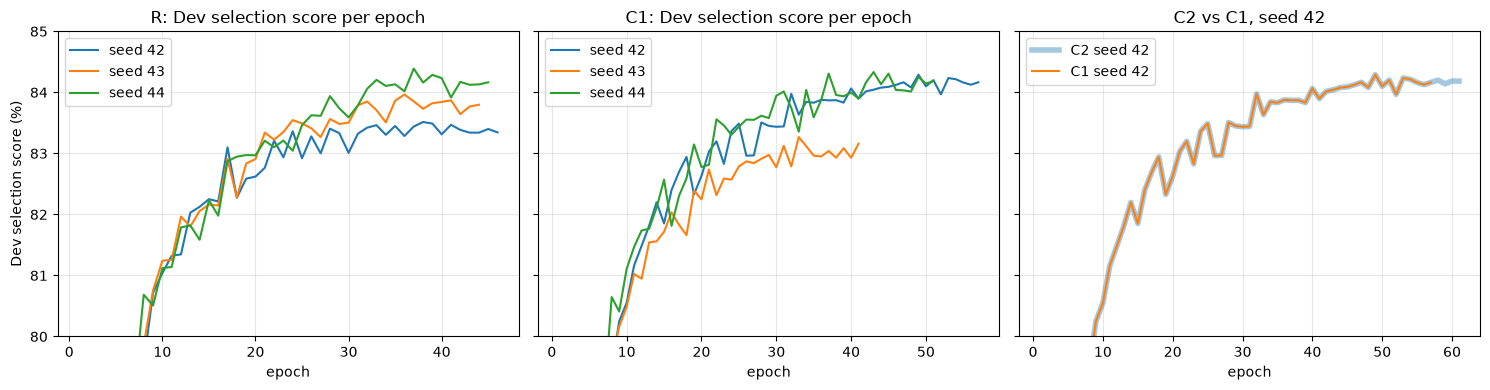

C2 repeats C1 exactly for all 57 C1 epochs: True
C2 epochs after C1 stopped: 58: 84.20 (lr 1.6e-05), 59: 84.14 (lr 7.8e-06), 60: 84.19 (lr 7.8e-06), 61: 84.18 (lr 7.8e-06)


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes[:2], ("R", "C1")):
    for run, seed in zip(CORE_RUNS[name], SEEDS):
        h = history(run)
        ax.plot([e["epoch"] for e in h], [e["selection_score"] for e in h], label=f"seed {seed}")
    ax.set_title(f"{name}: Dev selection score per epoch")
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Dev selection score (%)")
c1, c2 = history(CORE_RUNS["C1"][0]), history(CORE_RUNS["C2"][0])
axes[2].plot([e["epoch"] for e in c2], [e["selection_score"] for e in c2], label="C2 seed 42", lw=4, alpha=0.4)
axes[2].plot([e["epoch"] for e in c1], [e["selection_score"] for e in c1], label="C1 seed 42")
axes[2].set_title("C2 vs C1, seed 42"); axes[2].set_xlabel("epoch"); axes[2].grid(alpha=0.3); axes[2].legend()
for ax in axes: ax.set_ylim(80, 85)
plt.tight_layout(); plt.show()

metrics = ("train_loss", "dev_loss", "intent_accuracy_pct", "slot_micro_f1_pct", "selection_score", "learning_rate")
same = all(all(a[k] == b[k] for k in metrics) for a, b in zip(c1, c2))
print(f"C2 repeats C1 exactly for all {len(c1)} C1 epochs: {same}")
print("C2 epochs after C1 stopped:", ", ".join(
    f"{int(e['epoch'])}: {e['selection_score']:.2f} (lr {e['learning_rate']:.1e})" for e in c2[len(c1):]))
assert same


## 2. Per-class diagnostics: what C1 traded

In [4]:
analysis = json.loads(EMBEDDED["files"]["results/role_d/c_analysis.json"]["text"])
print("C1 minus R by seed, Dev (points). Computed from the saved Dev predictions by "
      "scripts/d_c_analysis.py.\n")
print(f"{'seed':<6}{'rarest quarter':>16}{'most frequent quarter':>24}{'general_quirky F1':>20}{'qa_factoid F1':>16}")
for seed in map(str, SEEDS):
    r, c = analysis["runs"]["R"][seed], analysis["runs"]["C1"][seed]
    rare = c["accuracy_by_train_frequency"]["rarest_quarter"]["dev_accuracy_pct"] - r["accuracy_by_train_frequency"]["rarest_quarter"]["dev_accuracy_pct"]
    freq = c["accuracy_by_train_frequency"]["most_frequent_quarter"]["dev_accuracy_pct"] - r["accuracy_by_train_frequency"]["most_frequent_quarter"]["dev_accuracy_pct"]
    gq = c["watched_intent_f1_pct"]["general_quirky"] - r["watched_intent_f1_pct"]["general_quirky"]
    qa = c["watched_intent_f1_pct"]["qa_factoid"] - r["watched_intent_f1_pct"]["qa_factoid"]
    print(f"{seed:<6}{rare:>+16.2f}{freq:>+24.2f}{gq:>+20.2f}{qa:>+16.2f}")
support = analysis["runs"]["R"]["42"]["accuracy_by_train_frequency"]
print(f"\nDev support: rarest quarter {support['rarest_quarter']['dev_support']}, "
      f"most frequent quarter {support['most_frequent_quarter']['dev_support']} utterances")


C1 minus R by seed, Dev (points). Computed from the saved Dev predictions by scripts/d_c_analysis.py.

seed    rarest quarter   most frequent quarter   general_quirky F1   qa_factoid F1
42               +2.75                   -1.21               -3.07           +1.62
43               +4.59                   -1.47               -7.56           -3.52
44               +1.83                   -1.38               -2.91           -2.20

Dev support: rarest quarter 109, most frequent quarter 1157 utterances


## 3. Design sensitivity sweep

Dev only; it does not change the frozen Stage 1 or Stage 2 systems. A depth or width counts as within reach of the best 3-seed mean if it is no further below it than the larger of the two seed SDs; the smallest such model is preferred. A component has a consistent gain if removing it lowers the score on all three seeds.

Depth (BiLSTM layers, width 128)
     1: params   907,002  score 83.96 (SD 0.44)  seeds 83.51, 83.96, 84.39
     2: params 1,302,266  score 83.98 (SD 0.32)  seeds 83.66, 83.97, 84.30
     3: params 1,697,530  score 83.32 (SD 0.14)  seeds 83.48, 83.20, 83.27
  best mean = 2; current (1) supported: True; preferred = 1

Width (hidden size per direction, 1 layer)
    64: params   694,138  score 83.16 (SD 0.40)  seeds 83.61, 82.89, 82.97
   128: params   907,002  score 83.96 (SD 0.44)  seeds 83.51, 83.96, 84.39
   256: params 1,529,338  score 84.39 (SD 0.03)  seeds 84.35, 84.40, 84.41
  best mean = 256; current (128) supported: True; preferred = 128

Character CNN and word dropout (full recipe minus reduced recipe, by seed)
  character CNN    -0.28, +0.34, +0.40  mean +0.15  -> average gain only
  word dropout     +0.27, +1.75, +1.23  mean +1.08  -> consistent gain
  both vs neither  +1.22, +2.32, +1.57  mean +1.70  -> consistent gain


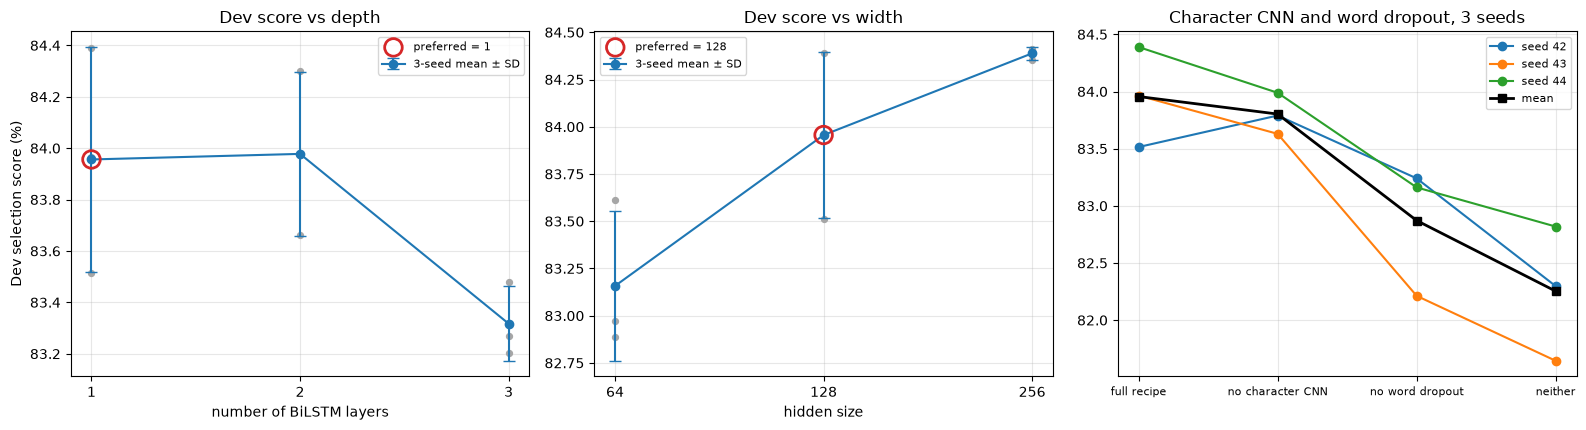

In [5]:
if not SWEEP_READY:
    print("Sweep runs not finished when this notebook was built; this section is filled in on rebuild.")
else:
    R = CORE_RUNS["R"]
    depth = {1: R, 2: SWEEP_RUNS["layers2"], 3: SWEEP_RUNS["layers3"]}
    width = {64: SWEEP_RUNS["hidden64"], 128: R, 256: SWEEP_RUNS["hidden256"]}
    ablation = {"full recipe": R, "no character CNN": SWEEP_RUNS["nochar"],
                "no word dropout": SWEEP_RUNS["nowd"], "neither": SWEEP_RUNS["neither"]}

    def stats(runs):
        scores = [row(r)["score"] for r in runs]
        m, sd = mean_sd(scores)
        return {"scores": scores, "mean": m, "sd": sd, "params": row(runs[0])["params"]}

    def choose(sweep, current):  # rule 2 of the sweep plan
        s = {k: stats(v) for k, v in sweep.items()}
        best = max(s, key=lambda k: s[k]["mean"])
        beaten = [k for k in s if s[k]["mean"] - s[current]["mean"] > max(s[k]["sd"], s[current]["sd"])]
        near = [k for k in s if s[best]["mean"] - s[k]["mean"] <= max(s[k]["sd"], s[best]["sd"])]
        return s, best, beaten, min(near, key=lambda k: s[k]["params"])

    def plot(s, preferred, xlabel, title, ax, log2=False):
        xs = sorted(s)
        for x in xs:
            ax.scatter([x] * 3, s[x]["scores"], color="0.65", s=18, zorder=2)
        ax.errorbar(xs, [s[x]["mean"] for x in xs], yerr=[s[x]["sd"] for x in xs], marker="o",
                    capsize=4, zorder=3, label="3-seed mean ± SD")
        ax.scatter([preferred], [s[preferred]["mean"]], s=160, facecolors="none", edgecolors="C3",
                   linewidths=2, zorder=4, label=f"preferred = {preferred}")
        if log2:
            ax.set_xscale("log", base=2)
        ax.set_xticks(xs); ax.set_xticklabels([str(x) for x in xs])
        ax.set_xlabel(xlabel); ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for label, sweep, current, ax, xlabel, log2 in (
        ("Depth (BiLSTM layers, width 128)", depth, 1, axes[0], "number of BiLSTM layers", False),
        ("Width (hidden size per direction, 1 layer)", width, 128, axes[1], "hidden size", True),
    ):
        s, best, beaten, preferred = choose(sweep, current)
        print(label)
        for k in sorted(s):
            print(f"  {k:>4}: params {s[k]['params']:>9,}  score {s[k]['mean']:.2f} (SD {s[k]['sd']:.2f})  "
                  f"seeds {', '.join(f'{x:.2f}' for x in s[k]['scores'])}")
        print(f"  best mean = {best}; current ({current}) supported: {not beaten}; preferred = {preferred}\n")
        plot(s, preferred, xlabel, f"Dev score vs {label.split(' (')[0].lower()}", ax, log2)
    axes[0].set_ylabel("Dev selection score (%)")

    print("Character CNN and word dropout (full recipe minus reduced recipe, by seed)")
    full = stats(ablation["full recipe"])
    for name, reduced in (("character CNN", "no character CNN"), ("word dropout", "no word dropout"),
                          ("both vs neither", "neither")):
        red = stats(ablation[reduced])
        diffs = [f - r for f, r in zip(full["scores"], red["scores"])]
        verdict = ("consistent gain" if all(d > 0 for d in diffs)
                   else "average gain only" if statistics.mean(diffs) > 0 else "no gain")
        print(f"  {name:<16} {', '.join(f'{d:+.2f}' for d in diffs)}  mean {statistics.mean(diffs):+.2f}  -> {verdict}")
    names = list(ablation)
    for i, seed in enumerate(SEEDS):
        axes[2].plot(range(4), [stats(ablation[n])["scores"][i] for n in names], marker="o", label=f"seed {seed}")
    axes[2].plot(range(4), [stats(ablation[n])["mean"] for n in names], marker="s", color="black", lw=2, label="mean")
    axes[2].set_xticks(range(4)); axes[2].set_xticklabels(names, fontsize=8)
    axes[2].set_title("Character CNN and word dropout, 3 seeds"); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()
